# IT8414 – Tomato Leaf Disease Classification

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Eman-271/IT8414-Tomato-Leaf-Disease-Classification/blob/main/notebook/IT8414_Tomato_Leaf_Classification_Final.ipynb) **Runtime → Run all** is all that is needed: Cell 1.0 downloads the data, the official split and the saved models from GitHub.
**Group 01** · Authors: **Fatema** (Member 1, cells 1.0–5.9), **Eman Khamdan** (Member 2, cells 6.0–7.7), **Abrar Alawadhi** (Member 3, cells 8.0–10.0). Every code cell starts with an `# Author:` tag.

Classes: Healthy · Early Blight · Late Blight (PlantVillage). Run with **Runtime → Restart session and run all**.

| Sections | Owner | Content |
|---|---|---|
| 1.0 – 5.9 | Fatema (Member 1) | Setup, data, EDA (incl. class-choice evidence), preprocessing, split-ratio experiment, final split, baseline CNN, baseline tuning, baseline test evaluation |
| 6.0 – 7.7 | Eman Khamdan (Member 2) | Data check, workflow diagram, MobileNetV2 transfer learning, tuning (5 hyperparameters, 10 runs), overfitting-control ablation, final improved model, Grad-CAM activation model |
| 8.0 – 10.0 | Abrar Alawadhi (Member 3)| Final test evaluation, error analysis, interpretability, conclusion |

**One split for every model:** sections 1.0–4.0 load the *saved* split manifests, so every model uses exactly the same training, validation and test images.

### The whole pipeline at a glance

| Step | What happens | Cell | Output |
|---|---|---|---|
| 1 | Environment, fixed seed 42, Kaggle download unzipped | 1.0 | `data/original/` |
| 2 | The three tomato class folders found and counted | 2.0 | class counts |
| 3 | EDA: class balance, sample images, **colour evidence for the class choice** | 3.0 | Figures 3.1 – 3.3 |
| 4 | Balanced subset (100 per class, approved by the tutor), quality check | 4.0 | `data/selected/` |
| 5 | Preprocessing (decode → resize 224 → ÷255 → batch) and training-only augmentation | 4.0 | Figures 3.4 – 3.5 |
| 6 | Baseline CNN and the training helper with early stopping | 5.1 – 5.2 | – |
| 7 | **Split-ratio experiment**: 70/15/15 vs 80/10/10 vs 60/20/20, three random splits each, validation only | 5.3 | Figure 3.6, `split_ratio_comparison.csv` |
| 8 | Final stratified split with the chosen ratio, leakage checks, saved manifests | 5.4 | `data/split_manifests/` |
| 9 | Hyperparameter experiments on the final split (batch, learning rate, kernel), validation only | 5.5 – 5.6 | Figure D.1, results table |
| 10 | Final baseline: learning curves, saved model | 5.7 | Figure 5.1, `baseline_cnn_final.keras` |
| 11 | One-time test-set evaluation, bootstrap CIs, live-demo prediction | 5.8 | Figure 5.4, `baseline_test_results.json` |
| 12 | Baseline summary, saved numbers, optional download | 5.9 | `NUMBERS_FOR_REPORT.txt` |
| 13 | Improved model: data check, workflow diagram, MobileNetV2 architecture and training helper | 6.0 – 6.2 | Figure 4.1, `improved_layer_table.csv` |
| 14 | Improved-model tuning (5 hyperparameters, 10 runs), validation only, with observations | 7.1 – 7.3 | Figure D.2, Table 5.2 |
| 15 | Overfitting-control ablation and final improved model learning curves | 7.4 – 7.5 | Figures 5.2 – 5.3, `improved_mobilenetv2_final.keras` |
| 16 | One-time test evaluation of both models, confusion matrices, per-class results | 8.0 – 8.3 | Table 5.4, Figure 5.5 |
| 17 | Error analysis, Grad-CAM for both models, live demo with explanation | 9.0 – 9.5 | Figures 5.6, 6.1 |
| 18 | Conclusion, deployment recommendation, limitations, ethics, future work | 10.0 | – |

**Where to find the learning curves:** baseline in 5.7 (Figure 5.1), improved model in 7.5 (Figure 5.2), each followed by a written interpretation.

## 1.0 Environment Setup

This section imports the libraries needed for data handling, visualization,
deep learning, and dataset splitting. It then sets up the project folders in
Colab (`data/`, `results/`) and gets the data automatically: if the project folder does not hold the
official split (checked by MD5 checksums), the project is downloaded from the team's GitHub repository
(images, split manifests, saved models and results), so **nothing has to be uploaded**. Only if that
download is not possible can the dataset be provided in one of two ways:

- **Option A:** upload our dataset ZIP (`tomato_original.zip`, or the
  Kaggle download `archive.zip`) to `/content` (Files panel), or choose it when the
  upload button appears. It is unzipped into
  `data/original/` and never changed.
- **Option B:** write the Kaggle dataset handle in `KAGGLE_DATASET`
  (for example `"owner/dataset-name"`), and the cell downloads it with `kagglehub`.

No Google Drive is needed.

**Offline (live demo laptop, no internet):** install `requirements.txt`, open this notebook from the
project's `notebook/` folder (or set the environment variable `IT8414_PROJECT_DIR` to the project
folder) and keep `tomato_original.zip` in the project folder. Cell 1.0 detects that it is not in
Colab, uses that folder instead of `/content`, and never tries to upload or download anything.

**Same numbers on every run:** GPU training is not bit-for-bit repeatable, so with
`M1_REUSE_SAVED = True` (Cell 5.2) the six tuning runs are loaded from `results/baseline_runs.json`
and the final model from `results/baseline_cnn_final.keras` whenever a saved run with exactly the
same settings exists. Change any setting (for example the learning rate in the live demo), or set
`M1_REUSE_SAVED = False`, and the model is trained again.

**Recommended:** Runtime → Change runtime type → **T4 GPU**, then
Runtime → **Run all**. Colab storage is temporary; the results used in the report are already in
the GitHub repository, and cells 5.9 and 7.7 can download a ZIP of any newly trained results.

A fixed random seed (42) is set with `tf.keras.utils.set_random_seed`, which
seeds Python, NumPy and TensorFlow together. The same seed is set again before
every model is built, so each experiment starts from the same weights and the
same data order.

In [ ]:
# Author: Abrar
# Keras 3.15.1 is needed to load Member 2's saved MobileNetV2 model (saved with Keras 3.15.1).
# requirements.txt pins the same version for the offline demo laptop.
import importlib.util
if importlib.util.find_spec("google.colab") is not None:     # only in Colab; offline: requirements.txt
    !pip install -q keras==3.15.1

In [ ]:
# Author: Fatema
# Cell 1.0 - Environment Setup

import os
import sys
import time
import random
import zipfile
import shutil
import json
from pathlib import Path
from PIL import Image

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
import tensorflow as tf
import keras

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Fixed random seed for reproducibility (seeds Python, NumPy and TensorFlow)
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Show library versions (also recorded in README.md)
print("Python version:", sys.version.split()[0])
print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)
print("NumPy version:", np.__version__)
print("pandas version:", pd.__version__)
print("scikit-learn version:", sklearn.__version__)

# Check available hardware
print("GPU available:", tf.config.list_physical_devices('GPU'))

Python version: 3.13.18
TensorFlow version: 2.21.0
Keras version: 3.15.1
NumPy version: 2.4.6
pandas version: 2.2.3
scikit-learn version: 1.6.1
GPU available: []


In [ ]:
# Author: Fatema
# Cell 1.0 - Project Folders and Data (Google Colab or an offline computer; nothing to upload)

import hashlib
import subprocess

try:
    from google.colab import files     # only exists in Google Colab
    IN_COLAB = True
except ImportError:
    files = None
    IN_COLAB = False

# Project folder. Colab: /content/IT8414_Tomato_Project. Any other computer (for example the
# offline demo laptop): the environment variable IT8414_PROJECT_DIR if it is set, otherwise the
# folder above notebook/ when the notebook is opened from the project's notebook/ folder.
if os.environ.get("IT8414_PROJECT_DIR"):
    PROJECT_DIR = Path(os.environ["IT8414_PROJECT_DIR"]).resolve()
elif IN_COLAB:
    PROJECT_DIR = Path("/content/IT8414_Tomato_Project")
elif Path.cwd().name == "notebook":
    PROJECT_DIR = Path.cwd().parent
else:
    PROJECT_DIR = Path.cwd() / "IT8414_Tomato_Project"
UPLOAD_DIR = Path("/content") if IN_COLAB else PROJECT_DIR.parent   # where uploaded ZIPs are looked for

DOWNLOAD_PATH = PROJECT_DIR / "data" / "original"         # unzipped Kaggle download (never changed)
SELECTED_PATH = PROJECT_DIR / "data" / "selected"         # balanced 100-per-class subset
SPLIT_PATH = PROJECT_DIR / "data" / "split_manifests"     # train / validation / test CSV files
RESULTS_PATH = PROJECT_DIR / "results"                    # saved model, figures and tables
FIGURES_PATH = RESULTS_PATH / "figures"

# ---- Get the project files automatically: nothing has to be uploaded ----
# The official 80/10/10 split is identified by the MD5 checksums of its three manifests. If the
# project folder does not hold exactly these files, the project is downloaded from the team's
# public GitHub repository (data, split manifests, saved models and results). A share ZIP that
# is already in the upload folder is tried first. A wrong or old folder is renamed, never used.
REPO_URL = "https://github.com/Eman-271/IT8414-Tomato-Leaf-Disease-Classification.git"
REPO_BRANCH = os.environ.get("IT8414_REPO_BRANCH", "main")
OFFICIAL_SPLIT_MD5 = {
    "train_split.csv": "cfee4ba34460dc51ff09b0f58c1b9b82",
    "validation_split.csv": "6b639291b1ade2753434ab390f150463",
    "test_split.csv": "62e2aabbf5121b62114908edd42aeb40"
}


def official_split_present(folder=PROJECT_DIR):
    manifests = folder / "data" / "split_manifests"
    return all((manifests / name).exists()
               and hashlib.md5((manifests / name).read_bytes().replace(b"\r\n", b"\n")).hexdigest() == md5
               for name, md5 in OFFICIAL_SPLIT_MD5.items())


if not official_split_present():
    # 1. A share ZIP that is already there (optional; the newest one is used)
    share_zips = sorted(UPLOAD_DIR.glob("*_Share*.zip"), key=lambda z: z.stat().st_mtime, reverse=True)
    if share_zips and not PROJECT_DIR.exists():
        with zipfile.ZipFile(share_zips[0]) as z:
            z.extractall(UPLOAD_DIR)
        print("Share package unzipped from:", share_zips[0].name)

if not official_split_present():
    # 2. Download the project from GitHub (about 150 MB, under a minute in Colab)
    if PROJECT_DIR.exists():
        old = PROJECT_DIR.with_name(PROJECT_DIR.name + "_old_" + time.strftime("%Y%m%d_%H%M%S"))
        PROJECT_DIR.rename(old)
        print("The project folder did not hold the official split; moved it aside to:", old)
    print("Downloading the project from GitHub:", REPO_URL)
    clone = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(PROJECT_DIR)],
                           capture_output=True, text=True)
    if clone.returncode != 0:
        raise RuntimeError("Could not download the project from GitHub (no internet?).\n" + clone.stderr +
                           "\nOffline: copy the project folder (a clone of the repository) to this computer.")

if not official_split_present():
    raise RuntimeError("The official 80/10/10 split manifests are missing or changed in " + str(PROJECT_DIR))
print("Official 80/10/10 split manifests found (checksums match).")

for folder in [SPLIT_PATH, RESULTS_PATH, FIGURES_PATH]:
    folder.mkdir(parents=True, exist_ok=True)

# Option B: Kaggle dataset handle, e.g. "owner/dataset-name". Leave empty to use a ZIP (Option A).
# Option B needs internet, so leave it empty on the offline demo laptop.
KAGGLE_DATASET = ""

DOWNLOAD_PATH.mkdir(parents=True, exist_ok=True)
has_images = any(f.suffix.lower() in {".jpg", ".jpeg", ".png"} for f in DOWNLOAD_PATH.rglob("*"))

if not has_images:
    if KAGGLE_DATASET:
        # Option B: download with kagglehub and copy it into data/original
        import kagglehub
        downloaded = Path(kagglehub.dataset_download(KAGGLE_DATASET))
        shutil.copytree(downloaded, DOWNLOAD_PATH / "kaggle_download", dirs_exist_ok=True)
        print("Dataset downloaded from Kaggle:", KAGGLE_DATASET)
    else:
        # Option A: unzip the dataset ZIP once (data/original/tomato_original.zip comes with the
        # repository; an uploaded tomato_original.zip or Kaggle archive.zip also works)
        search_dirs = [DOWNLOAD_PATH, PROJECT_DIR] + ([UPLOAD_DIR] if IN_COLAB else [])
        zips = [z for d in search_dirs for z in sorted(d.glob("*.zip"))
                if not any(word in z.name.lower() for word in ("results", "member", "share"))]
        if not zips and IN_COLAB:
            print("Please upload the dataset ZIP (tomato_original.zip or the Kaggle archive.zip)")
            uploaded = files.upload()
            zips = [UPLOAD_DIR / name for name in uploaded]
        if not zips:
            raise FileNotFoundError(f"Put tomato_original.zip into {PROJECT_DIR} and run this cell again.")
        with zipfile.ZipFile(zips[0]) as z:
            z.extractall(DOWNLOAD_PATH)
        print("Dataset unzipped from:", zips[0].name)

print("Running in:", "Google Colab" if IN_COLAB else "local / offline mode")
print("Project folder:", PROJECT_DIR)


Official 80/10/10 split manifests found (checksums match).
Dataset unzipped from: tomato_original.zip
Running in: Google Colab
Project folder: /content/IT8414_Tomato_Project


## 2.0 Dataset Loading and Verification

This section loads the original tomato leaf images and verifies the selected
classes, number of images, and image file formats before preprocessing.

**Dataset source and licence**
- Original collection: PlantVillage (Hughes & Salathé, 2015).
- Downloaded from Kaggle: *plantvillage Tomato leaf dataset* by charu (2019) –
  https://www.kaggle.com/datasets/charuchaudhry/plantvillage-tomato-leaf-dataset
- Licence: **Apache License 2.0** (http://www.apache.org/licenses/LICENSE-2.0),
  the licence of the PlantVillage dataset, of which these tomato classes are part.
  The tutor confirmed that this dataset and licence may be used for the project. The data is used for
  non-commercial academic work only. The images are kept unmodified in the team's
  GitHub repository, which the Apache 2.0 licence allows with the licence and credit
  given, and the original PlantVillage authors are credited. Full details are in `documentation/DATA.md`.

The next cell lists every class folder in the download and then **finds the three
tomato folders automatically**, whatever their exact names are (for example
`Tomato___Early_blight`), so the cell still works if the folders are renamed.

**Why these three classes?**
- **Early Blight** (*Alternaria solani*) and **Late Blight** (*Phytophthora infestans*)
  both produce brown, dead (necrotic) patches on the leaf, so they look similar.
  Separating them is a fine-grained problem and makes the task genuinely challenging.
- **Healthy** leaves are the reference class: a screening tool must first say
  whether a leaf is diseased at all.
- Using three classes makes this a **multi-class** problem with one easy
  separation (healthy vs diseased) and one hard one (Early vs Late Blight).
- This choice is **checked with evidence from the images** in 3.0 (Figure 3.3):
  the colour of the two blights is measured and compared with Healthy leaves.

The selected classes are:
- Tomato Healthy
- Tomato Early Blight
- Tomato Late Blight

In [ ]:
# Author: Fatema
# Cell 2.0 - Dataset Loading and Verification

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}
CLASS_NAMES = ["Healthy", "Early Blight", "Late Blight"]   # label IDs 0, 1, 2


def count_images(folder):
    return len([f for f in folder.iterdir() if f.suffix.lower() in IMAGE_EXTENSIONS])


def matches_class(folder_name, class_name):
    # Recognise the tomato class from the folder name (works with _ or ___ in the name)
    name = folder_name.lower()
    if "tomato" not in name:
        return False
    if class_name == "Healthy":
        return "healthy" in name
    if class_name == "Early Blight":
        return "early" in name and "blight" in name
    return "late" in name and "blight" in name


def find_class_folders():
    # Every folder in the download that holds images of one of the three classes
    all_folders = [d for d in DOWNLOAD_PATH.rglob("*") if d.is_dir()]
    candidates = {name: [d for d in all_folders if matches_class(d.name, name) and count_images(d) > 0]
                  for name in CLASS_NAMES}
    for name, found in candidates.items():
        if not found:
            raise FileNotFoundError(f"No tomato {name} folder found in the download")

    # The three classes must come from the same parent folder. Some Kaggle archives
    # contain the data twice; then the copy with the most images is used.
    shared_parents = set.intersection(*[{d.parent for d in found} for found in candidates.values()])
    if not shared_parents:
        raise FileNotFoundError("The three tomato class folders are not in one folder")

    def folders_in(parent):
        return [next(d for d in candidates[name] if d.parent == parent) for name in CLASS_NAMES]

    best_parent = max(sorted(shared_parents), key=lambda p: sum(count_images(d) for d in folders_in(p)))
    if len(shared_parents) > 1:
        print(f"Note: the download holds {len(shared_parents)} copies; using {best_parent.relative_to(DOWNLOAD_PATH)}")
    return folders_in(best_parent)


class_folders = find_class_folders()

ORIGINAL_PATH = class_folders[0].parent
EXPECTED_CLASSES = [folder.name for folder in class_folders]   # real folder names, in label order
HAS_ORIGINAL = True

# Every class in the download (the three tomato classes are a subset)
all_classes = sorted(d.name for d in ORIGINAL_PATH.iterdir() if d.is_dir() and count_images(d) > 0)
print(f"Class folders in the download: {len(all_classes)}")
for name in all_classes:
    marker = "  <- used" if name in EXPECTED_CLASSES else ""
    print(f"   {name}: {count_images(ORIGINAL_PATH / name)} images{marker}")

print("\nDataset folder:", ORIGINAL_PATH.relative_to(PROJECT_DIR))
for display_name, folder in zip(CLASS_NAMES, class_folders):
    print(f"{display_name:13s} -> {folder.name}: {count_images(folder)} images")

# File formats of the three selected classes
formats = pd.Series([f.suffix.lower() for folder in class_folders for f in folder.iterdir()
                     if f.suffix.lower() in IMAGE_EXTENSIONS]).value_counts()
print("\nFile formats:", formats.to_dict())

Class folders in the download: 3
   Tomato___Early_blight: 800 images  <- used
   Tomato___Late_blight: 1527 images  <- used
   Tomato___healthy: 1273 images  <- used

Dataset folder: data/original
Healthy       -> Tomato___healthy: 1273 images
Early Blight  -> Tomato___Early_blight: 800 images
Late Blight   -> Tomato___Late_blight: 1527 images

File formats: {'.jpg': 3599, '.jpeg': 1}


## 3.0 Exploratory Data Analysis (EDA)

This section explores the original dataset before preprocessing.
The class distribution is visualized to identify whether the dataset is balanced
and to support later decisions about dataset selection and splitting.
Random sample images are shown to inspect image quality, backgrounds and
the visual difference between the classes. A third analysis measures the
colour of the leaves to **check the class choice with evidence** (Figure 3.3).

Tomato___healthy: 1273 images (35.4%)
Tomato___Early_blight: 800 images (22.2%)
Tomato___Late_blight: 1527 images (42.4%)
Imbalance ratio (largest / smallest class): 1.91


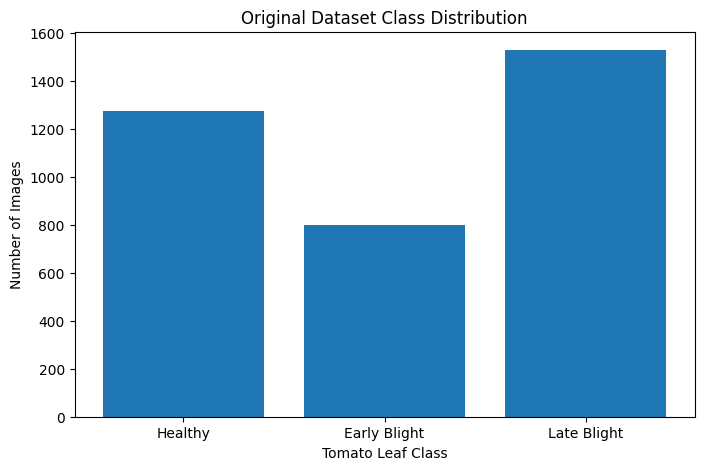

In [ ]:
# Author: Fatema
# Cell 3.0 - EDA: Class Distribution

if not HAS_ORIGINAL:
    print("Skipped: original images not available. Member 1 ran this EDA - see results/figures/fig3_1_class_distribution.png")
else:

    class_counts = {}

    for class_name in EXPECTED_CLASSES:
        class_path = ORIGINAL_PATH / class_name

        image_files = [
            file for file in class_path.iterdir()
            if file.suffix.lower() in IMAGE_EXTENSIONS
        ]

        class_counts[class_name] = len(image_files)

    # Print counts, share of the dataset and imbalance ratio
    total_images = sum(class_counts.values())

    for class_name, count in class_counts.items():
        print(f"{class_name}: {count} images ({count / total_images:.1%})")

    print("Imbalance ratio (largest / smallest class):",
          round(max(class_counts.values()) / min(class_counts.values()), 2))

    # Create a simple bar chart
    plt.figure(figsize=(8, 5))

    plt.bar(CLASS_NAMES, [class_counts[c] for c in EXPECTED_CLASSES])

    plt.title("Original Dataset Class Distribution")
    plt.xlabel("Tomato Leaf Class")
    plt.ylabel("Number of Images")
    plt.savefig(FIGURES_PATH / "fig3_1_class_distribution.png", dpi=150, bbox_inches="tight")
    plt.show()

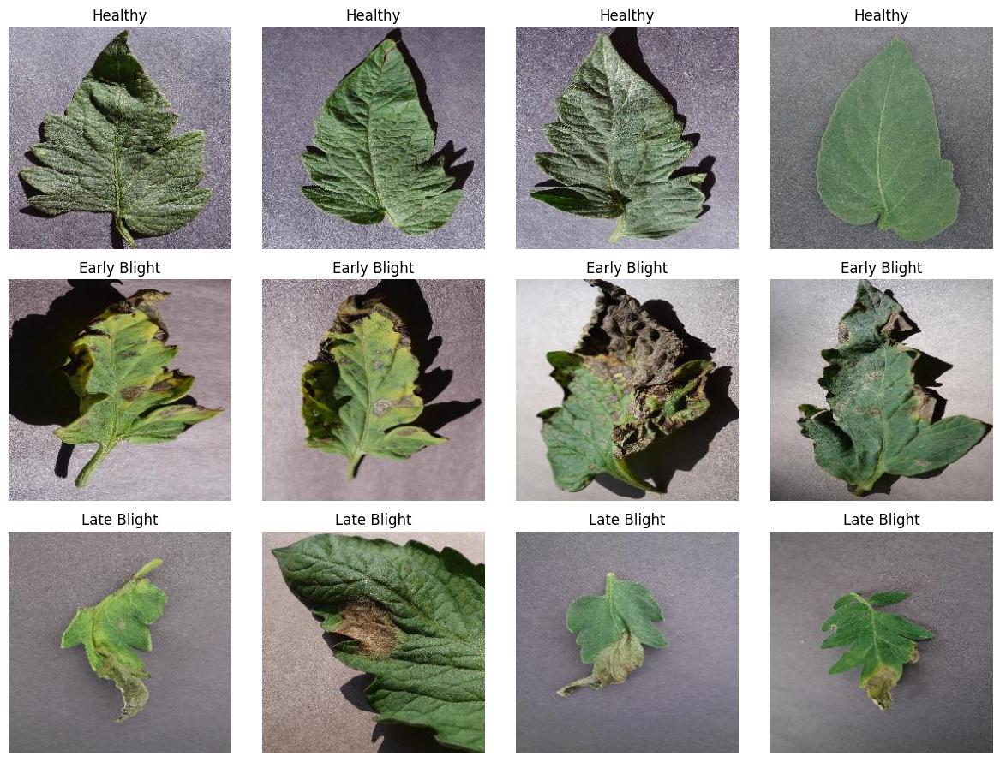

In [ ]:
# Author: Fatema
# Cell 3.0 - EDA: Multiple Sample Images

if not HAS_ORIGINAL:
    print("Skipped: original images not available. Member 1 ran this EDA - see results/figures/fig3_2_sample_images.png")
else:

    samples_per_class = 4
    sample_rng = random.Random(SEED)

    plt.figure(figsize=(12, 9))

    plot_position = 1

    for class_name in EXPECTED_CLASSES:
        class_path = ORIGINAL_PATH / class_name

        image_files = sorted([
            file for file in class_path.iterdir()
            if file.suffix.lower() in IMAGE_EXTENSIONS
        ])

        # Randomly choose sample images using the fixed seed
        sample_files = sample_rng.sample(image_files, samples_per_class)

        for image_path in sample_files:
            image = tf.keras.utils.load_img(image_path)

            plt.subplot(3, samples_per_class, plot_position)
            plt.imshow(image)

            display_name = CLASS_NAMES[EXPECTED_CLASSES.index(class_name)]
            plt.title(display_name)
            plt.axis("off")

            plot_position += 1

    plt.tight_layout()
    plt.savefig(FIGURES_PATH / "fig3_2_sample_images.png", dpi=150, bbox_inches="tight")
    plt.show()

### 3.0 Why Early Blight and Late Blight? Evidence from the images

The two diseases were chosen because they **look alike**, which makes the task a
fine-grained problem rather than a simple "green vs brown" decision. This claim
is tested here with a simple, transparent measurement on 150 random images per
class (seed 42):

1. **Leaf mask:** pixels that are clearly coloured (saturation > 0.20) and not dark
   (brightness > 0.15) are treated as leaf; the grey or black background is ignored.
2. **Lesion fraction:** the share of leaf pixels whose hue is brown/yellow
   (10°–55°). Healthy tissue is green (about 60°–150°).
3. **Colour profile:** an 18-bin hue histogram of the leaf pixels. The distance
   between two classes is half the sum of absolute differences between their
   average histograms (0 = identical colours, 1 = no colour in common).
4. **Colour-only classifier:** each image is assigned to the class whose average
   histogram is closest. If colour alone could separate the classes, a CNN would
   not be needed; where it fails shows which classes are genuinely hard.

Brown/yellow (lesion-coloured) share of the leaf, mean over 150 images:
   Healthy       0.8%
   Early Blight  14.7%
   Late Blight   18.7%

Colour-profile distance between classes (0 = identical, 1 = completely different):
   Healthy - Early Blight: 0.447
   Healthy - Late Blight: 0.294
   Early Blight - Late Blight: 0.261
Most similar pair: Early Blight - Late Blight

Colour-only classifier accuracy: 64.7% (rows = true class, columns = predicted)
              Healthy  Early Blight  Late Blight
Healthy           140             1            9
Early Blight       21            79           50
Late Blight        62            16           72


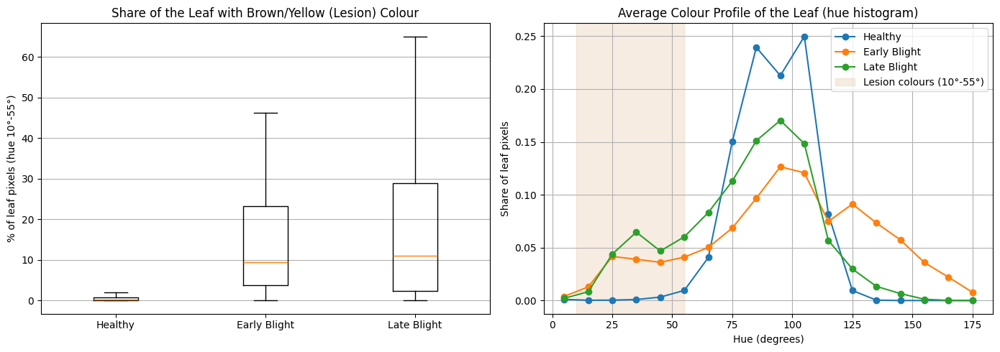

In [ ]:
# Author: Fatema
# Cell 3.0 - Evidence for the Class Choice: Lesion Colour and Class Similarity

N_EVIDENCE = 150   # random images per class
evidence_rng = random.Random(SEED)


def leaf_colour_features(image_path):
    # Convert to HSV (hue, saturation, value) at a small size for speed
    with Image.open(image_path) as img:
        hsv = np.asarray(img.convert("RGB").resize((128, 128)).convert("HSV"), dtype=np.float32)
    hue = hsv[..., 0] * 360 / 255          # PIL stores hue as 0-255 -> convert to degrees
    saturation = hsv[..., 1] / 255
    brightness = hsv[..., 2] / 255

    leaf_hue = hue[(saturation > 0.20) & (brightness > 0.15)]      # leaf pixels only
    lesion_fraction = float(np.mean((leaf_hue >= 10) & (leaf_hue <= 55))) if leaf_hue.size else 0.0
    histogram, _ = np.histogram(leaf_hue, bins=18, range=(0, 180))
    return lesion_fraction, histogram / max(histogram.sum(), 1)


lesion_fractions, hue_histograms = {}, {}
for folder_name, display_name in zip(EXPECTED_CLASSES, CLASS_NAMES):
    image_files = sorted(f for f in (ORIGINAL_PATH / folder_name).iterdir()
                         if f.suffix.lower() in IMAGE_EXTENSIONS)
    sample_files = evidence_rng.sample(image_files, min(N_EVIDENCE, len(image_files)))
    features = [leaf_colour_features(f) for f in sample_files]
    lesion_fractions[display_name] = np.array([f[0] for f in features])
    hue_histograms[display_name] = np.array([f[1] for f in features])

mean_histograms = {name: h.mean(axis=0) for name, h in hue_histograms.items()}
colour_distance = lambda a, b: 0.5 * np.abs(a - b).sum()

# 1. Lesion fraction per class
print("Brown/yellow (lesion-coloured) share of the leaf, mean over", N_EVIDENCE, "images:")
for name in CLASS_NAMES:
    print(f"   {name:13s} {lesion_fractions[name].mean():.1%}")

# 2. Colour distance between every pair of classes
pair_distances = {}
print("\nColour-profile distance between classes (0 = identical, 1 = completely different):")
for i in range(3):
    for j in range(i + 1, 3):
        a, b = CLASS_NAMES[i], CLASS_NAMES[j]
        pair_distances[f"{a} - {b}"] = round(float(colour_distance(mean_histograms[a], mean_histograms[b])), 3)
        print(f"   {a} - {b}: {pair_distances[f'{a} - {b}']}")
closest_pair = min(pair_distances, key=pair_distances.get)
print("Most similar pair:", closest_pair)

# 3. Colour-only nearest-average classifier
colour_cm = np.zeros((3, 3), dtype=int)
for i, name in enumerate(CLASS_NAMES):
    for h in hue_histograms[name]:
        distances = [colour_distance(h, mean_histograms[other]) for other in CLASS_NAMES]
        colour_cm[i, int(np.argmin(distances))] += 1
colour_accuracy = np.trace(colour_cm) / colour_cm.sum()
print(f"\nColour-only classifier accuracy: {colour_accuracy:.1%} (rows = true class, columns = predicted)")
print(pd.DataFrame(colour_cm, index=CLASS_NAMES, columns=CLASS_NAMES))

# Figure 3.3: lesion fraction (left) and average colour profile (right)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].boxplot([lesion_fractions[n] * 100 for n in CLASS_NAMES], showfliers=False)
axes[0].set_xticks([1, 2, 3], CLASS_NAMES)
axes[0].set_title("Share of the Leaf with Brown/Yellow (Lesion) Colour")
axes[0].set_ylabel("% of leaf pixels (hue 10°-55°)")
axes[0].grid(True, axis="y")

bin_centres = np.arange(5, 180, 10)
for name in CLASS_NAMES:
    axes[1].plot(bin_centres, mean_histograms[name], marker="o", label=name)
axes[1].axvspan(10, 55, color="peru", alpha=0.15, label="Lesion colours (10°-55°)")
axes[1].set_title("Average Colour Profile of the Leaf (hue histogram)")
axes[1].set_xlabel("Hue (degrees)")
axes[1].set_ylabel("Share of leaf pixels")
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "fig3_3_class_similarity.png", dpi=150, bbox_inches="tight")
plt.show()

class_evidence = {
    "images_per_class": N_EVIDENCE,
    "mean_lesion_fraction": {n: round(float(lesion_fractions[n].mean()), 4) for n in CLASS_NAMES},
    "colour_distance": pair_distances,
    "colour_only_confusion_matrix": colour_cm.tolist(),
    "colour_only_accuracy": round(float(colour_accuracy), 4),
}
with open(RESULTS_PATH / "class_choice_evidence.json", "w") as f:
    json.dump(class_evidence, f, indent=2)

**What the evidence shows** (values printed above: lesion-coloured share of the leaf
Healthy 0.8%, Early Blight 14.7%, Late Blight 18.7%; Early – Late Blight is the most
similar pair, distance 0.261; colour-only classifier 64.7%)

- **Both blights damage the leaf in the same colours.** A large share of their
  leaf area is brown/yellow, while Healthy leaves have almost none. Colour tells a
  diseased leaf from a healthy one, but it does not tell *which* blight it is.
- **Early and Late Blight are the most similar pair** of the three: the distance
  between their colour profiles is the smallest.
- **A colour-only classifier fails on exactly the classes we chose.** It
  recognises most Healthy leaves, but confuses Early Blight with Late Blight, and
  many Late Blight leaves with Healthy (Late Blight lesions are often small and
  pale near the leaf edge, so the leaf stays mostly green).

**Decision:** the class choice makes the task genuinely fine-grained. The model
must learn the **shape and texture** of the lesions (Early Blight: dark spots
with concentric rings; Late Blight: large irregular, water-soaked patches), not
just their colour. This also tells us what to look for later: most test errors
are expected **between the two blights**, and **Late Blight → Healthy** is the
costliest mistake to watch (5.8).

## 4.0 Data Preparation and Splitting

The EDA showed that the original classes are imbalanced (see the imbalance ratio
printed in 3.0). A balanced subset is therefore used:
100 images are selected from each class with a fixed random seed. This removes
class imbalance from the model comparison and keeps each training run short
enough to repeat for the hyperparameter experiments.
The 300-image balanced subset was approved by the tutor at the proposal stage.

The selected dataset contains 300 images in total:
- 100 Healthy
- 100 Early Blight
- 100 Late Blight

Steps in this section:
1. Copy the balanced subset (the original images are never modified).
2. Check that every selected image opens correctly and has the same size.
3. Define a **stratified split function** (`make_split`). The split ratio is not
   assumed: three ratios (70/15/15, 80/10/10, 60/20/20) are compared by experiment
   in **5.3**, once the baseline model exists, and the final split, the leakage
   checks and the saved manifests follow in **5.4**.
4. Build `tf.data` pipelines (decode → resize → normalise → batch).
5. Define training-only data augmentation.
6. Draw the complete data pipeline (Figure 3.4).

In [ ]:
# Author: Fatema
# Cell 4.0 - Balanced Dataset Selection

IMAGES_PER_CLASS = 100

# Set to True only if the balanced subset must be recreated from scratch.
# The selection is seeded, so recreating it gives exactly the same 300 images.
REBUILD_SELECTED = False


def selected_subset_complete():
    # True when every class folder already holds 100 images
    if not SELECTED_PATH.exists():
        return False
    for class_name in EXPECTED_CLASSES:
        class_path = SELECTED_PATH / class_name
        if not class_path.exists():
            return False
        n_images = len([f for f in class_path.iterdir() if f.suffix.lower() in IMAGE_EXTENSIONS])
        if n_images != IMAGES_PER_CLASS:
            return False
    return True


if selected_subset_complete() and not REBUILD_SELECTED:
    print("Balanced subset already exists - using the saved selection.")
    CLASSES_TO_BUILD = []
elif not HAS_ORIGINAL:
    raise FileNotFoundError(
        "data/selected is incomplete and data/original is missing. "
        "Ask Member 1 for the full shared ZIP, or download the Kaggle data (see documentation/DATA.md).")
else:
    # Remove any partial or old selection and build it again
    if SELECTED_PATH.exists():
        shutil.rmtree(SELECTED_PATH)
    SELECTED_PATH.mkdir(parents=True)
    CLASSES_TO_BUILD = EXPECTED_CLASSES

selection_rng = random.Random(SEED)

for class_name in CLASSES_TO_BUILD:

    source_path = ORIGINAL_PATH / class_name
    destination_path = SELECTED_PATH / class_name

    # Create a folder for each class
    destination_path.mkdir(exist_ok=True)

    # Find all valid image files (sorted so the selection is reproducible)
    image_files = sorted([
        file for file in source_path.iterdir()
        if file.suffix.lower() in IMAGE_EXTENSIONS
    ])

    # Randomly select 100 images
    selected_files = selection_rng.sample(
        image_files,
        IMAGES_PER_CLASS
    )

    # Copy the selected images
    for image_path in selected_files:
        shutil.copy2(
            image_path,
            destination_path / image_path.name
        )

    print(f"{class_name}: {len(selected_files)} images selected")

Balanced subset already exists - using the saved selection.


In [ ]:
# Author: Fatema
# Cell 4.0 - Create Dataset Table

data_records = []

for class_name in EXPECTED_CLASSES:
    class_path = SELECTED_PATH / class_name

    for image_path in sorted(class_path.iterdir()):
        if image_path.suffix.lower() in IMAGE_EXTENSIONS:
            data_records.append({
                "image_path": str(image_path),
                "label": class_name
            })

data_df = pd.DataFrame(data_records)

# Numeric label for every image: 0 = Healthy, 1 = Early Blight, 2 = Late Blight
LABEL_MAP = {folder: i for i, folder in enumerate(EXPECTED_CLASSES)}
data_df["label_id"] = data_df["label"].map(LABEL_MAP)

print("Total images:", len(data_df))
print("\nClass counts:")
print(data_df["label"].value_counts())

Total images: 300

Class counts:
label
Tomato___healthy         100
Tomato___Early_blight    100
Tomato___Late_blight     100
Name: count, dtype: int64


In [ ]:
# Author: Fatema
# Cell 4.0 - Image Quality and Size Check

image_sizes = set()
image_modes = set()
corrupted_images = []

for image_path in data_df["image_path"]:
    try:
        with Image.open(image_path) as img:
            image_sizes.add(img.size)
            image_modes.add(img.mode)
            img.verify()
    except Exception:
        corrupted_images.append(image_path)

print("Different image sizes found:", image_sizes)
print("Colour modes found:", image_modes)
print("Number of corrupted images:", len(corrupted_images))
print("Missing labels:", data_df["label"].isna().sum())

Different image sizes found: {(256, 256)}
Colour modes found: {'RGB'}
Number of corrupted images: 0
Missing labels: 0


In [ ]:
# Author: Fatema
# Cell 4.0 - Stratified Split Function and Saved Split

def make_split(df, ratio, seed=SEED):
    # Stratified two-step split. First the training share is taken off, then the
    # rest is divided into validation and test. Every part keeps 1/3 per class.
    train_share, val_share, test_share = ratio
    train_part, rest = train_test_split(
        df, train_size=train_share, stratify=df["label"], random_state=seed)
    val_part, test_part = train_test_split(
        rest, test_size=test_share / (val_share + test_share),
        stratify=rest["label"], random_state=seed)
    return (train_part.reset_index(drop=True),
            val_part.reset_index(drop=True),
            test_part.reset_index(drop=True))


# If the final split was already saved (in 5.4), load it, so that every member and
# every model uses exactly the same images. Otherwise it is created in 5.4.
USE_SAVED_SPLIT = True

manifest_files = {
    "train": SPLIT_PATH / "train_split.csv",
    "validation": SPLIT_PATH / "validation_split.csv",
    "test": SPLIT_PATH / "test_split.csv",
}


def load_manifest(csv_path):
    # Rebuild the full image path from the class label and file name,
    # so the manifest works on any computer
    frame = pd.read_csv(csv_path)
    if "filename" not in frame.columns:
        frame["filename"] = frame["image_path"].apply(lambda p: Path(p).name)
    frame["image_path"] = [
        str(SELECTED_PATH / label / name)
        for label, name in zip(frame["label"], frame["filename"])
    ]
    frame["label_id"] = frame["label"].map(LABEL_MAP)
    return frame[["image_path", "label", "label_id"]].reset_index(drop=True)


def saved_split_matches():
    # A saved split is reused only if it belongs to this dataset's class folders
    try:
        return set(pd.read_csv(manifest_files["train"])["label"]) == set(EXPECTED_CLASSES)
    except Exception:
        return False


SPLIT_LOADED = (USE_SAVED_SPLIT and not CLASSES_TO_BUILD
                and all(path.exists() for path in manifest_files.values())
                and saved_split_matches())

if SPLIT_LOADED:
    train_df = load_manifest(manifest_files["train"])
    val_df = load_manifest(manifest_files["validation"])
    test_df = load_manifest(manifest_files["test"])
    summary_file = SPLIT_PATH / "data_summary.json"
    SAVED_RATIO_NAME = (json.loads(summary_file.read_text()).get("split_ratio", "70/15/15")
                        if summary_file.exists() else "70/15/15")
    print(f"Saved split loaded (ratio {SAVED_RATIO_NAME}): "
          f"{len(train_df)} training / {len(val_df)} validation / {len(test_df)} test images")
else:
    print("No saved split yet: the split ratio is chosen in 5.3 and the final split is made in 5.4.")
    print("WARNING: the official split (80/10/10) was NOT loaded, so a NEW split would be made.\n"
          "Run Cell 1.0 again: it downloads the official split from GitHub automatically.")

Saved split loaded (ratio 80/10/10): 240 training / 30 validation / 30 test images


### 4.0 Preprocessing pipeline

Every image goes through the same steps:
1. **Decode** as a 3-channel RGB image.
2. **Resize** from 256 × 256 to 224 × 224 (the standard input size of ImageNet
   pre-trained networks, so the baseline and improved model can share this pipeline).
3. **Normalise** pixel values from 0–255 to 0–1.
4. **Cache** the processed images in memory (the dataset is small), then
   **shuffle** (training only), **batch** and **prefetch**.

The function takes the batch size as an argument so the batch-size experiment
uses exactly the same pipeline.

In [ ]:
# Author: Fatema
# Cell 4.0 - Image Preprocessing and Dataset Creation

# Image and training settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

AUTOTUNE = tf.data.AUTOTUNE


# Load, resize and normalize one image
def load_and_preprocess(image_path, label):

    # Read the image file
    image = tf.io.read_file(image_path)

    # Decode it as an RGB image
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # Resize to 224 x 224
    image = tf.image.resize(image, IMG_SIZE)

    # Convert pixels from 0-255 to 0-1
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


# Create a TensorFlow dataset
def make_dataset(df, training=False, batch_size=BATCH_SIZE):

    image_paths = df["image_path"].values
    labels = df["label_id"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    dataset = dataset.map(
        load_and_preprocess,
        num_parallel_calls=AUTOTUNE
    )

    # Keep the decoded images in memory after the first epoch
    dataset = dataset.cache()

    # Shuffle training data only
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# Check one batch (the training, validation and test datasets are made with this
# same function in 5.3 - 5.8, once the split is fixed)
images, labels = next(iter(make_dataset(data_df, training=True)))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:",
      float(tf.reduce_min(images)),
      "to",
      float(tf.reduce_max(images)))

print("Label mapping:", LABEL_MAP)

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Pixel range: 0.0 to 0.989496111869812
Label mapping: {'Tomato___healthy': 0, 'Tomato___Early_blight': 1, 'Tomato___Late_blight': 2}


### 4.0 Data augmentation

Augmentation is implemented as Keras preprocessing layers placed at the start
of the model. Keras only applies these random layers during training
(`training=True`); during validation, testing and prediction they pass images
through unchanged. Validation and test images are therefore never augmented.

A **function** creates the augmentation block so that every model gets a fresh
copy whose randomness is controlled by the seed.

In [ ]:
# Author: Fatema
# Cell 4.0 - Data Augmentation

def make_augmentation():
    return tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.1),   # up to +/-10% of a full turn (about +/-36 degrees)
        tf.keras.layers.RandomZoom(0.1)        # zoom in or out by up to 10%
    ], name="data_augmentation")


# One copy used only for the preview below
data_augmentation = make_augmentation()

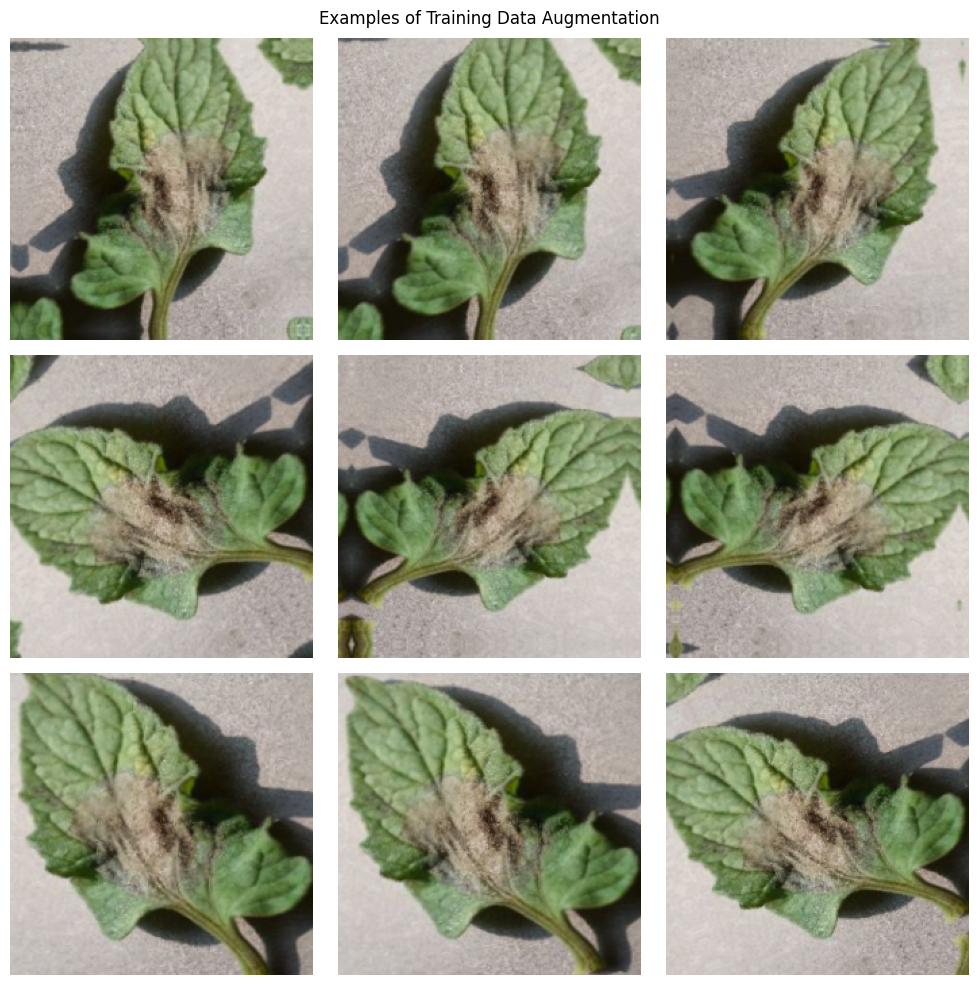

In [ ]:
# Author: Fatema
# Cell 4.0 - Augmentation Preview

sample_images, sample_labels = next(iter(make_dataset(data_df, training=True)))

sample_image = sample_images[0]

plt.figure(figsize=(10, 10))

for i in range(9):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, 0),
        training=True
    )

    plt.subplot(3, 3, i + 1)
    plt.imshow(augmented_image[0])
    plt.axis("off")

plt.suptitle("Examples of Training Data Augmentation")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "fig3_5_augmentation.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.0 The complete data pipeline

The diagram below shows every step from the Kaggle download to the three
datasets used for training, validation and testing, and which cell does it.

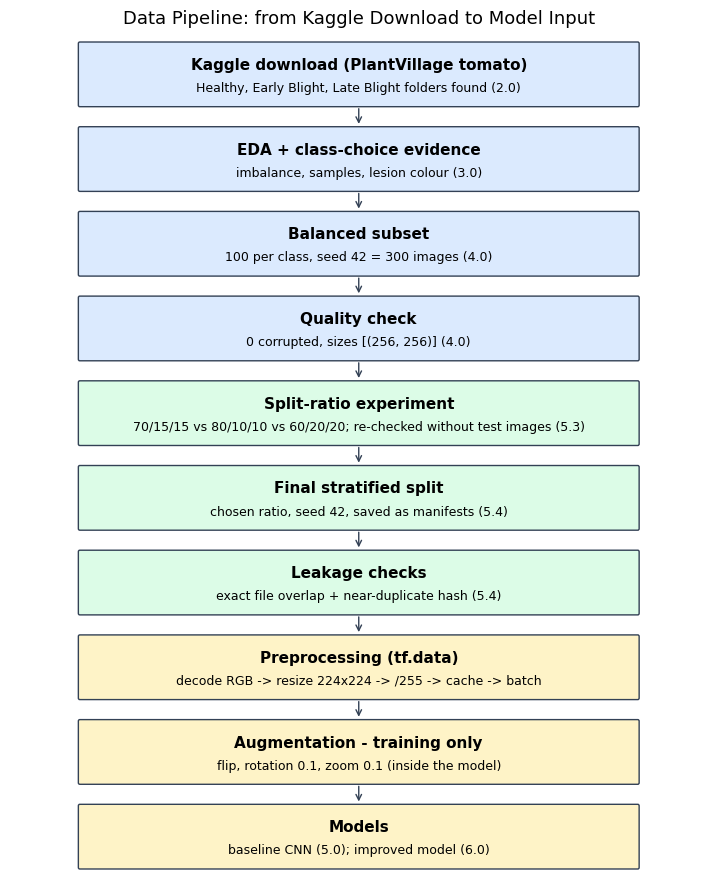

In [ ]:
# Author: Fatema
# Cell 4.0 - Data Pipeline Diagram (Figure 3.4)

from matplotlib.patches import FancyBboxPatch

steps = [
    ("Kaggle download (PlantVillage tomato)", "Healthy, Early Blight, Late Blight folders found (2.0)"),
    ("EDA + class-choice evidence", "imbalance, samples, lesion colour (3.0)"),
    ("Balanced subset", f"{IMAGES_PER_CLASS} per class, seed {SEED} = {len(data_df)} images (4.0)"),
    ("Quality check", f"{len(corrupted_images)} corrupted, sizes {sorted(image_sizes)} (4.0)"),
    ("Split-ratio experiment", "70/15/15 vs 80/10/10 vs 60/20/20; re-checked without test images (5.3)"),
    ("Final stratified split", "chosen ratio, seed 42, saved as manifests (5.4)"),
    ("Leakage checks", "exact file overlap + near-duplicate hash (5.4)"),
    ("Preprocessing (tf.data)", "decode RGB -> resize 224x224 -> /255 -> cache -> batch"),
    ("Augmentation - training only", "flip, rotation 0.1, zoom 0.1 (inside the model)"),
    ("Models", "baseline CNN (5.0); improved model (6.0)"),
]

fig, ax = plt.subplots(figsize=(9, 11))
ax.set_xlim(0, 10)
ax.set_ylim(0, len(steps) * 1.1)
ax.axis("off")
for k, (title, detail) in enumerate(steps):
    y = (len(steps) - 1 - k) * 1.1 + 0.15
    colour = "#dbeafe" if k < 4 else "#dcfce7" if k < 7 else "#fef3c7"
    ax.add_patch(FancyBboxPatch((1, y), 8, 0.8, boxstyle="round,pad=0.02", fc=colour, ec="#334155"))
    ax.text(5, y + 0.52, title, ha="center", va="center", fontsize=11, weight="bold")
    ax.text(5, y + 0.22, detail, ha="center", va="center", fontsize=9)
    if k < len(steps) - 1:
        ax.annotate("", xy=(5, y - 0.28), xytext=(5, y - 0.01),
                    arrowprops=dict(arrowstyle="->", color="#334155"))
ax.set_title("Data Pipeline: from Kaggle Download to Model Input", fontsize=13)
plt.savefig(FIGURES_PATH / "fig3_4_pipeline.png", dpi=150, bbox_inches="tight")
plt.show()

## 5.0 Baseline CNN Model

A custom Convolutional Neural Network (CNN) trained from scratch is used as the
baseline model. It learns visual features from tomato leaf images using
convolution and pooling layers before classifying each image as Healthy,
Early Blight, or Late Blight.

### 5.1 Architecture

- **Three convolution blocks** (32 → 64 → 128 filters, 3 × 3 kernels, ReLU).
  Early blocks detect simple patterns such as edges and colour changes; later
  blocks combine them into lesion and texture patterns.
- **Max-pooling** after each block halves the height and width, which reduces
  computation and makes features less sensitive to small shifts.
- **Global average pooling** turns the final 26 × 26 × 128 feature maps into a
  128-value vector. A `Flatten` layer would produce 86,528 values and about
  5.5 million weights in the next dense layer, which is far too many for
  240 training images.
- **Dense (64, ReLU)** combines the features, and **Dense (3, softmax)** outputs
  one probability per class.

The architecture is written as a function with the kernel size as an argument,
so the hyperparameter experiments in 5.5 build exactly the same network.
Layers are named (`conv1` … `output_softmax`) so they can be referred to
directly, e.g. `conv3` is the last convolution layer used for Grad-CAM.

In [ ]:
# Author: Fatema
# Cell 5.1 - Baseline CNN Architecture

def build_baseline_cnn(kernel_size=(3, 3)):

    model = tf.keras.Sequential([

        # Input images
        tf.keras.layers.Input(shape=(224, 224, 3)),

        # Apply augmentation only during training
        make_augmentation(),

        # First convolution block
        tf.keras.layers.Conv2D(
            32,
            kernel_size=kernel_size,
            activation="relu",
            name="conv1"
        ),
        tf.keras.layers.MaxPooling2D(name="pool1"),

        # Second convolution block
        tf.keras.layers.Conv2D(
            64,
            kernel_size=kernel_size,
            activation="relu",
            name="conv2"
        ),
        tf.keras.layers.MaxPooling2D(name="pool2"),

        # Third convolution block (last conv layer - used for Grad-CAM)
        tf.keras.layers.Conv2D(
            128,
            kernel_size=kernel_size,
            activation="relu",
            name="conv3"
        ),
        tf.keras.layers.MaxPooling2D(name="pool3"),

        # Convert feature maps into a smaller feature vector
        tf.keras.layers.GlobalAveragePooling2D(name="global_avg_pool"),

        # Fully connected layer
        tf.keras.layers.Dense(
            64,
            activation="relu",
            name="dense_64"
        ),

        # Final prediction layer
        tf.keras.layers.Dense(
            3,
            activation="softmax",
            name="output_softmax"
        )
    ], name="baseline_cnn")

    return model


build_baseline_cnn().summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,699 (397.26 KB)

 Trainable params: 101,699 (397.26 KB)

 Non-trainable params: 0 (0.00 B)

### 5.2 Training setup and overfitting control

| Setting | Value |
|---|---|
| Loss | Sparse categorical cross-entropy (integer labels, 3 classes) |
| Optimiser | Adam (learning rate tuned: 0.0001 / **0.001** / 0.003) |
| Batch size | Tuned: **8** / 16 / 32 |
| Kernel size | Tuned: **3 × 3** / 5 × 5 |
| Maximum epochs | 50 |
| Early stopping | `monitor="val_loss"`, `patience=5`, `restore_best_weights=True` |
| Seed | 42, reset before every model is built |

**Bold** = the value in the final baseline (Exp. 2, selected in 5.6). The reference run (Exp. 1) uses batch 16, learning rate 0.001 and 3 × 3 kernels.

**Why early stopping?** In a first round of experiments with a *fixed* number of
epochs (10 / 15 / 20), the best result came from the largest value tried
(20 epochs) while the model was still improving, so the best training length had
not been found. A fixed epoch budget is also unfair to settings that learn more
slowly: a smaller learning rate, or a bigger batch (fewer weight updates per epoch),
loses simply because it runs out of time. With early stopping, every run trains
until the validation loss has not improved for 5 epochs (maximum 50), and the
weights from the best epoch are restored. The number of epochs is therefore
chosen fairly for every configuration and reported as **Best epoch**.

**Regularisation:** the baseline's only regulariser is the training-time data
augmentation (flip, rotation, zoom). It has no dropout and no weight decay. Early
stopping is used here to choose the training length fairly. Further overfitting
control (dropout, regularisation, fine-tuning schedule) is part of the improved
model in Section 6.

**Validation set only:** early stopping, model selection and every tuning
decision use the **validation set only**. The test set is used once, in 5.8, after
the final configuration is fixed.

The helper `run_experiment()` below trains one fresh, seeded model with these
settings. It is used for the split-ratio experiment (5.3) and for every
hyperparameter experiment (5.5), so all runs are trained in exactly the same way.
**Saved runs and live changes.** With `M1_REUSE_SAVED = True` a numbered experiment is loaded
from `results/baseline_runs.json` only if **both** its settings (batch size, learning rate,
kernel, epochs, images) **and its code** are unchanged. `code_id()` fingerprints the source of
the data pipeline, the augmentation, `build_baseline_cnn()` and `run_experiment()`, so any edit,
for example another activation function, an extra dropout layer, or a different loss or
optimiser, makes the experiment train again instead of showing the old saved result.

In [ ]:
# Author: Fatema
# Cell 5.2 - Training Helper Functions (early stopping + experiment runner)

import hashlib
import inspect

MAX_EPOCHS = 50
PATIENCE = 5

# Reuse switch. GPU training is not bit-for-bit repeatable, so "Restart and run all" would
# otherwise change the reported numbers slightly. True: a numbered experiment (5.5) is loaded
# from results/baseline_runs.json when a saved run with exactly the same settings and images
# exists. A changed setting (e.g. a new learning rate in the live demo) is always trained.
# False: every experiment is trained again and the saved file is overwritten.
M1_REUSE_SAVED = True
BASELINE_RUNS_FILE = RESULTS_PATH / "baseline_runs.json"
HARDWARE = "T4 GPU" if tf.config.list_physical_devices("GPU") else "CPU"
# Fingerprint of the code that produced the saved runs (see code_id below). Runs saved later
# store their own fingerprint in baseline_runs.json.
REPORT_CODE_ID_M1 = "1dd6ca2f514c6af3bf5f06356fdd07e9"


def code_id(functions, extra=""):
    # Fingerprint of the code behind a run: data pipeline, model and training helper.
    # Any edit to these functions (another activation, an extra layer, a different loss or
    # optimiser, ...) changes the fingerprint, so a saved run is NOT re-used and the model
    # is trained again. Returns None if the source code cannot be read (then only the
    # settings are checked, as before).
    try:
        text = "\n".join(inspect.getsource(f).rstrip() for f in functions) + "\n" + extra
    except (OSError, TypeError):
        return None
    text = "\n".join(line.rstrip() for line in text.splitlines())
    return hashlib.md5(text.encode()).hexdigest()


class SavedHistory:
    # Stands in for a Keras History object when a run is loaded from file
    def __init__(self, history):
        self.history = history


def images_id(frame):
    # Short fingerprint of which images are in a split (class folder + file name)
    names = sorted(f"{label}/{Path(p).name}" for p, label in zip(frame["image_path"], frame["label"]))
    return hashlib.md5("\n".join(names).encode()).hexdigest()


def load_saved_runs():
    return json.loads(BASELINE_RUNS_FILE.read_text()) if BASELINE_RUNS_FILE.exists() else {}


class KeepBestWeights(tf.keras.callbacks.Callback):
    # Remembers the weights of the epoch with the lowest validation loss and puts
    # them back at the end of training - also if all 50 epochs run without stopping
    def on_train_begin(self, logs=None):
        self.best_val_loss = np.inf
        self.best_weights = None
        self.best_epoch = 0

    def on_epoch_end(self, epoch, logs=None):
        if logs["val_loss"] < self.best_val_loss:
            self.best_val_loss = logs["val_loss"]
            self.best_weights = self.model.get_weights()
            self.best_epoch = epoch + 1

    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)


def run_experiment(experiment, parameter, value,
                   batch_size=16, learning_rate=0.001, kernel_size=(3, 3),
                   train_data=None, val_data=None, seed=SEED, verbose=2):

    # By default the final split (train_df / val_df from 5.4) is used;
    # the split-ratio experiment (5.3) passes its own candidate split instead
    train_data = train_df if train_data is None else train_data
    val_data = val_df if val_data is None else val_data

    # Settings that define this run; a saved run is reused only if all of them match
    config = {"batch_size": batch_size, "learning_rate": learning_rate, "kernel_size": list(kernel_size),
              "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "seed": seed,
              "train_images": images_id(train_data), "validation_images": images_id(val_data)}
    numbered = isinstance(experiment, int)      # the split-ratio runs ("S") are not saved here
    saved = load_saved_runs().get(str(experiment)) if numbered else None
    # The code must be unchanged too: data pipeline, augmentation, architecture and this helper
    run_code = code_id([load_and_preprocess, make_dataset, make_augmentation, build_baseline_cnn, run_experiment],
                       f"IMG_SIZE={tuple(IMG_SIZE)}")
    same_code = run_code is None or run_code == (saved or {}).get("code_id", REPORT_CODE_ID_M1)
    if M1_REUSE_SAVED and saved is not None and saved["config"] == config and not same_code:
        print(f"Experiment {experiment}: the model or training code changed since the saved run - training again.")
    if M1_REUSE_SAVED and saved is not None and saved["config"] == config and same_code:
        print(f"Experiment {experiment}: loaded the saved run ({saved['hardware']}) - not retrained. "
              "Set M1_REUSE_SAVED = False to train it again.")
        print(saved["summary"])
        return saved["summary"], SavedHistory(saved["history"]), None

    # Same seed, same data pipeline and a fresh model for every experiment
    tf.keras.utils.set_random_seed(seed)
    exp_train_ds = make_dataset(train_data, training=True, batch_size=batch_size)
    exp_val_ds = make_dataset(val_data, batch_size=batch_size)

    model = build_baseline_cnn(kernel_size=kernel_size)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    # Stop when validation loss has not improved for 5 epochs; keep the best weights
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    keep_best = KeepBestWeights()

    start = time.time()
    run_history = model.fit(exp_train_ds, validation_data=exp_val_ds,
                            epochs=MAX_EPOCHS, callbacks=[early_stopping, keep_best],
                            verbose=verbose)
    train_time = time.time() - start

    h = run_history.history
    b = keep_best.best_epoch - 1          # index of the best epoch
    summary = {
        "Exp.": experiment,
        "Parameter varied": parameter,
        "Value": value,
        "Epochs run": len(h["loss"]),
        "Best epoch": keep_best.best_epoch,
        "Train acc.": round(h["accuracy"][b], 4),
        "Val. acc.": round(h["val_accuracy"][b], 4),
        "Train loss": round(h["loss"][b], 4),
        "Val. loss": round(h["val_loss"][b], 4),
        "Params": model.count_params(),
        "Train time (min)": round(train_time / 60, 1),
    }
    print(summary)
    if numbered:
        runs = load_saved_runs()
        runs[str(experiment)] = {"config": config, "summary": summary,
                                 "history": {k: [float(v) for v in vals] for k, vals in h.items()},
                                 "hardware": HARDWARE, "code_id": run_code}
        BASELINE_RUNS_FILE.write_text(json.dumps(runs, indent=1))
    return summary, run_history, model


# Containers for all experiments
experiment_results = []
experiment_histories = {}
experiment_models = {}
experiment_names = {}

### 5.3 Split-ratio experiment: which train / validation / test ratio?

The usual 70 / 15 / 15 ratio is **not assumed to be best**. With only 300
images, the ratio is a real trade-off:

- a **larger training share** (80 / 10 / 10) gives the model more examples to
  learn from, but leaves only 30 validation and 30 test images, so every score
  is noisier (one test image = 3.3 percentage points);
- a **larger evaluation share** (60 / 20 / 20) makes validation and test scores
  more reliable (one test image = 1.7 points), but leaves fewer training images.

**Method (validation set only):**
1. For each ratio, three different random stratified splits are made
   (split seeds 42, 7 and 2024), so the result does not depend on one lucky split.
2. On each split the **reference baseline** (batch 16, learning rate 0.001,
   3 × 3 kernels, early stopping) is trained on the training part and scored on
   the validation part. The test part of every candidate split is **never used**.
   The candidate splits are drawn from all 300 images, independently of the final
   split made in 5.4, so some of their validation images end up in the final test
   set. The check after this experiment counts them and repeats the comparison
   without them.
3. The ratios are compared on the **mean validation loss** over the three splits
   (lower is better); the standard deviation shows how much a ratio depends on
   the split.

**Selection rule (fixed before running):** the ratio with the lowest mean
validation loss wins. If another ratio is within **one standard error** of the
winner (standard error = SD / √3, the "one-standard-error rule" of Hastie et al.,
2009), the difference is treated as noise, and the ratio with the **larger
validation and test sets** is chosen among those, because it gives more reliable
evaluation. The chosen ratio is used for the final split (5.4) and for all
following experiments.

*Note:* this experiment trains 9 models (3 ratios × 3 splits). None of them is
kept; they are only used to choose the ratio.

Saved split loaded - showing the saved split-ratio comparison (not re-run).


,Ratio,Split seed,Train images,Validation images,Best epoch,Train acc.,Val. acc.,Val. loss
0,70/15/15,42,210,45,32,0.7810,0.8000,0.4579
1,70/15/15,7,210,45,22,0.7667,0.7778,0.4626
2,70/15/15,2024,210,45,20,0.8000,0.8000,0.4538
3,80/10/10,42,240,30,26,0.8125,0.8000,0.3727
4,80/10/10,7,240,30,22,0.7375,0.8000,0.4431
5,80/10/10,2024,240,30,15,0.7833,0.8000,0.4133
6,60/20/20,42,180,60,31,0.8222,0.8000,0.4336
7,60/20/20,7,180,60,33,0.7889,0.7833,0.4536
8,60/20/20,2024,180,60,13,0.6944,0.8500,0.4891


,train_images,val_images,mean_val_loss,sd_val_loss,mean_val_acc,sd_val_acc,mean_best_epoch
Ratio,,,,,,,
70/15/15,210,45,0.4581,0.0044,0.7926,0.0128,24.6667
80/10/10,240,30,0.4097,0.0353,0.8000,0.0000,21.0000
60/20/20,180,60,0.4588,0.0281,0.8111,0.0347,25.6667


Lowest mean validation loss: 80/10/10 (0.4097, SD 0.0353, SE 0.0204)
Ratios within one standard error of it (treated as a tie): ['80/10/10']
Chosen ratio: 80/10/10


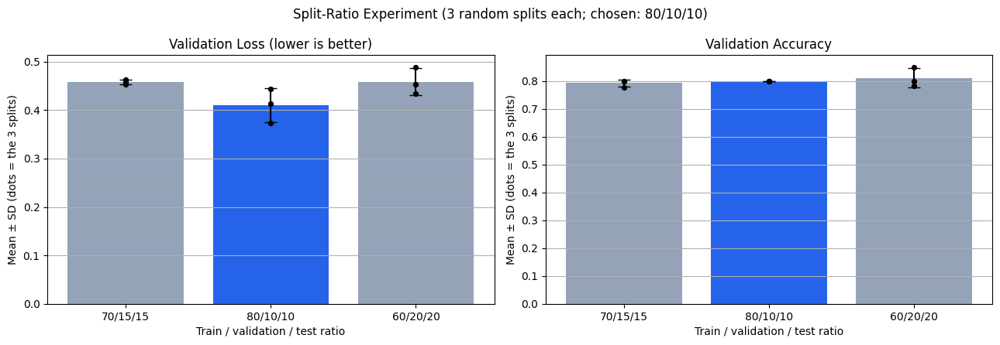

Ratio used for the final split: 80/10/10


In [ ]:
# Author: Fatema
# Cell 5.3 - Split-Ratio Experiment (validation set only)

SPLIT_CANDIDATES = {
    "70/15/15": (0.70, 0.15, 0.15),
    "80/10/10": (0.80, 0.10, 0.10),
    "60/20/20": (0.60, 0.20, 0.20),
}
SPLIT_SEEDS = [42, 7, 2024]    # three different random splits per ratio
split_comparison_csv = RESULTS_PATH / "split_ratio_comparison.csv"

if SPLIT_LOADED and split_comparison_csv.exists():
    # The final split already exists (loaded in 4.0): show the saved comparison only
    print("Saved split loaded - showing the saved split-ratio comparison (not re-run).")
    split_runs_df = pd.read_csv(split_comparison_csv)
elif SPLIT_LOADED:
    print("Saved split loaded, but no saved comparison found - the experiment is skipped.")
    split_runs_df = None
else:
    split_runs = []
    for ratio_name, ratio in SPLIT_CANDIDATES.items():
        for split_seed in SPLIT_SEEDS:
            cand_train, cand_val, _ = make_split(data_df, ratio, seed=split_seed)   # test part unused
            print(f"{ratio_name} | split seed {split_seed} | "
                  f"{len(cand_train)} training / {len(cand_val)} validation images")
            summary, _, _ = run_experiment("S", "Split ratio", ratio_name,
                                           train_data=cand_train, val_data=cand_val,
                                           seed=split_seed, verbose=0)
            split_runs.append({
                "Ratio": ratio_name,
                "Split seed": split_seed,
                "Train images": len(cand_train),
                "Validation images": len(cand_val),
                "Best epoch": summary["Best epoch"],
                "Train acc.": summary["Train acc."],
                "Val. acc.": summary["Val. acc."],
                "Val. loss": summary["Val. loss"],
            })
    split_runs_df = pd.DataFrame(split_runs)
    split_runs_df.to_csv(split_comparison_csv, index=False)

if split_runs_df is not None:
    display(split_runs_df)

    # Mean and standard deviation over the three splits of each ratio
    split_summary = split_runs_df.groupby("Ratio", sort=False).agg(
        train_images=("Train images", "first"),
        val_images=("Validation images", "first"),
        mean_val_loss=("Val. loss", "mean"),
        sd_val_loss=("Val. loss", "std"),
        mean_val_acc=("Val. acc.", "mean"),
        sd_val_acc=("Val. acc.", "std"),
        mean_best_epoch=("Best epoch", "mean"),
    ).round(4)
    display(split_summary)

    # Selection rule (validation only): lowest mean validation loss; ratios within
    # one standard error of it count as a tie -> prefer larger validation/test sets
    split_summary["se_val_loss"] = (split_summary["sd_val_loss"] / np.sqrt(len(SPLIT_SEEDS))).round(4)
    best_ratio = split_summary["mean_val_loss"].idxmin()
    tie_limit = split_summary.loc[best_ratio, "mean_val_loss"] + split_summary.loc[best_ratio, "se_val_loss"]
    tied = [r for r in split_summary.index if split_summary.loc[r, "mean_val_loss"] <= tie_limit]
    chosen = max(tied, key=lambda r: split_summary.loc[r, "val_images"])
    if not SPLIT_LOADED:
        CHOSEN_RATIO_NAME = chosen

    print(f"Lowest mean validation loss: {best_ratio} "
          f"({split_summary.loc[best_ratio, 'mean_val_loss']:.4f}, SD {split_summary.loc[best_ratio, 'sd_val_loss']:.4f}, "
          f"SE {split_summary.loc[best_ratio, 'se_val_loss']:.4f})")
    print("Ratios within one standard error of it (treated as a tie):", tied)
    print("Chosen ratio:", chosen)

    # Figure 3.6: mean ± SD of validation loss and accuracy, with the three splits as dots
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    ratios = list(split_summary.index)
    for ax, column, mean_col, sd_col, title in [
            (axes[0], "Val. loss", "mean_val_loss", "sd_val_loss", "Validation Loss (lower is better)"),
            (axes[1], "Val. acc.", "mean_val_acc", "sd_val_acc", "Validation Accuracy")]:
        colours = ["#2563eb" if r == chosen else "#94a3b8" for r in ratios]
        ax.bar(ratios, split_summary[mean_col], yerr=split_summary[sd_col], capsize=6, color=colours)
        for k, r in enumerate(ratios):
            values = split_runs_df.loc[split_runs_df["Ratio"] == r, column]
            ax.scatter([k] * len(values), values, color="black", zorder=3, s=18)
        ax.set_title(title)
        ax.set_ylabel("Mean ± SD (dots = the 3 splits)")
        ax.set_xlabel("Train / validation / test ratio")
        ax.grid(True, axis="y")
    fig.suptitle(f"Split-Ratio Experiment (3 random splits each; chosen: {chosen})")
    plt.tight_layout()
    plt.savefig(FIGURES_PATH / "fig3_6_split_ratio_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    split_summary = None

if SPLIT_LOADED:
    CHOSEN_RATIO_NAME = SAVED_RATIO_NAME
print("Ratio used for the final split:", CHOSEN_RATIO_NAME)

**Interpretation of the split-ratio experiment**

| Ratio | Training / validation images | Mean validation loss ± SD | Mean validation accuracy ± SD |
|---|---|---|---|
| 70/15/15 | 210 / 45 | 0.4581 ± 0.0044 | 79.26% ± 1.28% |
| **80/10/10** | **240 / 30** | **0.4097 ± 0.0353** | **80.00% ± 0.00%** |
| 60/20/20 | 180 / 60 | 0.4588 ± 0.0281 | 81.11% ± 3.47% |

- **80/10/10 had the lowest mean validation loss** (0.4097). Its standard error is
  0.0353 / √3 = 0.020, so the tie limit is 0.430. Both other ratios (0.458 and
  0.459) lie above it, so the difference counts as real and **80/10/10 is chosen**.
- 70/15/15 and 60/20/20 performed almost the same. 80/10/10 gave the model 30 more
  training images than 70/15/15, and with only 300 images this helped.
- Validation accuracy hardly separates the ratios (79–81%): with 30–60 validation
  images it moves in steps of 1.7–3.3 points, which is why the loss was used.
- **Trade-off:** the test set is now 30 images (10 per class), so one test image
  is worth 3.3 percentage points. The bootstrap intervals in 5.8 show this uncertainty.

**Decision based on validation data, with one caveat.** The candidate splits were drawn
independently of the final split, so their validation parts contain up to 15 of the 30
images that later became the final test set (counted in the next cell). No model was trained,
tuned or selected on the final test set itself, so the overlap could only have influenced the
choice of ratio. The next cell checks that the choice does not depend on those images.

### 5.3 Check: does the ratio choice hold without the final test images?

The candidate splits above were drawn from all 300 images, so their validation parts
overlap with the final test set of 5.4. To make sure the ratio was not chosen with the
help of test images, this cell

1. **counts** how many final-test images were in each candidate validation set, and
2. **repeats the comparison on the other 270 images** (the final test set removed
   first): same three ratios, same split seeds, same reference baseline and the same
   selection rule.

If the same ratio wins, the final test set had no influence on the choice. The runs are
saved in `results/split_ratio_check_without_test.csv` and reused when `M1_REUSE_SAVED`
is True.


In [ ]:
# Author: Fatema
# Cell 5.3 - Check: Final-Test Images in the Candidate Splits, and the Ratio Choice Without Them

def image_keys(frame):
    return set(f"{label}/{Path(p).name}" for p, label in zip(frame["image_path"], frame["label"]))

# The final test set: loaded from the manifests, or made now exactly as 5.4 will make it
if SPLIT_LOADED:
    final_test_df = test_df
else:
    _, _, final_test_df = make_split(data_df, SPLIT_CANDIDATES[CHOSEN_RATIO_NAME], seed=SEED)
final_test_keys = image_keys(final_test_df)

# 1. Overlap of every candidate validation set with the final test set
overlap_rows = []
for ratio_name, ratio in SPLIT_CANDIDATES.items():
    for split_seed in SPLIT_SEEDS:
        _, cand_val, _ = make_split(data_df, ratio, seed=split_seed)
        overlap_rows.append({"Ratio": ratio_name, "Split seed": split_seed,
                             "Validation images": len(cand_val),
                             "Of these in the final test set": len(image_keys(cand_val) & final_test_keys)})
overlap_df = pd.DataFrame(overlap_rows)
display(overlap_df)
print("Largest overlap:", overlap_df["Of these in the final test set"].max(), "of", len(final_test_df), "test images")

# 2. Repeat the comparison on the 270 images that are not in the final test set
pool_df = data_df[~data_df.apply(lambda r: f"{r['label']}/{Path(r['image_path']).name}" in final_test_keys,
                                 axis=1)].reset_index(drop=True)
print(f"\nPool without the final test images: {len(pool_df)} images")
split_check_csv = RESULTS_PATH / "split_ratio_check_without_test.csv"

if M1_REUSE_SAVED and split_check_csv.exists():
    print("Saved check loaded (not re-run). Set M1_REUSE_SAVED = False to run it again.")
    check_runs_df = pd.read_csv(split_check_csv)
else:
    check_runs = []
    for ratio_name, ratio in SPLIT_CANDIDATES.items():
        for split_seed in SPLIT_SEEDS:
            cand_train, cand_val, _ = make_split(pool_df, ratio, seed=split_seed)
            assert not (image_keys(cand_train) | image_keys(cand_val)) & final_test_keys
            summary, _, _ = run_experiment("S-check", "Split ratio", ratio_name,
                                           train_data=cand_train, val_data=cand_val,
                                           seed=split_seed, verbose=0)
            check_runs.append({"Ratio": ratio_name, "Split seed": split_seed,
                               "Train images": len(cand_train), "Validation images": len(cand_val),
                               "Best epoch": summary["Best epoch"], "Val. acc.": summary["Val. acc."],
                               "Val. loss": summary["Val. loss"], "Hardware": HARDWARE})
    check_runs_df = pd.DataFrame(check_runs)
    check_runs_df.to_csv(split_check_csv, index=False)

display(check_runs_df)
check_summary = check_runs_df.groupby("Ratio", sort=False).agg(
    train_images=("Train images", "first"), val_images=("Validation images", "first"),
    mean_val_loss=("Val. loss", "mean"), sd_val_loss=("Val. loss", "std"),
    mean_val_acc=("Val. acc.", "mean")).round(4)
check_summary["se_val_loss"] = (check_summary["sd_val_loss"] / np.sqrt(len(SPLIT_SEEDS))).round(4)
display(check_summary)

# Same selection rule as above
check_best = check_summary["mean_val_loss"].idxmin()
check_limit = check_summary.loc[check_best, "mean_val_loss"] + check_summary.loc[check_best, "se_val_loss"]
check_tied = [r for r in check_summary.index if check_summary.loc[r, "mean_val_loss"] <= check_limit]
check_chosen = max(check_tied, key=lambda r: check_summary.loc[r, "val_images"])
SPLIT_CHECK_AGREES = check_chosen == CHOSEN_RATIO_NAME
print("Lowest mean validation loss without test images:", check_best, "| tied:", check_tied)
print("Ratio chosen without test images:", check_chosen,
      "-> same as the chosen ratio" if SPLIT_CHECK_AGREES else f"-> DIFFERENT from {CHOSEN_RATIO_NAME}")


,Ratio,Split seed,Validation images,Of these in the final test set
0,70/15/15,42,45,15
1,70/15/15,7,45,5
2,70/15/15,2024,45,7
3,80/10/10,42,30,0
4,80/10/10,7,30,4
5,80/10/10,2024,30,3
6,60/20/20,42,60,14
7,60/20/20,7,60,9
8,60/20/20,2024,60,7


Largest overlap: 15 of 30 test images

Pool without the final test images: 270 images
Saved check loaded (not re-run). Set M1_REUSE_SAVED = False to run it again.


,Ratio,Split seed,Train images,Validation images,Best epoch,Val. acc.,Val. loss,Hardware
0,70/15/15,42,189,40,33,0.8750,0.4003,CPU
1,70/15/15,7,189,40,20,0.7500,0.5859,CPU
2,70/15/15,2024,189,40,27,0.8000,0.3343,CPU
3,80/10/10,42,216,27,29,0.8519,0.3192,CPU
4,80/10/10,7,216,27,22,0.8519,0.3516,CPU
5,80/10/10,2024,216,27,13,0.8889,0.4066,CPU
6,60/20/20,42,162,54,27,0.8333,0.3769,CPU
7,60/20/20,7,162,54,38,0.9074,0.3217,CPU
8,60/20/20,2024,162,54,15,0.7778,0.5950,CPU


,train_images,val_images,mean_val_loss,sd_val_loss,mean_val_acc,se_val_loss
Ratio,,,,,,
70/15/15,189,40,0.4402,0.1305,0.8083,0.0753
80/10/10,216,27,0.3591,0.0442,0.8642,0.0255
60/20/20,162,54,0.4312,0.1445,0.8395,0.0834


Lowest mean validation loss without test images: 80/10/10 | tied: ['80/10/10']
Ratio chosen without test images: 80/10/10 -> same as the chosen ratio


**Result of the check.** The candidate validation sets held 0–15 of the 30 final test images
(largest: 15 of 45 for 70/15/15, seed 42). Without those 30 images, the comparison gives the same
answer:

| Ratio | Training / validation images | Mean validation loss ± SD |
|---|---|---|
| 70/15/15 | 189 / 40 | 0.4402 ± 0.1305 |
| **80/10/10** | **216 / 27** | **0.3591 ± 0.0442** |
| 60/20/20 | 162 / 54 | 0.4312 ± 0.1445 |

80/10/10 again has the lowest mean validation loss, and both alternatives lie above its tie limit
(0.3591 + 0.0442 / √3 = 0.385), so the same rule chooses **80/10/10**. The overlap therefore did not
influence the choice of ratio, and the final test set stays a fair, once-used estimate. (These nine
runs were made on CPU and are saved in `results/split_ratio_check_without_test.csv`; delete that file
to repeat them on the GPU.)


### 5.4 Final split with the chosen ratio, leakage checks and saved manifests

The 300 images are now split **once** with the chosen ratio (stratified, seed 42).
This split is checked for leakage, saved as CSV manifests and used by every
model in the project (baseline and improved), so all models are trained,
tuned and tested on exactly the same images.

In [ ]:
# Author: Fatema
# Cell 5.4 - Final Train, Validation and Test Split (chosen ratio)

if SPLIT_LOADED:
    SPLIT_SOURCE = "loaded from the saved manifests"
else:
    train_df, val_df, test_df = make_split(data_df, SPLIT_CANDIDATES[CHOSEN_RATIO_NAME], seed=SEED)
    SPLIT_SOURCE = f"created with the chosen ratio {CHOSEN_RATIO_NAME} (stratified, seed {SEED})"

print("Split", SPLIT_SOURCE)

# Every manifest image must exist in the selected folder
missing_files = [p for df in (train_df, val_df, test_df) for p in df["image_path"] if not Path(p).exists()]
print("Missing image files:", len(missing_files))

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nImages per class in each split:")
display(pd.DataFrame({name: frame["label"].value_counts()
                      for name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]}))

Split loaded from the saved manifests
Missing image files: 0
Training images: 240
Validation images: 30
Testing images: 30

Images per class in each split:


,train,validation,test
label,,,
Tomato___Early_blight,80,10,10
Tomato___Late_blight,80,10,10
Tomato___healthy,80,10,10


In [ ]:
# Author: Fatema
# Cell 5.4 - Data Leakage Check (exact file overlap)

train_paths = set(train_df["image_path"])
val_paths = set(val_df["image_path"])
test_paths = set(test_df["image_path"])

train_val_overlap = train_paths.intersection(val_paths)
train_test_overlap = train_paths.intersection(test_paths)
val_test_overlap = val_paths.intersection(test_paths)

print("Train / Validation overlap:", len(train_val_overlap))
print("Train / Test overlap:", len(train_test_overlap))
print("Validation / Test overlap:", len(val_test_overlap))

Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0


The path check above only finds the *same file* in two splits. PlantVillage can
contain several photos of the same leaf saved under different names, which a
path check cannot detect. The next cell compares a small **perceptual hash**
(difference hash) of every image: two images whose hashes differ in only a few
of the 64 bits look almost identical. Any such pair that crosses two splits
would be a leakage risk.

In [ ]:
# Author: Fatema
# Cell 5.4 - Data Leakage Check (near-duplicate images)

def difference_hash(image_path, hash_size=8):
    # Shrink to 9x8 greyscale and compare neighbouring pixels -> 64-bit hash
    with Image.open(image_path) as img:
        small = img.convert("L").resize((hash_size + 1, hash_size))
    pixels = np.asarray(small, dtype=np.int16)
    return (pixels[:, 1:] > pixels[:, :-1]).flatten()

HAMMING_THRESHOLD = 5   # hashes differing in <= 5 of 64 bits = near-duplicate

split_frames = {"train": train_df, "validation": val_df, "test": test_df}
hashes = {
    split: np.array([difference_hash(p) for p in frame["image_path"]])
    for split, frame in split_frames.items()
}

near_duplicate_pairs = []

for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    # Number of differing bits between every image in split a and every image in split b
    distances = (hashes[a][:, None, :] != hashes[b][None, :, :]).sum(axis=2)
    pairs = np.argwhere(distances <= HAMMING_THRESHOLD)
    print(f"{a} / {b} near-duplicate pairs:", len(pairs))

    for i, j in pairs:
        near_duplicate_pairs.append((
            split_frames[a]["image_path"].iloc[i],
            split_frames[b]["image_path"].iloc[j],
            int(distances[i, j])
        ))

# Show any pairs found so they can be inspected
for pair in near_duplicate_pairs[:10]:
    print(pair)

train / validation near-duplicate pairs: 0
train / test near-duplicate pairs: 0
validation / test near-duplicate pairs: 0


In [ ]:
# Author: Fatema
# Cell 5.4 - Save Reproducible Dataset Splits

def manifest_table(frame, split_name):
    # Portable manifest: file name and class folder instead of a computer-specific path
    return pd.DataFrame({
        "filename": [Path(p).name for p in frame["image_path"]],
        "label": frame["label"].values,
        "label_id": frame["label"].map(LABEL_MAP).values,
        "split": split_name,
        "relative_path": [f"data/selected/{label}/{Path(p).name}"
                          for label, p in zip(frame["label"], frame["image_path"])],
    })


manifest_table(train_df, "train").to_csv(manifest_files["train"], index=False)
manifest_table(val_df, "validation").to_csv(manifest_files["validation"], index=False)
manifest_table(test_df, "test").to_csv(manifest_files["test"], index=False)

print("Split files saved to:", SPLIT_PATH, f"(ratio {CHOSEN_RATIO_NAME})")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Split files saved to: /content/IT8414_Tomato_Project/data/split_manifests (ratio 80/10/10)
Training: 240
Validation: 30
Testing: 30


In [ ]:
# Author: Fatema
# Cell 5.4 - Save Data Summary (data_summary.json)

data_summary = {
    "dataset": "plantvillage Tomato leaf dataset (Kaggle, charuchaudhry) - three tomato classes",
    "all_classes_in_download": all_classes,
    "class_folders": EXPECTED_CLASSES,
    "seed": SEED,
    "original_counts": {c: len([f for f in (ORIGINAL_PATH / c).iterdir()
                                if f.suffix.lower() in IMAGE_EXTENSIONS])
                        for c in EXPECTED_CLASSES} if HAS_ORIGINAL else "not available",
    "images_per_class": IMAGES_PER_CLASS,
    "image_sizes": [list(s) for s in image_sizes],
    "colour_modes": sorted(image_modes),
    "corrupted_images": len(corrupted_images),
    "split_ratio": CHOSEN_RATIO_NAME,
    "split_ratio_comparison": (split_summary.reset_index().to_dict(orient="records")
                               if split_summary is not None else "see results/split_ratio_comparison.csv"),
    "split_sizes": {"train": len(train_df), "validation": len(val_df), "test": len(test_df)},
    "split_class_counts": {name: frame["label"].value_counts().to_dict()
                           for name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]},
    "exact_overlap": {"train/validation": len(train_val_overlap),
                      "train/test": len(train_test_overlap),
                      "validation/test": len(val_test_overlap)},
    "near_duplicate_pairs": len(near_duplicate_pairs),
    "near_duplicate_threshold_bits": HAMMING_THRESHOLD,
}

with open(SPLIT_PATH / "data_summary.json", "w") as f:
    json.dump(data_summary, f, indent=2)

print(json.dumps(data_summary, indent=2))

{
  "dataset": "plantvillage Tomato leaf dataset (Kaggle, charuchaudhry) - three tomato classes",
  "all_classes_in_download": [
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___healthy"
  ],
  "class_folders": [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight"
  ],
  "seed": 42,
  "original_counts": {
    "Tomato___healthy": 1273,
    "Tomato___Early_blight": 800,
    "Tomato___Late_blight": 1527
  },
  "images_per_class": 100,
  "image_sizes": [
    [
      256,
      256
    ]
  ],
  "colour_modes": [
    "RGB"
  ],
  "corrupted_images": 0,
  "split_ratio": "80/10/10",
  "split_ratio_comparison": [
    {
      "Ratio": "70/15/15",
      "train_images": 210,
      "val_images": 45,
      "mean_val_loss": 0.4581,
      "sd_val_loss": 0.0044,
      "mean_val_acc": 0.7926,
      "sd_val_acc": 0.0128,
      "mean_best_epoch": 24.6667,
      "se_val_loss": 0.0025
    },
    {
      "Ratio": "80/10/10",
      "train_images": 240,
      "

### 5.5 Hyperparameter experiments

One hyperparameter is changed at a time; everything else stays as in the
reference. Batch size and learning rate are tested in **both directions**. Kernel
size is tested only upwards: the next smaller option, 1 × 1, cannot see spatial
patterns such as lesions. The number of epochs is no longer fixed, because early
stopping chooses it for every run.

| Exp. | Parameter varied | Value | Everything else |
|---|---|---|---|
| 1 | Reference | – | batch 16, lr 0.001, 3 × 3 kernels |
| 2 | Batch size | 8 | as reference |
| 3 | Batch size | 32 | as reference |
| 4 | Learning rate | 0.0001 | as reference |
| 5 | Learning rate | 0.003 | as reference |
| 6 | Kernel size | 5 × 5 | as reference |

Selection rule: the experiment with the **lowest validation loss** (at its best
epoch) becomes the final baseline.

In [ ]:
# Author: Fatema
# Cell 5.5 - Experiment 1: Reference (batch 16, lr 0.001, 3x3)

result, run_history, run_model = run_experiment(1, "Reference", "bs 16 / lr 0.001 / 3x3")
experiment_results.append(result)
experiment_histories[1] = run_history
experiment_models[1] = run_model
experiment_names[1] = "Exp 1 - reference"

Experiment 1: loaded the saved run (T4 GPU) - not retrained. Set M1_REUSE_SAVED = False to train it again.
{'Exp.': 1, 'Parameter varied': 'Reference', 'Value': 'bs 16 / lr 0.001 / 3x3', 'Epochs run': 27, 'Best epoch': 22, 'Train acc.': 0.8292, 'Val. acc.': 0.7333, 'Train loss': 0.4466, 'Val. loss': 0.4395, 'Params': 101699, 'Train time (min)': 0.3}


In [ ]:
# Author: Fatema
# Cell 5.5 - Experiment 2: Batch size 8

result, run_history, run_model = run_experiment(2, "Batch size", "8", batch_size=8)
experiment_results.append(result)
experiment_histories[2] = run_history
experiment_models[2] = run_model
experiment_names[2] = "Exp 2 - batch 8"

Experiment 2: loaded the saved run (T4 GPU) - not retrained. Set M1_REUSE_SAVED = False to train it again.
{'Exp.': 2, 'Parameter varied': 'Batch size', 'Value': '8', 'Epochs run': 24, 'Best epoch': 19, 'Train acc.': 0.85, 'Val. acc.': 0.9, 'Train loss': 0.4285, 'Val. loss': 0.3779, 'Params': 101699, 'Train time (min)': 0.3}


In [ ]:
# Author: Fatema
# Cell 5.5 - Experiment 3: Batch size 32

result, run_history, run_model = run_experiment(3, "Batch size", "32", batch_size=32)
experiment_results.append(result)
experiment_histories[3] = run_history
experiment_models[3] = run_model
experiment_names[3] = "Exp 3 - batch 32"

Experiment 3: loaded the saved run (T4 GPU) - not retrained. Set M1_REUSE_SAVED = False to train it again.
{'Exp.': 3, 'Parameter varied': 'Batch size', 'Value': '32', 'Epochs run': 24, 'Best epoch': 19, 'Train acc.': 0.8458, 'Val. acc.': 0.7667, 'Train loss': 0.4306, 'Val. loss': 0.4438, 'Params': 101699, 'Train time (min)': 0.3}


In [ ]:
# Author: Fatema
# Cell 5.5 - Experiment 4: Learning rate 0.0001

result, run_history, run_model = run_experiment(4, "Learning rate", "0.0001", learning_rate=0.0001)
experiment_results.append(result)
experiment_histories[4] = run_history
experiment_models[4] = run_model
experiment_names[4] = "Exp 4 - lr 0.0001"

Experiment 4: loaded the saved run (T4 GPU) - not retrained. Set M1_REUSE_SAVED = False to train it again.
{'Exp.': 4, 'Parameter varied': 'Learning rate', 'Value': '0.0001', 'Epochs run': 42, 'Best epoch': 37, 'Train acc.': 0.7875, 'Val. acc.': 0.7667, 'Train loss': 0.5987, 'Val. loss': 0.5547, 'Params': 101699, 'Train time (min)': 0.4}


In [ ]:
# Author: Fatema
# Cell 5.5 - Experiment 5: Learning rate 0.003

result, run_history, run_model = run_experiment(5, "Learning rate", "0.003", learning_rate=0.003)
experiment_results.append(result)
experiment_histories[5] = run_history
experiment_models[5] = run_model
experiment_names[5] = "Exp 5 - lr 0.003"

Experiment 5: loaded the saved run (T4 GPU) - not retrained. Set M1_REUSE_SAVED = False to train it again.
{'Exp.': 5, 'Parameter varied': 'Learning rate', 'Value': '0.003', 'Epochs run': 15, 'Best epoch': 10, 'Train acc.': 0.5625, 'Val. acc.': 0.6333, 'Train loss': 0.8794, 'Val. loss': 0.8328, 'Params': 101699, 'Train time (min)': 0.2}


In [ ]:
# Author: Fatema
# Cell 5.5 - Experiment 6: Kernel size 5x5

result, run_history, run_model = run_experiment(6, "Kernel size", "5x5", kernel_size=(5, 5))
experiment_results.append(result)
experiment_histories[6] = run_history
experiment_models[6] = run_model
experiment_names[6] = "Exp 6 - kernel 5x5"

Experiment 6: loaded the saved run (T4 GPU) - not retrained. Set M1_REUSE_SAVED = False to train it again.
{'Exp.': 6, 'Parameter varied': 'Kernel size', 'Value': '5x5', 'Epochs run': 19, 'Best epoch': 14, 'Train acc.': 0.6833, 'Val. acc.': 0.6667, 'Train loss': 0.6551, 'Val. loss': 0.6177, 'Params': 267075, 'Train time (min)': 0.2}


,Exp.,Parameter varied,Value,Epochs run,Best epoch,Train acc.,Val. acc.,Train loss,Val. loss,Params,Train time (min)
0,1,Reference,bs 16 / lr 0.001 / 3x3,27,22,0.8292,0.7333,0.4466,0.4395,101699,0.3
1,2,Batch size,8,24,19,0.8500,0.9000,0.4285,0.3779,101699,0.3
2,3,Batch size,32,24,19,0.8458,0.7667,0.4306,0.4438,101699,0.3
3,4,Learning rate,0.0001,42,37,0.7875,0.7667,0.5987,0.5547,101699,0.4
4,5,Learning rate,0.003,15,10,0.5625,0.6333,0.8794,0.8328,101699,0.2
5,6,Kernel size,5x5,19,14,0.6833,0.6667,0.6551,0.6177,267075,0.2


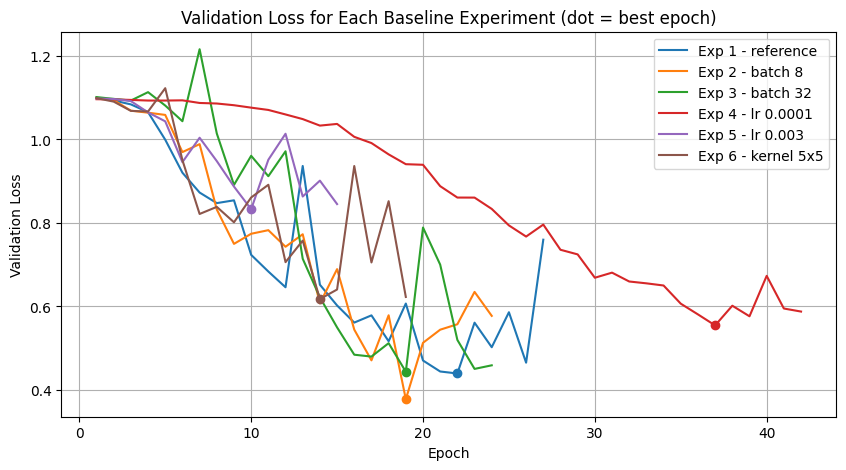

Selected: Experiment 2 (Batch size = 8)
Best epoch 19, validation loss 0.3779, validation accuracy 90.00%


In [ ]:
# Author: Fatema
# Cell 5.6 - Results Table, Validation-Loss Chart and Selection (validation set only)

results_df = pd.DataFrame(experiment_results)
results_df.to_csv(RESULTS_PATH / "baseline_hyperparameter_results.csv", index=False)
display(results_df)

# Validation loss of every experiment; the dot marks the restored best epoch
plt.figure(figsize=(10, 5))
for n, run_history in experiment_histories.items():
    val_losses = run_history.history["val_loss"]
    line, = plt.plot(range(1, len(val_losses) + 1), val_losses, label=experiment_names[n])
    best = int(np.argmin(val_losses))
    plt.scatter(best + 1, val_losses[best], color=line.get_color(), zorder=3)
plt.title("Validation Loss for Each Baseline Experiment (dot = best epoch)")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.savefig(FIGURES_PATH / "figD_1_baseline_experiment_val_loss.png", dpi=150, bbox_inches="tight")
plt.show()

# Selection rule: lowest validation loss at the best epoch
best_row = results_df.loc[results_df["Val. loss"].idxmin()]
SELECTED_EXP = int(best_row["Exp."])
print(f"Selected: Experiment {SELECTED_EXP} ({best_row['Parameter varied']} = {best_row['Value']})")
print(f"Best epoch {best_row['Best epoch']}, validation loss {best_row['Val. loss']}, "
      f"validation accuracy {best_row['Val. acc.']:.2%}")

### 5.6 Selected configuration

- **Learning rate mattered most.** 0.0001 learned slowly (best epoch 37, the
  latest of all runs) and stayed behind 0.001 (0.5547 vs 0.4395). 0.003 was
  unstable: training accuracy only 56.25% and the highest validation loss (0.8328).
- **Kernel size:** 5 × 5 was clearly worse (0.6177); 2.6 times as many parameters
  (267,075) are too many to learn from 240 images.
- **Batch size mattered less.** Batch 32 was close to the reference (0.4438 vs
  0.4395). Batch 8 gave the lowest validation loss (**0.3779**, epoch 19) and the
  highest validation accuracy (90.00%), because it makes 30 smaller, noisier updates
  per epoch instead of 15, which helps on a small dataset. With 30 validation
  images, one image = 3.3 points, so the size of this gain is uncertain.
- Every run stopped early, before the 50-epoch limit, so each setting had a fair
  training length.

**Selected: Experiment 2 – batch 8, learning rate 0.001, 3 × 3 kernels.**

**Decision based on the validation set only.** The test set had no influence on
any choice above.

### 5.7 Final baseline

The selected experiment's model, with the weights of its best epoch restored, is
the **final baseline**. It is not retrained, so it is exactly the model shown in
the table. The next cell plots its learning curves, confirms its validation
loss, and saves it.

Final baseline loaded from: /content/IT8414_Tomato_Project/results/baseline_cnn_final.keras


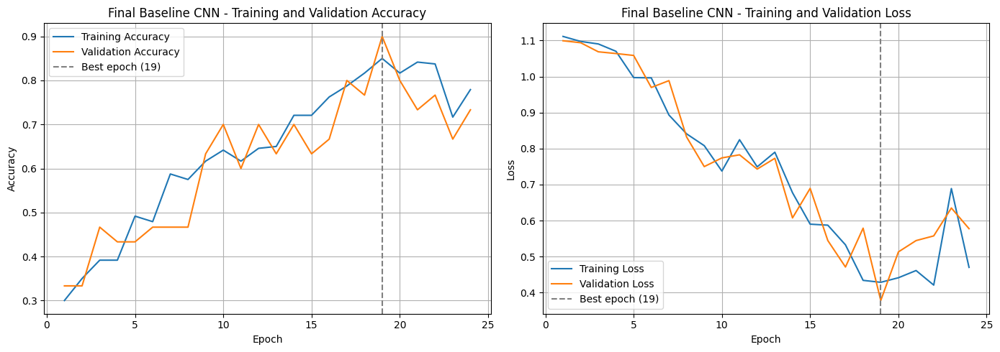

Validation loss 0.3779 | validation accuracy 90.00%


In [ ]:
# Author: Fatema
# Cell 5.7 - Final Baseline: Learning Curves and Save

final_model_file = RESULTS_PATH / "baseline_cnn_final.keras"
final_model_info = RESULTS_PATH / "baseline_cnn_final.json"    # which experiment the saved file holds
SAVED_BASELINE_EXP = json.loads(final_model_info.read_text())["experiment"] if final_model_info.exists() else 2
BASELINE_LOADED = experiment_models[SELECTED_EXP] is None     # True when 5.5 loaded the saved runs
if BASELINE_LOADED and SELECTED_EXP != SAVED_BASELINE_EXP:
    # A live change made another (re-used) experiment the best one, but the saved file holds
    # Exp. SAVED_BASELINE_EXP. Train the selected experiment again so the right model is used.
    print(f"Exp. {SELECTED_EXP} is now selected, but {final_model_file.name} holds Exp. {SAVED_BASELINE_EXP} "
          f"- training Exp. {SELECTED_EXP} again.")
    sel_cfg = load_saved_runs()[str(SELECTED_EXP)]["config"]
    reuse_before, M1_REUSE_SAVED = M1_REUSE_SAVED, False
    _, experiment_histories[SELECTED_EXP], experiment_models[SELECTED_EXP] = run_experiment(
        SELECTED_EXP, best_row["Parameter varied"], best_row["Value"], batch_size=sel_cfg["batch_size"],
        learning_rate=sel_cfg["learning_rate"], kernel_size=tuple(sel_cfg["kernel_size"]), verbose=0)
    M1_REUSE_SAVED = reuse_before
    BASELINE_LOADED = False
if BASELINE_LOADED:
    # Same model as in the report: the one saved by the original training run
    baseline_model = tf.keras.models.load_model(str(final_model_file))
    print("Final baseline loaded from:", final_model_file)
else:
    baseline_model = experiment_models[SELECTED_EXP]
final_history = experiment_histories[SELECTED_EXP].history
final_best_epoch = int(best_row["Best epoch"])
epochs_axis = range(1, len(final_history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
    ax.plot(epochs_axis, final_history[metric], label=f"Training {title}")
    ax.plot(epochs_axis, final_history[f"val_{metric}"], label=f"Validation {title}")
    ax.axvline(final_best_epoch, color="grey", linestyle="--", label=f"Best epoch ({final_best_epoch})")
    ax.set_title(f"Final Baseline CNN - Training and Validation {title}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "fig5_1_final_baseline_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Check: the restored model gives the best-epoch validation loss
val_loss_check, val_acc_check = baseline_model.evaluate(make_dataset(val_df), verbose=0)
print(f"Validation loss {val_loss_check:.4f} | validation accuracy {val_acc_check:.2%}")

if not BASELINE_LOADED:
    baseline_model.save(str(final_model_file))
    final_model_info.write_text(json.dumps({"experiment": int(SELECTED_EXP)}))
    print("Final baseline saved to:", final_model_file)

### 5.7 Interpretation of the baseline learning curves (Figure 5.1)

- **Start:** the validation loss after epoch 1 is 1.0995, almost exactly ln 3 = 1.0986, the loss of guessing
  between three classes. The model starts from nothing, as expected for a network trained from scratch.
- **Learning phase (epochs 1 – 19):** training and validation loss fall together (training 1.111 → 0.428,
  validation 1.099 → 0.378). The best validation loss, **0.3779 at epoch 19**, is where early stopping restored the weights.
- **Validation above training accuracy:** in several epochs validation accuracy is higher than training accuracy
  (epoch 19: 90.0% vs 85.0%). This is expected: training images are randomly flipped, rotated and zoomed, which makes
  them harder, while validation images are not augmented; and with 30 validation images one image moves the score by 3.3 points.
- **After epoch 19:** validation loss rises again (0.51 – 0.64) and training loss jumps at epoch 23 (0.69), a sign of
  the noisy updates of batch size 8. Training stopped at epoch 24, after 5 epochs without improvement.
- **Diagnosis:** there is **no overfitting** at the restored epoch (training loss 0.428 vs validation loss 0.378), but
  there is **some underfitting**: training accuracy reaches only 85%, and the jagged curves show that the small CNN finds
  it hard to learn stable features from 240 images. This is the motivation for transfer learning in Section 6.

## 5.8 Baseline Evaluation on the Test Set

The final baseline is evaluated **once** on the held-out test set (the test part
of the final split from 5.4, equal numbers per class). Accuracy alone is not enough: per-class precision, recall and
F1 show *which* class fails, the confusion matrix shows *where* the mistakes go,
and ROC-AUC shows how well the predicted probabilities rank the true class.

Test loss: 0.5422
Test accuracy: 0.8
Macro F1: 0.7938
Macro ROC-AUC (one-vs-rest): 0.895

              precision    recall  f1-score   support

     Healthy     0.7692    1.0000    0.8696        10
Early Blight     0.7273    0.8000    0.7619        10
 Late Blight     1.0000    0.6000    0.7500        10

    accuracy                         0.8000        30
   macro avg     0.8322    0.8000    0.7938        30
weighted avg     0.8322    0.8000    0.7938        30



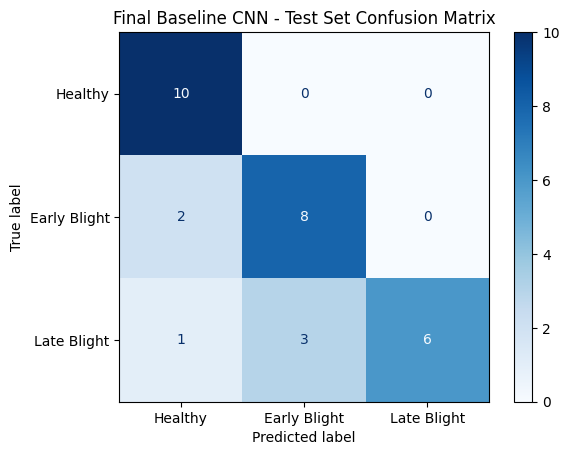

In [ ]:
# Author: Fatema
# Cell 5.8 - Baseline Test-Set Evaluation

from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score

test_ds = make_dataset(test_df)

test_loss, test_accuracy = baseline_model.evaluate(test_ds, verbose=0)
test_probabilities = baseline_model.predict(test_ds, verbose=0)
y_pred = np.argmax(test_probabilities, axis=1)
y_true = test_df["label_id"].values

macro_f1 = f1_score(y_true, y_pred, average="macro")
macro_auc = roc_auc_score(y_true, test_probabilities, multi_class="ovr")

print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4))
print("Macro F1:", round(macro_f1, 4))
print("Macro ROC-AUC (one-vs-rest):", round(macro_auc, 4))
print()
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues")
plt.title("Final Baseline CNN - Test Set Confusion Matrix")
plt.savefig(FIGURES_PATH / "fig5_4_baseline_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Author: Fatema
# Cell 5.8 - Error Summary: Where Do the Mistakes Go?

for i, true_name in enumerate(CLASS_NAMES):
    n_class = cm[i].sum()
    print(f"{true_name}: {cm[i, i]}/{n_class} correct (recall {cm[i, i] / n_class:.1%})")
    for j, predicted_name in enumerate(CLASS_NAMES):
        if j != i and cm[i, j] > 0:
            print(f"    {cm[i, j]} predicted as {predicted_name}")

print(f"\nOne test image = {100 / len(y_true):.1f} percentage points of accuracy.")

Healthy: 10/10 correct (recall 100.0%)
Early Blight: 8/10 correct (recall 80.0%)
    2 predicted as Healthy
Late Blight: 6/10 correct (recall 60.0%)
    1 predicted as Healthy
    3 predicted as Early Blight

One test image = 3.3 percentage points of accuracy.


In [ ]:
# Author: Fatema
# Cell 5.8 - Bootstrap 95% Confidence Intervals (test-set size)

# Resample the test predictions with replacement 1,000 times
rng = np.random.default_rng(SEED)
boot_accuracy, boot_f1 = [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_true), len(y_true))
    boot_accuracy.append(accuracy_score(y_true[idx], y_pred[idx]))
    boot_f1.append(f1_score(y_true[idx], y_pred[idx], average="macro", zero_division=0))

acc_ci = np.percentile(boot_accuracy, [2.5, 97.5])
f1_ci = np.percentile(boot_f1, [2.5, 97.5])
print(f"Test accuracy {test_accuracy:.2%}  (95% CI {acc_ci[0]:.2%} - {acc_ci[1]:.2%})")
print(f"Macro F1      {macro_f1:.2%}  (95% CI {f1_ci[0]:.2%} - {f1_ci[1]:.2%})")

# Save every final number for the team, the README and the report
per_class_recall = recall_score(y_true, y_pred, average=None)
baseline_results = {
    "selected_experiment": SELECTED_EXP,
    "configuration": {k: str(best_row[k]) for k in ["Parameter varied", "Value", "Best epoch", "Epochs run"]},
    "validation_accuracy": float(best_row["Val. acc."]),
    "validation_loss": float(best_row["Val. loss"]),
    "test_loss": round(float(test_loss), 4),
    "test_accuracy": round(float(test_accuracy), 4),
    "test_accuracy_95ci": [round(float(x), 4) for x in acc_ci],
    "macro_f1": round(float(macro_f1), 4),
    "macro_f1_95ci": [round(float(x), 4) for x in f1_ci],
    "macro_roc_auc": round(float(macro_auc), 4),
    "recall_per_class": {name: round(float(r), 4) for name, r in zip(CLASS_NAMES, per_class_recall)},
    "confusion_matrix": cm.tolist(),
    "parameters": int(baseline_model.count_params()),
}
with open(RESULTS_PATH / "baseline_test_results.json", "w") as f:
    json.dump(baseline_results, f, indent=2)
print("\nSaved results/baseline_test_results.json")

Test accuracy 80.00%  (95% CI 66.67% - 93.33%)
Macro F1      79.38%  (95% CI 62.49% - 91.68%)

Saved results/baseline_test_results.json


### 5.8 Interpretation of the test results

- **Overall:** test accuracy **80.00%** (95% CI 66.67–93.33%), macro F1 **79.38%**,
  ROC-AUC **0.8950**. Validation accuracy was 90.00%; the gap is 3 images. The
  validation set was used for early stopping, the split ratio and the choice among
  six settings, so its score is optimistic; the test set (used once) is the honest
  estimate.
- **Per class:** Healthy 10/10, Early Blight 8/10, **Late Blight 6/10** (weakest).
- **Where the errors go:** 3 Late Blight leaves were predicted as Early Blight, the
  confusion expected from the EDA (both have brown lesions, Figure 3.3). 3 diseased
  leaves were predicted as Healthy (2 Early Blight, 1 Late Blight).
- **Costliest error:** a diseased leaf called Healthy, because the farmer would not
  treat the plant. One Late Blight leaf was called Healthy (87% confidence). Its
  lesion is large, so lesion size does not explain this error; the error analysis
  in 9.2 and Grad-CAM in 9.4 show that the baseline looked mainly at the blue
  background of this photo rather than at the lesion (a background shortcut).
- **Good news:** no healthy leaf was flagged as diseased, and every Late Blight
  prediction was correct (precision 100%).

**Test-set size:** with 30 test images, one image = 3.3 percentage points, so
small differences between models may be noise. The bootstrap 95% confidence
intervals above show how wide this uncertainty is.

### 5.8 Predict a single new image (live demonstration)

Classifies any leaf image (for example one chosen by the tutor) with the final
baseline. The image goes through the **same** `load_and_preprocess` function as
the training data. The example below uses a test image that the model
classifies correctly.

True class: Late Blight


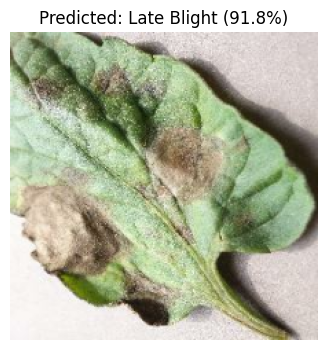

Healthy       5.99%
Early Blight  2.26%
Late Blight   91.76%


'Late Blight'

In [ ]:
# Author: Fatema
# Cell 5.8 - Predict a Single Image (live demo)

def predict_leaf(image_path, model=baseline_model):
    # Same preprocessing as training: decode RGB, resize 224x224, scale to 0-1
    image, _ = load_and_preprocess(tf.constant(str(image_path)), 0)
    probabilities = model.predict(tf.expand_dims(image, 0), verbose=0)[0]
    predicted = int(np.argmax(probabilities))

    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.title(f"Predicted: {CLASS_NAMES[predicted]} ({probabilities[predicted]:.1%})")
    plt.axis("off")
    plt.show()

    for name, p in zip(CLASS_NAMES, probabilities):
        print(f"{name:13s} {p:.2%}")
    return CLASS_NAMES[predicted]


# Example: a correctly classified test image (a Late Blight one if possible)
correct_idx = np.where(y_pred == y_true)[0]
late_blight_correct = [i for i in correct_idx if y_true[i] == 2]
demo_i = (late_blight_correct or list(correct_idx))[0]

print("True class:", CLASS_NAMES[y_true[demo_i]])
predict_leaf(test_df["image_path"].iloc[demo_i])

## 5.9 Baseline Summary

**Data:** 300 PlantVillage images (100 Healthy, 100 Early Blight, 100 Late Blight),
stratified **80/10/10** split (240 / 30 / 30) chosen by the split-ratio experiment (5.3), saved in
`data/split_manifests/`, no exact or near-duplicate leakage between splits. The ratio choice
was re-checked without the final test images (5.3).
The class choice is supported by the colour evidence in 3.0 (Figure 3.3).

**Baseline:** 3-block custom CNN (101,699 parameters). Selected configuration:
batch 8, learning rate 0.001, 3 × 3 kernels, early stopping (best epoch 19).
Validation accuracy 90.00%, test accuracy 80.00%, macro F1 79.38%, ROC-AUC 0.8950,
Late Blight recall 60.00%. All values are saved in `results/baseline_test_results.json`.

**Objects re-used by Sections 6.0 – 10.0** (all defined after running 1.0–5.8):

| Name | What it is |
|---|---|
| `train_df`, `val_df`, `test_df` | The fixed final split (do **not** re-split; ratio in `CHOSEN_RATIO_NAME`) |
| `make_dataset(df, training, batch_size)` | Same preprocessing for every model (output range 0–1) |
| `make_augmentation()` | Same training-only augmentation |
| `CLASS_NAMES`, `LABEL_MAP` | Class order 0 = Healthy, 1 = Early Blight, 2 = Late Blight |
| `baseline_model` | Final baseline (also saved in `results/baseline_cnn_final.keras`) |
| `results_df` | Baseline tuning table |
| `RESULTS_PATH`, `FIGURES_PATH` | Where to save models and figures |

In [ ]:
# Author: Fatema
# Cell 5.9 - Final Numbers and Ready-to-Paste Text (for the report, notebook and README)

from sklearn.metrics import precision_score

pct = lambda x: f"{x * 100:.2f}%"
ref = results_df[results_df["Exp."] == 1].iloc[0]
sel = best_row
sel_time = float(sel["Train time (min)"])
macro_precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
macro_recall = recall_score(y_true, y_pred, average="macro")
per_class_precision = precision_score(y_true, y_pred, average=None, zero_division=0)
per_class_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
lines = []
out = lines.append

def by(param, value):
    row = results_df[(results_df["Parameter varied"] == param) & (results_df["Value"] == value)]
    return row.iloc[0] if len(row) else None

# ---------- Q. Class-choice evidence (report 1.1 / 3.2) ----------
out("=== Q. TEXT for report 3.2 (Figure 3.3, class-choice evidence) ===")
lf = {name: lesion_fractions[name].mean() for name in CLASS_NAMES}
out(f"On {N_EVIDENCE} random images per class, the brown/yellow (lesion-coloured) share of the leaf was "
    f"{lf['Healthy']:.1%} for Healthy, {lf['Early Blight']:.1%} for Early Blight and {lf['Late Blight']:.1%} for Late Blight. "
    f"Colour-profile distances: " + "; ".join(f"{k} {v}" for k, v in pair_distances.items()) +
    f" (most similar pair: {closest_pair}). A colour-only classifier reached {colour_accuracy:.1%} "
    f"(correct per class: " + ", ".join(f"{n} {colour_cm[i, i]}/{colour_cm[i].sum()}" for i, n in enumerate(CLASS_NAMES)) +
    f"; Early Blight predicted as Late Blight {colour_cm[1, 2]}x, Late Blight predicted as Healthy {colour_cm[2, 0]}x).")

# ---------- S. Split-ratio experiment (report 3.4) ----------
out("")
out("=== S. TEXT for notebook 5.3 'Interpretation' and report 3.4 (Figure 3.6) ===")
if split_summary is not None:
    parts = [f"{r}: {row['mean_val_loss']:.4f} ± {row['sd_val_loss']:.4f} "
             f"(accuracy {pct(row['mean_val_acc'])} ± {pct(row['sd_val_acc'])}; "
             f"{int(row['train_images'])} training / {int(row['val_images'])} validation images)"
             for r, row in split_summary.iterrows()]
    best_r = split_summary["mean_val_loss"].idxmin()
    reason = ("it had the lowest mean validation loss"
              if CHOSEN_RATIO_NAME == best_r else
              f"it was within one standard error of the lowest ({best_r}), so by the rule fixed in advance "
              f"the ratio with the larger validation and test sets was preferred")
    out(f"Mean validation loss ± SD over three random splits per ratio - " + "; ".join(parts) +
        f". The chosen ratio is {CHOSEN_RATIO_NAME}, because {reason}. "
        f"The final split has {len(train_df)} / {len(val_df)} / {len(test_df)} images. "
        f"The decision used validation data only. The candidate splits were drawn independently of the "
        f"final split, so their validation parts contained up to {overlap_df['Of these in the final test set'].max()} "
        f"of the {len(test_df)} final test images; no model was trained, tuned or selected on the final test set.")
    check_parts = [f"{r}: {row['mean_val_loss']:.4f} ± {row['sd_val_loss']:.4f}" for r, row in check_summary.iterrows()]
    out(f"Check without the final test images ({len(pool_df)} images) - mean validation loss ± SD: "
        + "; ".join(check_parts) + f". Ratio chosen by the same rule: {check_chosen} "
        + ("(the same ratio, so the overlap did not influence the choice)." if SPLIT_CHECK_AGREES
           else f"(different from {CHOSEN_RATIO_NAME}; report this)."))
else:
    out("Split-ratio comparison not available in this session (saved split loaded).")
out("")

# ---------- A. Report Table 4.2 ----------
cfg = {"batch": "16", "lr": "0.001", "kernel": "3x3"}
if sel["Parameter varied"] == "Batch size": cfg["batch"] = sel["Value"]
if sel["Parameter varied"] == "Learning rate": cfg["lr"] = sel["Value"]
if sel["Parameter varied"] == "Kernel size": cfg["kernel"] = sel["Value"]
out("=== A. REPORT TABLE 4.2 (training configuration) ===")
out(f"Learning rate selected: {cfg['lr']} | Batch size selected: {cfg['batch']} | Kernel: {cfg['kernel']}")
out(f"Best epoch: {sel['Best epoch']} (training stopped at epoch {sel['Epochs run']})")
saved_runs = load_saved_runs()
run_hardware = saved_runs.get(str(SELECTED_EXP), {}).get("hardware", HARDWARE)
out(f"Hardware: {run_hardware} | Final training time: {sel_time} min")

# ---------- B. Report Table 5.1 ----------
out("")
out("=== B. REPORT TABLE 5.1 (Exp | Best epoch (of run) | Train acc | Val acc | Val loss | Observation) ===")
for _, r in results_df.iterrows():
    if int(r["Exp."]) == SELECTED_EXP:
        note = "Lowest validation loss - selected"
    elif int(r["Exp."]) == 1:
        note = "Reference"
    else:
        direction = "Lower" if r["Val. loss"] < ref["Val. loss"] else "Higher"
        note = f"{direction} validation loss than the reference ({r['Val. loss']} vs {ref['Val. loss']})"
    if int(r["Epochs run"]) == MAX_EPOCHS:
        note += "; reached the 50-epoch limit"
    out(f"{int(r['Exp.'])} | {r['Best epoch']} ({r['Epochs run']}) | {pct(r['Train acc.'])} | "
        f"{pct(r['Val. acc.'])} | {r['Val. loss']} | {note}")

# ---------- C. Report Table 5.2 ----------
out("")
out("=== C. REPORT TABLE 5.4 (baseline row; Accuracy | Precision | Recall | F1 | AUC | Params | Train time) ===")
out(f"{pct(test_accuracy)} ({pct(acc_ci[0])}-{pct(acc_ci[1])}) | {pct(macro_precision)} | {pct(macro_recall)} | "
    f"{pct(macro_f1)} ({pct(f1_ci[0])}-{pct(f1_ci[1])}) | {macro_auc:.4f} | "
    f"{baseline_model.count_params():,} | {sel_time} min")

# ---------- D. Report Table 5.3 ----------
out("")
out("=== D. REPORT TABLE 5.5 (Class | Precision | Recall | F1 | Correct / test images of the class) ===")
for i, name in enumerate(CLASS_NAMES):
    out(f"{name} | {pct(per_class_precision[i])} | {pct(per_class_recall[i])} | {pct(per_class_f1[i])} | {cm[i, i]}/{cm[i].sum()}")

# ---------- E. Text for notebook 5.6 and report 5.2 ----------
def describe(param, values):
    parts = []
    for v in values:
        row = ref if (param, v) in [("Batch size", "16"), ("Learning rate", "0.001")] else by(param, v)
        if row is not None:
            parts.append(f"{v}: {row['Val. loss']} (epoch {row['Best epoch']})")
    return "; ".join(parts)

k5 = by("Kernel size", "5x5")
out("")
out("=== E. TEXT for notebook 5.6 'Selected configuration' and report 5.2 ===")
out(f"Validation loss at the best epoch - batch size {describe('Batch size', ['8', '16', '32'])}. "
    f"Learning rate {describe('Learning rate', ['0.0001', '0.001', '0.003'])}. "
    f"Kernel 3x3: {ref['Val. loss']} vs 5x5: {k5['Val. loss']} "
    f"({int(k5['Params']):,} instead of {int(ref['Params']):,} parameters). "
    f"The selected configuration is Experiment {SELECTED_EXP} ({sel['Parameter varied']} = {sel['Value']}), "
    f"with the lowest validation loss ({sel['Val. loss']}) at epoch {sel['Best epoch']} and validation accuracy "
    f"{pct(sel['Val. acc.'])}. Early stopping gave every setting a fair training length. "
    f"The decision used the validation set only; the test set had no influence.")

# ---------- F. Text for report 5.1 (learning curves) ----------
h = final_history
b = int(sel["Best epoch"]) - 1
gap = h["accuracy"][b] - h["val_accuracy"][b]
fit = ("no clear overfitting" if abs(gap) < 0.08 else
       "some overfitting (training accuracy clearly higher)" if gap > 0 else
       "validation accuracy above training accuracy, as expected with training-only augmentation")
out("")
out("=== F. TEXT for report 5.1 (Figure 5.1) ===")
start_note = (" - close to ln 3 = 1.0986, the loss of random guessing between three classes"
              if abs(h["val_loss"][0] - 1.0986) < 0.05 else "")
out(f"Training started with validation loss {h['val_loss'][0]:.4f}{start_note}. The best validation loss ({h['val_loss'][b]:.4f}) was reached at epoch {b + 1}; training stopped "
    f"at epoch {len(h['loss'])} after {PATIENCE} epochs without improvement, and the best weights were restored. At the "
    f"best epoch, training accuracy was {pct(h['accuracy'][b])} and validation accuracy {pct(h['val_accuracy'][b])} "
    f"(training loss {h['loss'][b]:.4f}, validation loss {h['val_loss'][b]:.4f}), so there is {fit}.")

# ---------- G. Text for notebook 5.8 interpretation and report 5.3 ----------
recalls = per_class_recall
worst = int(np.argmin(recalls))
wrong = [(cm[worst, j], CLASS_NAMES[j]) for j in range(3) if j != worst and cm[worst, j] > 0]
wrong_text = " and ".join(f"{n} as {name}" for n, name in sorted(wrong, reverse=True)) or "none"
good = [f"{CLASS_NAMES[i]} ({cm[i, i]}/{cm[i].sum()})" for i in range(3) if i != worst]
out("")
out("=== G. TEXT for notebook 5.8 'Interpretation' and report 5.3 ===")
text = (f"The final baseline reached a test accuracy of {pct(test_accuracy)} (95% CI {pct(acc_ci[0])}-{pct(acc_ci[1])}), "
        f"compared with {pct(sel['Val. acc.'])} on validation; macro F1 was {pct(macro_f1)} and macro ROC-AUC {macro_auc:.4f}. "
        f"{' and '.join(good)} are recognised best. The weakest class is {CLASS_NAMES[worst]} "
        f"(recall {pct(recalls[worst])}, {cm[worst, worst]}/{cm[worst].sum()}): {wrong_text}.")
late_to_healthy = cm[2, 0]
if late_to_healthy > 0:
    leaves = "leaf" if late_to_healthy == 1 else "leaves"
    text += (f" Predicting Healthy for a Late Blight leaf ({late_to_healthy} {leaves}) is the costliest error for a "
             f"screening tool, because the farmer would not treat the plant.")
if worst == 2:
    text += (" Most Late Blight errors are confusions with Early Blight: both blights produce similar brown, "
             "necrotic lesions (Figure 3.3). The Late Blight leaf predicted as Healthy has a large lesion; "
             "Grad-CAM (Section 9.4) shows the baseline looked mainly at the photo's blue background instead.")
elif worst == 1:
    text += (" A likely cause is that both blights produce similar brown, necrotic lesions.")
text += (f" With {len(y_true)} test images, one image = {100 / len(y_true):.1f} percentage points, "
         f"so small differences between models may be noise.")
out(text)

# ---------- H. Notebook 5.9 summary ----------
out("")
out("=== H. TEXT for notebook 5.9 summary ===")
out(f"Selected configuration: batch {cfg['batch']}, learning rate {cfg['lr']}, {cfg['kernel']} kernels, early stopping "
    f"(best epoch {sel['Best epoch']}). Validation accuracy {pct(sel['Val. acc.'])}, test accuracy {pct(test_accuracy)}, "
    f"macro F1 {pct(macro_f1)}, ROC-AUC {macro_auc:.4f}, Late Blight recall {pct(recalls[2])}.")

report_text = "\n".join(lines)
print(report_text)
(RESULTS_PATH / "NUMBERS_FOR_REPORT.txt").write_text(report_text)

print("Saved results/NUMBERS_FOR_REPORT.txt")

=== Q. TEXT for report 3.2 (Figure 3.3, class-choice evidence) ===
On 150 random images per class, the brown/yellow (lesion-coloured) share of the leaf was 0.8% for Healthy, 14.7% for Early Blight and 18.7% for Late Blight. Colour-profile distances: Healthy - Early Blight 0.447; Healthy - Late Blight 0.294; Early Blight - Late Blight 0.261 (most similar pair: Early Blight - Late Blight). A colour-only classifier reached 64.7% (correct per class: Healthy 140/150, Early Blight 79/150, Late Blight 72/150; Early Blight predicted as Late Blight 50x, Late Blight predicted as Healthy 62x).

=== S. TEXT for notebook 5.3 'Interpretation' and report 3.4 (Figure 3.6) ===
Mean validation loss ± SD over three random splits per ratio - 70/15/15: 0.4581 ± 0.0044 (accuracy 79.26% ± 1.28%; 210 training / 45 validation images); 80/10/10: 0.4097 ± 0.0353 (accuracy 80.00% ± 0.00%; 240 training / 30 validation images); 60/20/20: 0.4588 ± 0.0281 (accuracy 81.11% ± 3.47%; 180 training / 60 validation images)

In [ ]:
# Author: Fatema
# Cell 5.9 - Download the Updated Project Files (optional)

# The project's results are kept in the GitHub repository, so "Run all" does not download
# anything. Set this to True to get a ZIP of the project (without the original images),
# for example after re-training the baseline in Colab, where storage is temporary.
DOWNLOAD_MEMBER1_RESULTS = False

if DOWNLOAD_MEMBER1_RESULTS:
    EXPORT_ROOT = UPLOAD_DIR / "export"
    if EXPORT_ROOT.exists():
        shutil.rmtree(EXPORT_ROOT)

    # Copy the project without the large original images
    def skip_large(folder, names):
        skip = [n for n in names if n.endswith(".zip")]
        if Path(folder) == PROJECT_DIR / "data":
            skip.append("original")
        return skip

    shutil.copytree(PROJECT_DIR, EXPORT_ROOT / "IT8414_Tomato_Project", ignore=skip_large)
    archive = shutil.make_archive(str(UPLOAD_DIR / "IT8414_Member1_results"), "zip", EXPORT_ROOT)
    shutil.rmtree(EXPORT_ROOT)
    print("ZIP size:", round(Path(archive).stat().st_size / 1e6, 1), "MB")
    if IN_COLAB:
        files.download(archive)
    else:
        print("Offline mode - the ZIP is saved at:", archive)
else:
    print("No download needed: the results are in results/ and in the GitHub repository.")


No download needed: the results are in results/ and in the GitHub repository.


## 6.0 Improved Model — Transfer Learning with MobileNetV2

The baseline CNN (Section 5) learns every filter from 240 training images. The
improved model instead **re-uses visual features learned on 1.28 million ImageNet
photographs** (transfer learning) and only has to learn how to map them to our three
classes. This is the pairing the brief lists as acceptable: *custom CNN vs transfer
learning*.

**Rules that keep the comparison fair** (the same as for the baseline):

| Rule | How this section follows it |
|---|---|
| Same images | `train_df`, `val_df`, `test_df` come from the saved manifests (5.4); nothing is re-split |
| Same preprocessing | `make_dataset()` (decode → 224 × 224 → ÷255 → batch) is reused unchanged |
| Same augmentation | `make_augmentation()` (flip, rotation 0.1, zoom 0.1) is the first layer of the model |
| Same seed | `tf.keras.utils.set_random_seed(SEED)` before every model is built |
| Validation only | Every tuning and selection decision uses `val_df`; **the test set is not touched in 6.0 – 7.0**. The final model is evaluated on it once, in 8.0 |

The first cell below works in two situations: when the notebook is run from the top it
simply re-uses the objects from Sections 1.0 – 5.4; when this section is run on its own
(for example on the offline demo machine) it rebuilds exactly the same objects from
`data/split_manifests/`.

In [ ]:
# Author: Eman Khamdan (Member 2)
# Cell 6.0 - Member 2 Setup: Reuse Member 1's Split and Pipeline

import os
import json
import time
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

# In the master notebook, Member 1's cells 1.0 - 5.2 have already defined these objects.
REQUIRED = ["train_df", "val_df", "test_df", "make_dataset", "make_augmentation",
            "CLASS_NAMES", "LABEL_MAP", "SPLIT_PATH", "RESULTS_PATH", "FIGURES_PATH", "SEED"]
STANDALONE = not all(name in globals() for name in REQUIRED)

if STANDALONE:
    # ---- Member 2's own copy / offline demo machine: rebuild the same objects ----
    SEED = 42
    tf.keras.utils.set_random_seed(SEED)

    # Colab path by default; set the environment variable IT8414_PROJECT_DIR to run elsewhere
    PROJECT_DIR = Path(os.environ.get("IT8414_PROJECT_DIR", "/content/IT8414_Tomato_Project"))

    # Nothing to upload: if the split manifests are missing, download the project from GitHub
    if not (PROJECT_DIR / "data" / "split_manifests" / "train_split.csv").exists() and not PROJECT_DIR.exists():
        import subprocess
        subprocess.run(["git", "clone", "--depth", "1", "--branch", os.environ.get("IT8414_REPO_BRANCH", "main"),
                        "https://github.com/Eman-271/IT8414-Tomato-Leaf-Disease-Classification.git",
                        str(PROJECT_DIR)], check=False)

    # If Member 1's share ZIP was uploaded to /content, unzip it once
    if Path("/content").exists() and not PROJECT_DIR.exists():
        share_zips = sorted(Path("/content").glob("*Member1_Share*.zip"))
        if share_zips:
            with zipfile.ZipFile(share_zips[0]) as z:
                z.extractall("/content")
            print("Share package unzipped from:", share_zips[0].name)

    SELECTED_PATH = PROJECT_DIR / "data" / "selected"
    SPLIT_PATH = PROJECT_DIR / "data" / "split_manifests"
    RESULTS_PATH = PROJECT_DIR / "results"
    FIGURES_PATH = RESULTS_PATH / "figures"
    FIGURES_PATH.mkdir(parents=True, exist_ok=True)

    CLASS_NAMES = ["Healthy", "Early Blight", "Late Blight"]                       # label IDs 0, 1, 2
    EXPECTED_CLASSES = ["Tomato___healthy", "Tomato___Early_blight", "Tomato___Late_blight"]
    LABEL_MAP = {folder: i for i, folder in enumerate(EXPECTED_CLASSES)}
    IMG_SIZE = (224, 224)
    BATCH_SIZE = 16
    AUTOTUNE = tf.data.AUTOTUNE

    # ---- The four functions below are copied UNCHANGED from Member 1 (Cell 4.0) ----
    def load_manifest(csv_path):
        # Rebuild the full image path from the class label and file name
        frame = pd.read_csv(csv_path)
        if "filename" not in frame.columns:
            frame["filename"] = frame["image_path"].apply(lambda p: Path(p).name)
        frame["image_path"] = [str(SELECTED_PATH / label / name)
                               for label, name in zip(frame["label"], frame["filename"])]
        frame["label_id"] = frame["label"].map(LABEL_MAP)
        return frame[["image_path", "label", "label_id"]].reset_index(drop=True)

    def load_and_preprocess(image_path, label):
        # Decode RGB -> resize to 224 x 224 -> scale pixels to 0-1
        image = tf.io.read_file(image_path)
        image = tf.io.decode_image(image, channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, IMG_SIZE)
        image = tf.cast(image, tf.float32) / 255.0
        return image, label

    def make_dataset(df, training=False, batch_size=BATCH_SIZE):
        dataset = tf.data.Dataset.from_tensor_slices((df["image_path"].values, df["label_id"].values))
        dataset = dataset.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
        dataset = dataset.cache()
        if training:   # shuffle the training data only
            dataset = dataset.shuffle(buffer_size=len(df), seed=SEED, reshuffle_each_iteration=True)
        return dataset.batch(batch_size).prefetch(AUTOTUNE)

    def make_augmentation():
        return tf.keras.Sequential([
            tf.keras.layers.RandomFlip("horizontal"),
            tf.keras.layers.RandomRotation(0.1),
            tf.keras.layers.RandomZoom(0.1)
        ], name="data_augmentation")
    # ---- end of the code copied from Member 1 ----

    train_df = load_manifest(SPLIT_PATH / "train_split.csv")
    val_df = load_manifest(SPLIT_PATH / "validation_split.csv")
    test_df = load_manifest(SPLIT_PATH / "test_split.csv")
    print("Standalone mode: split loaded from", SPLIT_PATH)
else:
    print("Master-notebook mode: re-using Member 1's split, make_dataset() and make_augmentation().")

print(f"{len(train_df)} training / {len(val_df)} validation / {len(test_df)} test images")

# Stop early, with instructions, if this is not the official split of the report (240 / 30 / 30)
if (len(train_df), len(val_df), len(test_df)) != (240, 30, 30) or globals().get("SPLIT_LOADED") is False:
    raise RuntimeError(
        f"This is not the official 80/10/10 split (found {len(train_df)} / {len(val_df)} / {len(test_df)} images"
        + (", made new in this session" if globals().get("SPLIT_LOADED") is False else "") + ").\n"
        "Fix: Runtime -> Run all again. Cell 1.0 downloads the official split from GitHub, and Cell 4.0 then prints "
        "'Saved split loaded (ratio 80/10/10): 240 training / 30 validation / 30 test images'.")
print("TensorFlow", tf.__version__, "| Keras", tf.keras.__version__ if hasattr(tf.keras, "__version__") else "")
GPU_NAME = "T4 GPU" if tf.config.list_physical_devices("GPU") else "CPU"
print("Hardware of this session:", GPU_NAME, "(the hardware used to TRAIN the saved runs is read in Cell 6.2)")

Master-notebook mode: re-using Member 1's split, make_dataset() and make_augmentation().
240 training / 30 validation / 30 test images
TensorFlow 2.21.0 | Keras 3.15.1
Hardware of this session: CPU (the hardware used to TRAIN the saved runs is read in Cell 6.2)


### 6.0 Data check before training (verification of the pipeline)

Before the improved model is trained, the next cell verifies the preprocessed data
and the batch loaders, and stops with an error if anything is wrong:

1. the split in memory is **identical to the saved manifests** (so nobody re-split by accident);
2. the split sizes and the **stratification** (80 / 10 / 10 images per class);
3. **no image appears in two splits**, and every file exists;
4. one batch has shape *(batch, 224, 224, 3)*, type float32 and pixel range 0 – 1;
5. the validation loader is **not shuffled**, so predictions line up with `val_df` (needed for the evaluation in 8.0);
6. after the MobileNetV2 rescaling layer the pixels are in the range −1 to 1.

In [ ]:
# Author: Eman Khamdan (Member 2)
# Cell 6.0 - Data Check: Manifests, Stratification, Leakage and Batch Shapes

checks = []
frames = {"train": train_df, "validation": val_df, "test": test_df}
manifests = {s: pd.read_csv(SPLIT_PATH / f"{s}_split.csv") for s in frames}

def keys(frame):
    # class folder + file name identifies an image uniquely
    return set(Path(p).parent.name + "/" + Path(p).name for p in frame["image_path"])

for s, frame in frames.items():
    on_disk = set(manifests[s]["label"] + "/" + manifests[s]["filename"])
    checks.append((f"{s}: identical to the saved manifest", keys(frame) == on_disk))
    checks.append((f"{s}: every image file exists", all(Path(p).exists() for p in frame["image_path"])))

expected = {"train": 80, "validation": 10, "test": 10}
for s, frame in frames.items():
    counts = frame["label_id"].value_counts().to_dict()
    checks.append((f"{s}: {expected[s]} images per class {counts}",
                   counts == {0: expected[s], 1: expected[s], 2: expected[s]}))

checks.append(("no image shared by train / validation",
               not keys(train_df) & keys(val_df)))
checks.append(("no image shared by train / test", not keys(train_df) & keys(test_df)))
checks.append(("no image shared by validation / test", not keys(val_df) & keys(test_df)))

images, labels = next(iter(make_dataset(train_df, training=True, batch_size=8)))
checks.append((f"training batch shape {tuple(images.shape)}", tuple(images.shape) == (8, 224, 224, 3)))
checks.append((f"pixel dtype {images.dtype.name}, range {float(tf.reduce_min(images)):.3f} - "
               f"{float(tf.reduce_max(images)):.3f}",
               images.dtype == tf.float32 and float(tf.reduce_min(images)) >= 0
               and float(tf.reduce_max(images)) <= 1))

val_labels = np.concatenate([y.numpy() for _, y in make_dataset(val_df, batch_size=8)])
checks.append(("validation loader keeps the order of val_df", np.array_equal(val_labels, val_df["label_id"].values)))

rescaled = tf.keras.layers.Rescaling(2.0, offset=-1.0)(images)
checks.append((f"MobileNetV2 input range {float(tf.reduce_min(rescaled)):.3f} - {float(tf.reduce_max(rescaled)):.3f}",
               float(tf.reduce_min(rescaled)) >= -1 and float(tf.reduce_max(rescaled)) <= 1))

for description, passed in checks:
    print(("PASS  " if passed else "FAIL  ") + description)
assert all(passed for _, passed in checks), "Data check failed - do not train until this is fixed (see the FAIL lines above)."
print(f"\nAll {len(checks)} checks passed.")

PASS  train: identical to the saved manifest
PASS  train: every image file exists
PASS  validation: identical to the saved manifest
PASS  validation: every image file exists
PASS  test: identical to the saved manifest
PASS  test: every image file exists
PASS  train: 80 images per class {1: 80, 2: 80, 0: 80}
PASS  validation: 10 images per class {0: 10, 1: 10, 2: 10}
PASS  test: 10 images per class {2: 10, 1: 10, 0: 10}
PASS  no image shared by train / validation
PASS  no image shared by train / test
PASS  no image shared by validation / test
PASS  training batch shape (8, 224, 224, 3)
PASS  pixel dtype float32, range 0.000 - 0.970
PASS  validation loader keeps the order of val_df
PASS  MobileNetV2 input range -1.000 - 0.940

All 16 checks passed.


### 6.0 Overall workflow (Figure 4.1)

The diagram shows how both models share one data pipeline, how each is tuned on the
validation set only, and where the single test-set evaluation (Section 8.0)
happens. It is Figure 4.1 in the report.

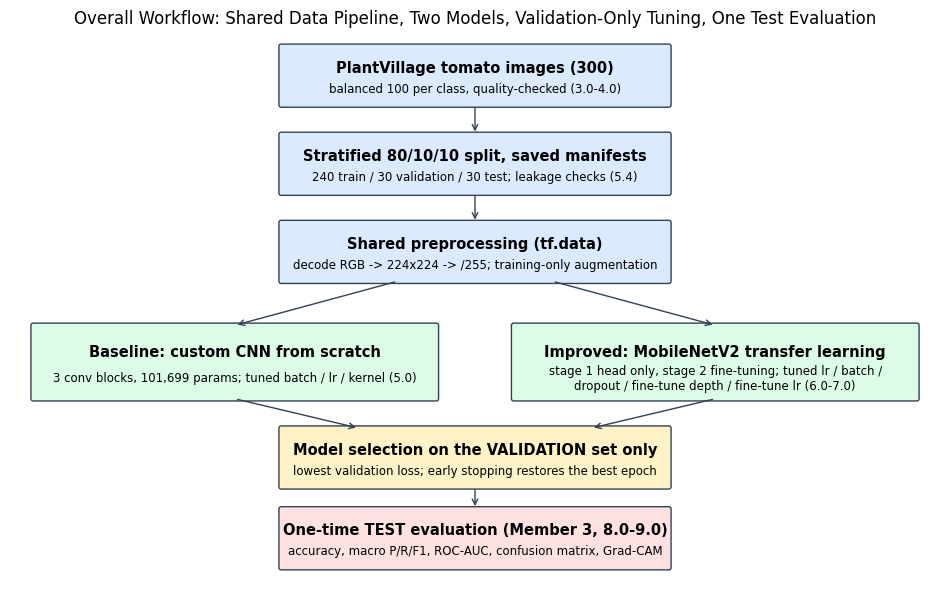

In [ ]:
# Author: Eman Khamdan (Member 2)
# Cell 6.0 - Overall Workflow Diagram (Figure 4.1)

from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 7.2))
ax.set_xlim(0, 12)
ax.set_ylim(-0.35, 7.2)
ax.axis("off")

def box(x, y, w, h, title, detail, colour):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03", fc=colour, ec="#334155"))
    ax.text(x + w / 2, y + h * 0.64, title, ha="center", va="center", fontsize=10.5, weight="bold")
    ax.text(x + w / 2, y + h * 0.28, detail, ha="center", va="center", fontsize=8.5)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="#334155"))

blue, green, amber, red = "#dbeafe", "#dcfce7", "#fef3c7", "#fee2e2"
box(3.5, 6.2, 5, 0.8, "PlantVillage tomato images (300)", "balanced 100 per class, quality-checked (3.0-4.0)", blue)
box(3.5, 5.0, 5, 0.8, "Stratified 80/10/10 split, saved manifests", "240 train / 30 validation / 30 test; leakage checks (5.4)", blue)
box(3.5, 3.8, 5, 0.8, "Shared preprocessing (tf.data)", "decode RGB -> 224x224 -> /255; training-only augmentation", blue)
arrow(6, 6.2, 6, 5.8); arrow(6, 5.0, 6, 4.6)

box(0.3, 2.2, 5.2, 1.0, "Baseline: custom CNN from scratch", "3 conv blocks, 101,699 params; tuned batch / lr / kernel (5.0)", green)
box(6.5, 2.2, 5.2, 1.0, "Improved: MobileNetV2 transfer learning", "stage 1 head only, stage 2 fine-tuning; tuned lr / batch /\ndropout / fine-tune depth / fine-tune lr (6.0-7.0)", green)
arrow(5, 3.8, 2.9, 3.2); arrow(7, 3.8, 9.1, 3.2)

box(3.5, 1.0, 5, 0.8, "Model selection on the VALIDATION set only", "lowest validation loss; early stopping restores the best epoch", amber)
arrow(2.9, 2.2, 4.5, 1.8); arrow(9.1, 2.2, 7.5, 1.8)

box(3.5, -0.1, 5, 0.8, "One-time TEST evaluation (Member 3, 8.0-9.0)", "accuracy, macro P/R/F1, ROC-AUC, confusion matrix, Grad-CAM", red)
arrow(6, 1.0, 6, 0.7)
ax.set_title("Overall Workflow: Shared Data Pipeline, Two Models, Validation-Only Tuning, One Test Evaluation", fontsize=12)
plt.savefig(FIGURES_PATH / "fig4_1_overall_workflow.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.1 Architecture

**Why MobileNetV2?** (full justification in report Section 2.4)

- **Transfer learning suits 240 training images.** Filters learned on ImageNet
  (edges, colours, textures, shapes) are general, so only the classifier on top has to
  be learned from our data (Yosinski et al., 2014).
- **Small and fast.** MobileNetV2 has about 2.26 million parameters, roughly
  one-eleventh of ResNet50 (about 23.6 million without its top layer). It was designed
  for phones (Sandler et al., 2018), which fits a screening tool used by farmers in the field.
- **Same input size.** It expects 224 × 224 images, which the shared pipeline already produces.

**How MobileNetV2 processes an image.** It is built from 17 *inverted residual
bottleneck* blocks. Each block (1) **expands** the channels with a 1 × 1 convolution,
(2) filters each channel separately with a 3 × 3 **depthwise** convolution, and
(3) **projects** back to few channels with a 1 × 1 convolution that has *no* activation
(a *linear bottleneck*, so information is not destroyed by ReLU in a low-dimensional
space). A shortcut adds the block's input to its output when the shapes match.
Activations are ReLU6, and every convolution is followed by batch normalisation.
For a 224 × 224 image, the last layer (`out_relu`) gives **7 × 7 × 1,280** feature maps.

**Our model (layer by layer):**

| Layer | Output | Purpose |
|---|---|---|
| `data_augmentation` | 224 × 224 × 3 | Shared training-only flip / rotation / zoom (4.0) |
| `rescale_to_minus1_1` | 224 × 224 × 3 | MobileNetV2 was trained on pixels in −1 … 1; the shared pipeline gives 0 … 1, so *x* × 2 − 1 |
| `mobilenetv2_1.00_224` | 7 × 7 × 1,280 | Pre-trained feature extractor (frozen in stage 1) |
| `global_avg_pool` | 1,280 | One value per feature map (same idea as the baseline) |
| `head_dropout` | 1,280 | Dropout (rate tuned) — overfitting control |
| `output_softmax` | 3 | One probability per class |

The base is always called with `training=False`, so its **batch-normalisation layers
stay in inference mode** even when some of its layers are unfrozen for fine-tuning.
Otherwise the moving averages learned on ImageNet would be overwritten by statistics
from batches of only 8 – 32 leaf images (Chollet, 2020).

In [ ]:
# Author: Eman Khamdan (Member 2)
# Cell 6.1 - Improved Model Architecture (MobileNetV2 transfer learning)

IMPROVED_INPUT_SHAPE = (224, 224, 3)
BASE_NAME = "mobilenetv2_1.00_224"     # Keras' name for the MobileNetV2 base


def build_improved_model(dropout_rate=0.2, augment=True):
    # Pre-trained base without its ImageNet classifier (include_top=False)
    base = tf.keras.applications.MobileNetV2(
        input_shape=IMPROVED_INPUT_SHAPE, include_top=False, weights="imagenet")
    base.trainable = False                                    # stage 1: feature extraction

    inputs = tf.keras.Input(shape=IMPROVED_INPUT_SHAPE, name="image_0_to_1")
    x = make_augmentation()(inputs) if augment else inputs   # training only (Member 1's block)
    x = tf.keras.layers.Rescaling(2.0, offset=-1.0, name="rescale_to_minus1_1")(x)   # 0..1 -> -1..1
    x = base(x, training=False)                               # keep batch norm in inference mode
    x = tf.keras.layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    x = tf.keras.layers.Dropout(dropout_rate, name="head_dropout")(x)
    outputs = tf.keras.layers.Dense(3, activation="softmax", name="output_softmax")(x)
    return tf.keras.Model(inputs, outputs, name="improved_mobilenetv2")


def set_fine_tuning(model, from_block=None):
    # Unfreeze the base from 'block_<from_block>_expand' to the end; None = keep it frozen.
    # Batch-normalisation layers always stay frozen.
    base = model.get_layer(BASE_NAME)
    if from_block is None:
        base.trainable = False
        return 0
    base.trainable = True
    start = [layer.name for layer in base.layers].index(f"block_{from_block}_expand")
    for i, layer in enumerate(base.layers):
        layer.trainable = i >= start and not isinstance(layer, tf.keras.layers.BatchNormalization)
    return len(base.layers) - start


def count_params(weights):
    return int(sum(np.prod(w.shape) for w in weights))


tf.keras.utils.set_random_seed(SEED)
preview_model = build_improved_model()
preview_model.summary()

# Parameter counts for report Table 4.4 (stage 1 = frozen base; stage 2 = fine-tuned from block 14)
base_preview = preview_model.get_layer(BASE_NAME)
layer_rows = []
for layer in preview_model.layers:
    layer_rows.append({"Layer": layer.name, "Type": layer.__class__.__name__,
                       "Output shape": str(tuple(layer.output.shape)),
                       "Parameters": count_params(layer.weights)})
layer_table = pd.DataFrame(layer_rows)
display(layer_table)
print("Total parameters:", f"{preview_model.count_params():,}")
print("Trainable in stage 1 (head only):", f"{count_params(preview_model.trainable_weights):,}")
for block in [14, 11]:
    n_layers = set_fine_tuning(preview_model, block)
    print(f"Trainable when fine-tuning from block {block} ({n_layers} base layers unfrozen, BN frozen):",
          f"{count_params(preview_model.trainable_weights):,}")
set_fine_tuning(preview_model, None)
print("Last convolutional output (for Grad-CAM):", base_preview.output.shape, "from layer 'out_relu'")
layer_table.to_csv(RESULTS_PATH / "improved_layer_table.csv", index=False)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "improved_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_0_to_1 (InputLayer)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_to_minus1_1 (Rescaling) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

,Layer,Type,Output shape,Parameters
0,image_0_to_1,InputLayer,"(None, 224, 224, 3)",0
1,data_augmentation,Sequential,"(None, 224, 224, 3)",0
2,rescale_to_minus1_1,Rescaling,"(None, 224, 224, 3)",0
3,mobilenetv2_1.00_224,Functional,"(None, 7, 7, 1280)",2257984
4,global_avg_pool,GlobalAveragePooling2D,"(None, 1280)",0
5,head_dropout,Dropout,"(None, 1280)",0
6,output_softmax,Dense,"(None, 3)",3843


Total parameters: 2,261,827
Trainable in stage 1 (head only): 3,843
Trainable when fine-tuning from block 14 (29 base layers unfrozen, BN frozen): 1,514,563
Trainable when fine-tuning from block 11 (56 base layers unfrozen, BN frozen): 1,898,755
Last convolutional output (for Grad-CAM): (None, 7, 7, 1280) from layer 'out_relu'


### 6.2 Training strategy and helper

Training follows the standard two-stage transfer-learning recipe (Chollet, 2020):

1. **Stage 1 – feature extraction.** The base is frozen; only the dropout + softmax head
   (3,843 weights) is trained with Adam. A frozen base cannot overfit, and the randomly
   initialised head does not send large, random gradients into the pre-trained filters.
2. **Stage 2 – fine-tuning.** Starting from the best stage-1 weights, the last blocks of
   the base are unfrozen and trained with a **10 – 100 × smaller learning rate**, so the
   ImageNet filters are adapted to leaf lesions rather than overwritten.

| Setting | Value | Same as baseline? |
|---|---|---|
| Loss | Sparse categorical cross-entropy | Yes |
| Optimiser | Adam (learning rate tuned per stage) | Yes |
| Early stopping | `val_loss`, patience 5, best weights restored | Yes (maximum 50 epochs in stage 1 as for the baseline, 20 in stage 2) |
| Augmentation | `make_augmentation()` (4.0) | Yes |
| Extra regularisation | Dropout before the classifier (rate tuned); frozen BN; small fine-tuning learning rate | New |
| Seed | 42, reset before every model | Yes |

`train_improved()` returns a summary with **the same columns as
`run_experiment()`** (Cell 5.2), so Tables 5.1 and 5.4 line up, plus `Stage` and `Trainable params`.

**Re-running without changing the numbers.** GPU training is not bit-for-bit
deterministic, so a second "Run all" can move a validation loss in the third or fourth
decimal. Every run is therefore saved to `results/improved_runs.json`. With
`M2_REUSE_SAVED = True` these cells re-load the saved runs and models instead of
retraining, so the notebook outputs match the report exactly.

**A saved run is only re-used if its settings are unchanged.** `train_improved()` compares every
setting of the call (stage, learning rate, batch size, dropout, fine-tuning depth, augmentation,
early stopping, epoch limit) with the settings of the saved run. If anything was changed, for
example a new learning rate in the live demonstration, the run is **trained again**, and a
stage-2 run is retrained too if the stage-1 run it starts from was retrained or a different
stage-1 run was selected. This is the same rule as
`run_experiment()` in Cell 5.2.

In [ ]:
# Author: Eman Khamdan (Member 2)
# Cell 6.2 - Training Helper for the Improved Model

IMPROVED_MAX_EPOCHS = 50      # stage 1 (head only), same limit as the baseline
FINE_TUNE_MAX_EPOCHS = 20     # stage 2 (fine-tuning)
IMPROVED_PATIENCE = 5

# False while experimenting; True for the final merged "Run all" (re-uses saved runs)
M2_REUSE_SAVED = True

RUNS_FILE = RESULTS_PATH / "improved_runs.json"
STAGE1_WEIGHTS = RESULTS_PATH / "improved_stage1_selected.weights.h5"
FINAL_MODEL_FILE = RESULTS_PATH / "improved_mobilenetv2_final.keras"
saved_runs = json.loads(RUNS_FILE.read_text()) if (M2_REUSE_SAVED and RUNS_FILE.exists()) else {}
if M2_REUSE_SAVED:
    print(f"M2_REUSE_SAVED = True: {len(saved_runs)} saved runs loaded from {RUNS_FILE.name}")

# Settings of the saved runs used in the report (runs saved before settings were stored in the file).
# A saved run is re-used only if the call's settings are exactly these (or the settings stored with it).
REPORT_RUN_SETTINGS = {
    "I1":  dict(stage=1, learning_rate=1e-3, batch_size=16, dropout_rate=0.2, fine_tune_from=None, augment=True, early_stopping=True, max_epochs=50),
    "I2":  dict(stage=1, learning_rate=1e-4, batch_size=16, dropout_rate=0.2, fine_tune_from=None, augment=True, early_stopping=True, max_epochs=50),
    "I3":  dict(stage=1, learning_rate=1e-2, batch_size=16, dropout_rate=0.2, fine_tune_from=None, augment=True, early_stopping=True, max_epochs=50),
    "I4":  dict(stage=1, learning_rate=1e-3, batch_size=8,  dropout_rate=0.2, fine_tune_from=None, augment=True, early_stopping=True, max_epochs=50),
    "I5":  dict(stage=1, learning_rate=1e-3, batch_size=32, dropout_rate=0.2, fine_tune_from=None, augment=True, early_stopping=True, max_epochs=50),
    "I6":  dict(stage=1, learning_rate=1e-3, batch_size=16, dropout_rate=0.0, fine_tune_from=None, augment=True, early_stopping=True, max_epochs=50),
    "I7":  dict(stage=1, learning_rate=1e-3, batch_size=16, dropout_rate=0.5, fine_tune_from=None, augment=True, early_stopping=True, max_epochs=50),
    "I8":  dict(stage=2, learning_rate=1e-5, batch_size=16, dropout_rate=0.2, fine_tune_from=14, augment=True, early_stopping=True, max_epochs=20),
    "I9":  dict(stage=2, learning_rate=1e-5, batch_size=16, dropout_rate=0.2, fine_tune_from=11, augment=True, early_stopping=True, max_epochs=20),
    "I10": dict(stage=2, learning_rate=1e-4, batch_size=16, dropout_rate=0.2, fine_tune_from=14, augment=True, early_stopping=True, max_epochs=20),
    "A1":  dict(stage=1, learning_rate=1e-2, batch_size=16, dropout_rate=0.0, fine_tune_from=None, augment=False, early_stopping=False, max_epochs=50),
    "A2":  dict(stage=2, learning_rate=1e-5, batch_size=16, dropout_rate=0.0, fine_tune_from=14, augment=False, early_stopping=False, max_epochs=20),
}
REPORT_RUN_STARTS = {"I8": "I3", "I9": "I3", "I10": "I3", "A2": "A1"}   # stage-2 runs: starting weights
RETRAINED_THIS_SESSION = set()   # experiments trained in this session (their saved weights changed)
# Fingerprint of the code that produced the saved runs (see code_id in Cell 5.2)
REPORT_CODE_ID_M2 = "cdfd535818350e536d4747e90beea0d6"   # updated after the t0 timer fix (no change to training)
if "code_id" not in globals():
    import hashlib
    import inspect
    def code_id(functions, extra=""):
        # Fingerprint of the code behind a run: data pipeline, model and training helper.
        # Any edit to these functions (another activation, an extra layer, a different loss or
        # optimiser, ...) changes the fingerprint, so a saved run is NOT re-used and the model
        # is trained again. Returns None if the source code cannot be read (then only the
        # settings are checked, as before).
        try:
            text = "\n".join(inspect.getsource(f).rstrip() for f in functions) + "\n" + extra
        except (OSError, TypeError):
            return None
        text = "\n".join(line.rstrip() for line in text.splitlines())
        return hashlib.md5(text.encode()).hexdigest()

# Hardware the saved runs were trained on (the report's value), not the hardware of this session
_saved_info = RESULTS_PATH / "improved_validation_results.json"
TRAIN_HARDWARE = (json.loads(_saved_info.read_text()).get("hardware", GPU_NAME)
                  if M2_REUSE_SAVED and _saved_info.exists() else GPU_NAME)
print("Hardware used to train the saved MobileNetV2 runs:", TRAIN_HARDWARE)

if "KeepBestWeights" not in globals():
    # Same callback as Member 1's Cell 5.2 (needed when this section runs on its own)
    class KeepBestWeights(tf.keras.callbacks.Callback):
        def on_train_begin(self, logs=None):
            self.best_val_loss, self.best_weights, self.best_epoch = np.inf, None, 0

        def on_epoch_end(self, epoch, logs=None):
            if logs["val_loss"] < self.best_val_loss:
                self.best_val_loss, self.best_weights, self.best_epoch = logs["val_loss"], self.model.get_weights(), epoch + 1

        def on_train_end(self, logs=None):
            if self.best_weights is not None:
                self.model.set_weights(self.best_weights)


def train_improved(exp, parameter, value, stage=1, learning_rate=1e-3, batch_size=16,
                   dropout_rate=0.2, fine_tune_from=None, init_weights=None,
                   augment=True, early_stopping=True, max_epochs=None, verbose=2):
    """Trains one fresh, seeded improved model and returns (summary, history, model)."""
    global TRAIN_HARDWARE
    max_epochs = max_epochs or (IMPROVED_MAX_EPOCHS if stage == 1 else FINE_TUNE_MAX_EPOCHS)
    settings = dict(stage=stage, learning_rate=float(learning_rate), batch_size=int(batch_size),
                    dropout_rate=float(dropout_rate), fine_tune_from=fine_tune_from, augment=bool(augment),
                    early_stopping=bool(early_stopping), max_epochs=int(max_epochs))

    # Which run's weights a stage-2 run starts from (None for stage 1)
    start = None
    if init_weights is not None:
        start = "A1" if init_weights == str(globals().get("STAGE1_UNREG_WEIGHTS")) else str(STAGE1_SELECTED)

    # Re-use a saved run only if every setting and the starting run are unchanged, and that starting run
    # was not retrained in this session
    saved = saved_runs.get(str(exp))
    saved_settings = (saved or {}).get("settings", REPORT_RUN_SETTINGS.get(str(exp)))
    saved_start = (saved or {}).get("start", REPORT_RUN_STARTS.get(str(exp)))
    start_changed = start is not None and (start != saved_start or start in RETRAINED_THIS_SESSION)
    # The code must be unchanged too: data pipeline, augmentation, architecture and this helper
    run_code = code_id([load_and_preprocess, make_dataset, make_augmentation, build_improved_model,
                        set_fine_tuning, train_improved], f"IMG_SIZE={tuple(IMG_SIZE)}")
    same_code = run_code is None or run_code == (saved or {}).get("code_id", REPORT_CODE_ID_M2)
    if M2_REUSE_SAVED and saved is not None and not same_code:
        print(f"Exp. {exp}: the model or training code changed since the saved run - training again")
    if M2_REUSE_SAVED and saved is not None and saved_settings == settings and not start_changed and same_code:
        print(f"Exp. {exp}: saved result re-used (same settings, no retraining)")
        return saved["summary"], saved["history"], None
    if M2_REUSE_SAVED and saved is not None and same_code:
        print(f"Exp. {exp}: settings or starting weights changed - training again")
    tf.keras.utils.set_random_seed(SEED)                     # same start for every experiment
    exp_train_ds = make_dataset(train_df, training=True, batch_size=batch_size)
    exp_val_ds = make_dataset(val_df, batch_size=batch_size)

    model = build_improved_model(dropout_rate=dropout_rate, augment=augment)
    if init_weights is not None:
        model.load_weights(init_weights)                     # stage 2 starts from stage 1
    set_fine_tuning(model, fine_tune_from)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(),
                  metrics=["accuracy"])

    keep_best = KeepBestWeights()
    callbacks = ([tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=IMPROVED_PATIENCE,
                                                   restore_best_weights=True), keep_best]
                 if early_stopping else [])

    t0 = time.time()
    run_history = model.fit(exp_train_ds, validation_data=exp_val_ds, epochs=max_epochs,
                            callbacks=callbacks, verbose=verbose)
    train_time = time.time() - t0

    h = {k: [float(v) for v in vals] for k, vals in run_history.history.items()}
    b = keep_best.best_epoch - 1 if early_stopping else len(h["loss"]) - 1   # reported epoch
    summary = {
        "Exp.": exp, "Parameter varied": parameter, "Value": value,
        "Epochs run": len(h["loss"]), "Best epoch": b + 1,
        "Train acc.": round(h["accuracy"][b], 4), "Val. acc.": round(h["val_accuracy"][b], 4),
        "Train loss": round(h["loss"][b], 4), "Val. loss": round(h["val_loss"][b], 4),
        "Params": model.count_params(), "Train time (min)": round(train_time / 60, 1),
        "Stage": stage, "Trainable params": count_params(model.trainable_weights),
    }
    print(summary)

    saved_runs[str(exp)] = {"summary": summary, "history": h, "settings": settings, "start": start,
                            "code_id": run_code}
    RUNS_FILE.write_text(json.dumps(saved_runs, indent=1))
    RETRAINED_THIS_SESSION.add(str(exp))
    TRAIN_HARDWARE = GPU_NAME          # at least one run now comes from this session's hardware
    return summary, h, model


# Containers for all improved-model experiments
improved_results, improved_histories, improved_models, improved_configs = [], {}, {}, {}

M2_REUSE_SAVED = True: 12 saved runs loaded from improved_runs.json
Hardware used to train the saved MobileNetV2 runs: CPU


## 7.0 Hyperparameter Experiments and Overfitting Control

### 7.1 Stage 1: head-only experiments (one factor at a time)

As in the baseline tuning (5.5), **one hyperparameter is changed at a time** from a
reference, and each is tested in both directions. Early stopping chooses the number of
epochs for every run.

| Exp. | Parameter varied | Value | Everything else | Why |
|---|---|---|---|---|
| I1 | Reference | – | lr 0.001, batch 16, dropout 0.2 | Common starting point for a new head (Chollet, 2020) |
| I2 | Learning rate | 0.0001 | as reference | Smaller steps: slower but smoother |
| I3 | Learning rate | 0.01 | as reference | Larger steps: a linear head on fixed features may tolerate them |
| I4 | Batch size | 8 | as reference | Best batch for the baseline; more, noisier updates |
| I5 | Batch size | 32 | as reference | Fewer, smoother updates |
| I6 | Dropout rate | 0.0 | as reference | No dropout: is it needed? |
| I7 | Dropout rate | 0.5 | as reference | Strong dropout (Srivastava et al., 2014) |

**Selection rule (fixed before running):** lowest validation loss at the best epoch,
exactly as for the baseline. Loss is used rather than accuracy, because one of the 30
validation images moves accuracy by 3.3 percentage points.

In [ ]:
# Author: Eman Khamdan (Member 2)
# Cell 7.1 - Stage 1 Experiments I1 - I7 (frozen MobileNetV2, validation set only)

IMPROVED_REFERENCE = {"learning_rate": 1e-3, "batch_size": 16, "dropout_rate": 0.2}

STAGE1_PLAN = [
    ("I1", "Reference", "lr 0.001 / bs 16 / dropout 0.2", {}),
    ("I2", "Learning rate", "0.0001", {"learning_rate": 1e-4}),
    ("I3", "Learning rate", "0.01", {"learning_rate": 1e-2}),
    ("I4", "Batch size", "8", {"batch_size": 8}),
    ("I5", "Batch size", "32", {"batch_size": 32}),
    ("I6", "Dropout rate", "0.0", {"dropout_rate": 0.0}),
    ("I7", "Dropout rate", "0.5", {"dropout_rate": 0.5}),
]

for exp, parameter, value, changes in STAGE1_PLAN:
    config = {**IMPROVED_REFERENCE, **changes}
    print(f"\n=== Exp. {exp}: {parameter} = {value} ===")
    summary, history, model = train_improved(exp, parameter, value, stage=1, **config)
    improved_results.append(summary)
    improved_histories[exp] = history
    improved_models[exp] = model
    improved_configs[exp] = config

stage1_df = pd.DataFrame(improved_results)
STAGE1_SELECTED = stage1_df.loc[stage1_df["Val. loss"].idxmin(), "Exp."]
STAGE1_CONFIG = improved_configs[STAGE1_SELECTED]
print(f"\nStage 1 selected: Exp. {STAGE1_SELECTED} {STAGE1_CONFIG} "
      f"(validation loss {stage1_df['Val. loss'].min():.4f})")

# Save the selected stage-1 weights: stage 2 starts from them
STAGE1_INFO = RESULTS_PATH / "improved_stage1_selected.json"    # which run the weights file holds
saved_stage1 = json.loads(STAGE1_INFO.read_text())["experiment"] if STAGE1_INFO.exists() else "I3"
if improved_models[STAGE1_SELECTED] is None and STAGE1_SELECTED != saved_stage1:
    # A live change made another (re-used) run the best one: train it again to get its weights
    print(f"Exp. {STAGE1_SELECTED} is now selected, but {STAGE1_WEIGHTS.name} holds Exp. {saved_stage1} - training it again.")
    sel_row = stage1_df[stage1_df["Exp."] == STAGE1_SELECTED].iloc[0]
    reuse_before, M2_REUSE_SAVED = M2_REUSE_SAVED, False
    _, improved_histories[STAGE1_SELECTED], improved_models[STAGE1_SELECTED] = train_improved(
        STAGE1_SELECTED, sel_row["Parameter varied"], sel_row["Value"], stage=1, **STAGE1_CONFIG)
    M2_REUSE_SAVED = reuse_before
if improved_models[STAGE1_SELECTED] is not None:
    improved_models[STAGE1_SELECTED].save_weights(str(STAGE1_WEIGHTS))
    STAGE1_INFO.write_text(json.dumps({"experiment": str(STAGE1_SELECTED)}))
print("Stage-1 weights:", STAGE1_WEIGHTS.name, "exists:", STAGE1_WEIGHTS.exists())


=== Exp. I1: Reference = lr 0.001 / bs 16 / dropout 0.2 ===
Exp. I1: saved result re-used (same settings, no retraining)

=== Exp. I2: Learning rate = 0.0001 ===
Exp. I2: saved result re-used (same settings, no retraining)

=== Exp. I3: Learning rate = 0.01 ===
Exp. I3: saved result re-used (same settings, no retraining)

=== Exp. I4: Batch size = 8 ===
Exp. I4: saved result re-used (same settings, no retraining)

=== Exp. I5: Batch size = 32 ===
Exp. I5: saved result re-used (same settings, no retraining)

=== Exp. I6: Dropout rate = 0.0 ===
Exp. I6: saved result re-used (same settings, no retraining)

=== Exp. I7: Dropout rate = 0.5 ===
Exp. I7: saved result re-used (same settings, no retraining)

Stage 1 selected: Exp. I3 {'learning_rate': 0.01, 'batch_size': 16, 'dropout_rate': 0.2} (validation loss 0.0839)
Stage-1 weights: improved_stage1_selected.weights.h5 exists: True


### 7.2 Stage 2: fine-tuning experiments

Starting from the selected stage-1 weights (same batch size and dropout), the last part
of MobileNetV2 is unfrozen. Two more hyperparameters are tuned:

| Exp. | Fine-tuned from | Learning rate | Trainable weights | Why |
|---|---|---|---|---|
| I8 | block 14 (blocks 14 – 16 + last 1 × 1 conv) | 0.00001 | ≈ 1.5 M | Adapt only the most class-specific (7 × 7) features |
| I9 | block 11 (blocks 11 – 16 + last conv) | 0.00001 | ≈ 1.9 M | Deeper adaptation, more overfitting risk |
| I10 | block 14 | 0.0001 | ≈ 1.5 M | 10 × larger step: faster, but may destroy pre-trained features |

The earlier blocks (edges, colours, simple textures) are general and stay frozen
(Yosinski et al., 2014). If no fine-tuning run beats stage 1 on validation loss, the
stage-1 model is kept — fine-tuning is only used if the evidence supports it.

In [ ]:
# Author: Eman Khamdan (Member 2)
# Cell 7.2 - Stage 2 Fine-Tuning Experiments I8 - I10 (validation set only)

FINE_TUNE_PLAN = [
    ("I8", "Fine-tune depth", "from block 14, lr 1e-5", {"fine_tune_from": 14, "learning_rate": 1e-5}),
    ("I9", "Fine-tune depth", "from block 11, lr 1e-5", {"fine_tune_from": 11, "learning_rate": 1e-5}),
    ("I10", "Fine-tune learning rate", "from block 14, lr 1e-4", {"fine_tune_from": 14, "learning_rate": 1e-4}),
]

for exp, parameter, value, changes in FINE_TUNE_PLAN:
    config = {"batch_size": STAGE1_CONFIG["batch_size"], "dropout_rate": STAGE1_CONFIG["dropout_rate"], **changes}
    print(f"\n=== Exp. {exp}: {parameter} = {value} (starts from Exp. {STAGE1_SELECTED}) ===")
    summary, history, model = train_improved(exp, parameter, value, stage=2,
                                             init_weights=str(STAGE1_WEIGHTS), **config)
    improved_results.append(summary)
    improved_histories[exp] = history
    improved_models[exp] = model
    improved_configs[exp] = config


=== Exp. I8: Fine-tune depth = from block 14, lr 1e-5 (starts from Exp. I3) ===
Exp. I8: saved result re-used (same settings, no retraining)

=== Exp. I9: Fine-tune depth = from block 11, lr 1e-5 (starts from Exp. I3) ===
Exp. I9: saved result re-used (same settings, no retraining)

=== Exp. I10: Fine-tune learning rate = from block 14, lr 1e-4 (starts from Exp. I3) ===
Exp. I10: saved result re-used (same settings, no retraining)


### 7.3 Results table and final selection

All ten runs in one table (report Table 5.2). The final improved model is the run with
the **lowest validation loss**: either the selected stage-1 model or one of the
fine-tuned models. The chart is Figure D.2 in the report appendix.

,Exp.,Parameter varied,Value,Epochs run,Best epoch,Train acc.,Val. acc.,Train loss,Val. loss,Params,Train time (min),Stage,Trainable params
0,I1,Reference,lr 0.001 / bs 16 / dropout 0.2,50,48,0.9833,0.9667,0.0701,0.1054,2261827,1.7,1,3843
1,I2,Learning rate,0.0001,50,50,0.8958,0.8667,0.3474,0.3900,2261827,1.7,1,3843
2,I3,Learning rate,0.01,21,16,0.9417,0.9667,0.1822,0.0839,2261827,0.8,1,3843
3,I4,Batch size,8,34,29,0.9667,0.9333,0.0977,0.1151,2261827,1.4,1,3843
4,I5,Batch size,32,37,32,0.9625,0.9000,0.1330,0.2025,2261827,1.3,1,3843
5,I6,Dropout rate,0.0,44,39,0.9833,1.0000,0.0645,0.0922,2261827,1.6,1,3843
6,I7,Dropout rate,0.5,29,24,0.9167,0.9000,0.2008,0.1782,2261827,1.0,1,3843
7,I8,Fine-tune depth,"from block 14, lr 1e-5",13,8,0.9917,1.0000,0.0151,0.0176,2261827,0.5,2,1514563
8,I9,Fine-tune depth,"from block 11, lr 1e-5",13,8,0.9833,1.0000,0.0375,0.0281,2261827,0.6,2,1898755
9,I10,Fine-tune learning rate,"from block 14, lr 1e-4",11,6,1.0000,1.0000,0.0152,0.0218,2261827,0.5,2,1514563


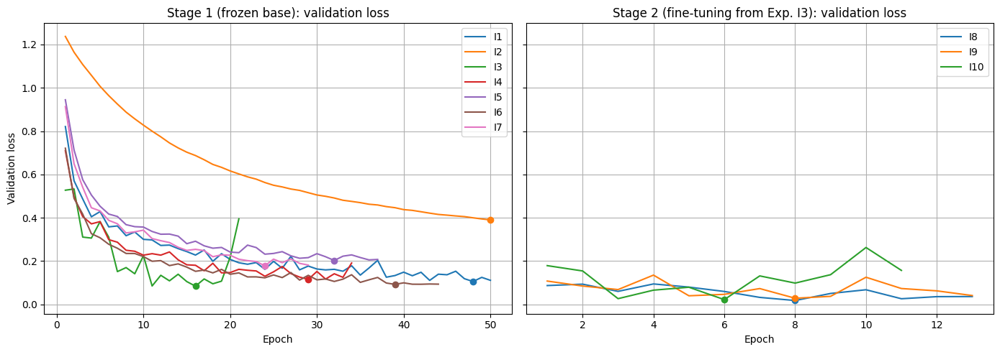

Final improved model: Exp. I8 (Fine-tune depth = from block 14, lr 1e-5)
Best epoch 8, validation loss 0.0176, validation accuracy 100.00%
Decision based on the validation set only; the test set was not used.


In [ ]:
# Author: Eman Khamdan (Member 2)
# Cell 7.3 - Improved-Model Results Table, Validation-Loss Chart and Selection

improved_df = pd.DataFrame(improved_results)
improved_df.to_csv(RESULTS_PATH / "improved_hyperparameter_results.csv", index=False)
display(improved_df)

# Figure D.2: validation loss per epoch for every experiment (dot = best epoch)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for exp, history in improved_histories.items():
    ax = axes[0] if exp in dict((e, 1) for e, *_ in STAGE1_PLAN) else axes[1]
    losses = history["val_loss"]
    line, = ax.plot(range(1, len(losses) + 1), losses, label=f"{exp}")
    best = int(np.argmin(losses))
    ax.scatter(best + 1, losses[best], color=line.get_color(), zorder=3)
axes[0].set_title("Stage 1 (frozen base): validation loss")
axes[1].set_title(f"Stage 2 (fine-tuning from Exp. {STAGE1_SELECTED}): validation loss")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(True)
    ax.legend()
axes[0].set_ylabel("Validation loss")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "figD_2_improved_experiment_val_loss.png", dpi=150, bbox_inches="tight")
plt.show()

# Final selection: lowest validation loss over the stage-1 winner and the fine-tuning runs
candidates = improved_df[(improved_df["Exp."] == STAGE1_SELECTED) | (improved_df["Stage"] == 2)]
final_row = candidates.loc[candidates["Val. loss"].idxmin()]
FINAL_EXP = final_row["Exp."]
FINAL_CONFIG = improved_configs[FINAL_EXP]
print(f"Final improved model: Exp. {FINAL_EXP} ({final_row['Parameter varied']} = {final_row['Value']})")
print(f"Best epoch {final_row['Best epoch']}, validation loss {final_row['Val. loss']}, "
      f"validation accuracy {final_row['Val. acc.']:.2%}")
print("Decision based on the validation set only; the test set was not used.")

### 7.3 Observations on the improved-model experiments (report Table 5.2)

| Exp. | Change | Val. loss | Observation |
|---|---|---|---|
| I1 | Reference (lr 0.001, batch 16, dropout 0.2) | 0.1054 | Best epoch 48 of 50: still improving, so lr 0.001 is slow for a new head |
| I2 | lr 0.0001 | 0.3900 | Too slow: reached the 50-epoch limit and underfits (training accuracy 89.6%) |
| **I3** | **lr 0.01** | **0.0839** | **Best stage-1 run**, converged by epoch 16: a linear head on fixed features tolerates large steps |
| I4 | batch 8 | 0.1151 | Slightly worse than the reference; unlike the baseline, the frozen model gains nothing from noisier updates |
| I5 | batch 32 | 0.2025 | Worse: only 8 updates per epoch, so it learns more slowly within the same patience |
| I6 | dropout 0.0 | 0.0922 | Better than the reference, but by 0.013 in loss on 30 images, which is within noise |
| I7 | dropout 0.5 | 0.1782 | Too strong: the head underfits (training accuracy 91.7%) |
| **I8** | **fine-tune from block 14, lr 1e-5** | **0.0176** | **Final model**: validation loss 79% lower than I3, validation accuracy 100% |
| I9 | fine-tune from block 11, lr 1e-5 | 0.0281 | 384,192 more trainable weights but no gain: deeper adaptation adds overfitting risk with 240 images |
| I10 | fine-tune from block 14, lr 1e-4 | 0.0218 | Faster (best epoch 6) and training accuracy 100%, but a slightly higher validation loss than I8 |

- **Most influential hyperparameter:** the learning rate. In stage 1 it moved the validation loss from 0.084 to 0.390,
  more than batch size (0.105 – 0.203) or dropout (0.092 – 0.178).
- **Biggest single gain:** fine-tuning the last blocks (I3 → I8), because the top MobileNetV2 features are adapted from
  ImageNet objects to leaf lesions. A 10 × smaller learning rate than in stage 1 kept the pre-trained filters from being overwritten.
- **Why loss and not accuracy:** four runs reach 100% validation accuracy (I6, I8 – I10), so accuracy cannot separate them;
  the validation loss also rewards confident correct predictions. With 30 validation images all these differences are
  uncertain, which is why the final comparison is made on the untouched test set in 8.0.

### 7.4 Overfitting control: does the regularisation actually help?

To *demonstrate* (not just claim) that the regularisation works, the final configuration
is trained a second time with **all overfitting controls switched off**: no augmentation,
no dropout and no early stopping (the full epoch budget, final-epoch weights kept). The
two-stage schedule, learning rates and batch size stay the same. Comparing the two
learning curves shows what the controls do (report Figure 5.3 and Table 5.3).

Exp. A1: saved result re-used (same settings, no retraining)
Exp. A2: saved result re-used (same settings, no retraining)


,Model,Reported epoch,Train loss,Val. loss,Gap (val - train),Train acc.,Val. acc.,Lowest val. loss (epoch)
0,Regularised (final model: augmentation + dropo...,24,0.0151,0.0176,0.0025,0.9917,1.0000,0.0176 (24)
1,"No regularisation (no augmentation, dropout 0,...",70,0.0000,0.1155,0.1155,1.0000,0.9667,0.0998 (54)


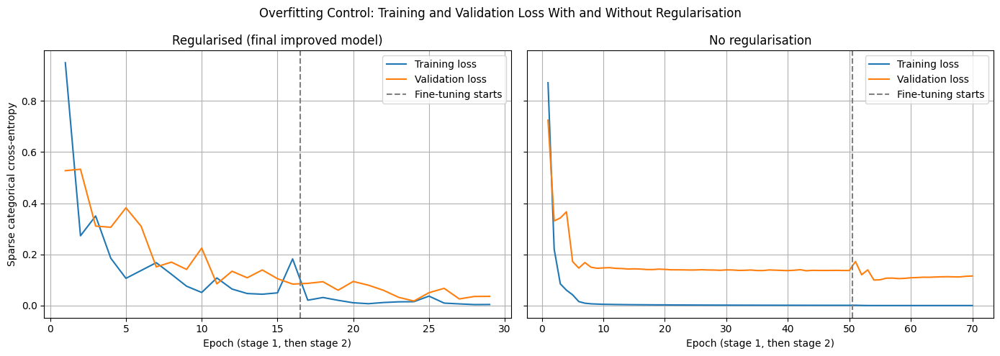

In [ ]:
# Author: Eman Khamdan (Member 2)
# Cell 7.4 - Overfitting-Control Ablation (validation set only)

final_is_fine_tuned = FINAL_CONFIG.get("fine_tune_from") is not None
STAGE1_UNREG_WEIGHTS = RESULTS_PATH / "improved_ablation_stage1.weights.h5"

# A1: stage 1 without augmentation, dropout or early stopping
abl1, abl1_history, abl1_model = train_improved(
    "A1", "No regularisation (stage 1)", "no aug / dropout 0 / no early stop", stage=1,
    learning_rate=STAGE1_CONFIG["learning_rate"], batch_size=STAGE1_CONFIG["batch_size"],
    dropout_rate=0.0, augment=False, early_stopping=False, max_epochs=IMPROVED_MAX_EPOCHS, verbose=0)
ablation_rows, ablation_history = [abl1], {k: list(v) for k, v in abl1_history.items()}

if final_is_fine_tuned:
    a2_settings = dict(stage=2, learning_rate=float(FINAL_CONFIG["learning_rate"]),
                       batch_size=int(FINAL_CONFIG["batch_size"]), dropout_rate=0.0,
                       fine_tune_from=FINAL_CONFIG["fine_tune_from"], augment=False,
                       early_stopping=False, max_epochs=FINE_TUNE_MAX_EPOCHS)
    a2_saved = saved_runs.get("A2", {}).get("settings", REPORT_RUN_SETTINGS["A2"])
    if abl1_model is None and a2_settings != a2_saved and not STAGE1_UNREG_WEIGHTS.exists():
        # A2 must be trained again (the final model's settings changed), and it starts from the A1
        # weights. A1 was re-used from file, so its weights are not in memory: train A1 again first.
        print("A2 must be trained again and needs the A1 weights - training A1 again first.")
        reuse_before, M2_REUSE_SAVED = M2_REUSE_SAVED, False
        abl1, abl1_history, abl1_model = train_improved(
            "A1", "No regularisation (stage 1)", "no aug / dropout 0 / no early stop", stage=1,
            learning_rate=STAGE1_CONFIG["learning_rate"], batch_size=STAGE1_CONFIG["batch_size"],
            dropout_rate=0.0, augment=False, early_stopping=False, max_epochs=IMPROVED_MAX_EPOCHS, verbose=0)
        M2_REUSE_SAVED = reuse_before
        ablation_rows, ablation_history = [abl1], {k: list(v) for k, v in abl1_history.items()}
    if abl1_model is not None:
        abl1_model.save_weights(str(STAGE1_UNREG_WEIGHTS))
    # A2: the same fine-tuning as the final model, again without any regularisation
    abl2, abl2_history, _ = train_improved(
        "A2", "No regularisation (stage 2)", "no aug / dropout 0 / no early stop", stage=2,
        learning_rate=FINAL_CONFIG["learning_rate"], batch_size=FINAL_CONFIG["batch_size"],
        dropout_rate=0.0, fine_tune_from=FINAL_CONFIG["fine_tune_from"],
        init_weights=str(STAGE1_UNREG_WEIGHTS), augment=False, early_stopping=False,
        max_epochs=FINE_TUNE_MAX_EPOCHS, verbose=0)
    ablation_rows.append(abl2)
    ablation_history = {k: ablation_history[k] + list(abl2_history[k]) for k in ablation_history}


def stitched_history(final_exp):
    # Stage-1 history (up to its restored best epoch) followed by the stage-2 history
    h1 = improved_histories[STAGE1_SELECTED]
    if improved_configs[final_exp].get("fine_tune_from") is None:
        return {k: list(v) for k, v in h1.items()}, None
    keep = int(improved_df.loc[improved_df["Exp."] == STAGE1_SELECTED, "Best epoch"].iloc[0])
    h2 = improved_histories[final_exp]
    return {k: list(h1[k][:keep]) + list(h2[k]) for k in h1}, keep


reg_history, ft_start = stitched_history(FINAL_EXP)
unreg_switch = len(abl1_history["loss"]) if final_is_fine_tuned else None


def gap_row(name, h, reported_epoch):
    i = reported_epoch - 1
    return {"Model": name, "Reported epoch": reported_epoch,
            "Train loss": round(h["loss"][i], 4), "Val. loss": round(h["val_loss"][i], 4),
            "Gap (val - train)": round(h["val_loss"][i] - h["loss"][i], 4),
            "Train acc.": round(h["accuracy"][i], 4), "Val. acc.": round(h["val_accuracy"][i], 4),
            "Lowest val. loss (epoch)": f"{min(h['val_loss']):.4f} ({int(np.argmin(h['val_loss'])) + 1})"}

final_epoch_overall = ((ft_start or 0) + int(final_row["Best epoch"])) if final_is_fine_tuned else int(final_row["Best epoch"])
ablation_table = pd.DataFrame([
    gap_row("Regularised (final model: augmentation + dropout + early stopping)", reg_history, final_epoch_overall),
    gap_row("No regularisation (no augmentation, dropout 0, no early stopping)", ablation_history,
            len(ablation_history["loss"])),
])
ablation_table.to_csv(RESULTS_PATH / "improved_overfitting_ablation.csv", index=False)
display(ablation_table)

# Figure 5.3: training vs validation loss, regularised vs not
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, h, title, switch in [(axes[0], reg_history, "Regularised (final improved model)", ft_start),
                             (axes[1], ablation_history, "No regularisation", unreg_switch)]:
    epochs = range(1, len(h["loss"]) + 1)
    ax.plot(epochs, h["loss"], label="Training loss")
    ax.plot(epochs, h["val_loss"], label="Validation loss")
    if switch:
        ax.axvline(switch + 0.5, color="grey", linestyle="--", label="Fine-tuning starts")
    ax.set_title(title)
    ax.set_xlabel("Epoch (stage 1, then stage 2)")
    ax.grid(True)
    ax.legend()
axes[0].set_ylabel("Sparse categorical cross-entropy")
fig.suptitle("Overfitting Control: Training and Validation Loss With and Without Regularisation")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "fig5_3_overfitting_control.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.4 Interpretation of the overfitting-control ablation (Figure 5.3, report Table 5.3)

- **Without regularisation the model memorises the training set.** Training accuracy is 100% from epoch 6 and the
  training loss falls to about 0.000, while the validation loss stops improving at about 0.14 in stage 1 and ends at
  **0.1155** after fine-tuning. The gap between validation and training loss is 0.1155: classic overfitting.
- **With the controls** (augmentation, dropout 0.2, early stopping) the final model has validation loss **0.0176**,
  6.6 times lower, a gap of only **0.0025**, and validation accuracy 100% instead of 96.7%.
- **Early stopping alone would not close the gap.** Even the best epoch of the unregularised run (0.0998 at epoch 54) is
  5.7 times worse than the regularised model, so augmentation and dropout also matter, not only the training length.
- **Which control matters most?** The ablation switches all three off together, so it cannot separate them. Exp. I6
  (only dropout removed) was not worse than the reference, which suggests that **data augmentation** is the main
  regulariser here: with 240 images, random flips, rotations and zooms effectively give the model more varied examples.

### 7.5 Final improved model: learning curves and saved model

The final model (weights of its best epoch restored) is saved as
`results/improved_mobilenetv2_final.keras` and evaluated **once** on the
test set in Section 8.0. The learning curves are Figure 5.2 in the report.

Final improved model: /content/IT8414_Tomato_Project/results/improved_mobilenetv2_final.keras


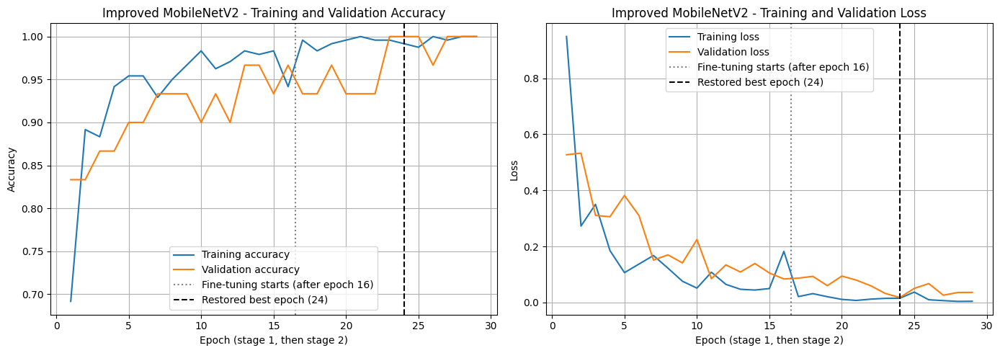

Validation loss 0.0176 | validation accuracy 100.00% (table: 0.0176 / 100.00%)


In [ ]:
# Author: Eman Khamdan (Member 2)
# Cell 7.5 - Final Improved Model: Learning Curves, Validation Check and Save

FINAL_INFO = RESULTS_PATH / "improved_mobilenetv2_final.json"    # which run the saved file holds
saved_final = json.loads(FINAL_INFO.read_text())["experiment"] if FINAL_INFO.exists() else "I8"
if improved_models.get(FINAL_EXP) is None and FINAL_EXP != saved_final:
    # A live change made another (re-used) run the best one: train it again so the right model is used
    print(f"Exp. {FINAL_EXP} is now selected, but {FINAL_MODEL_FILE.name} holds Exp. {saved_final} - training it again.")
    reuse_before, M2_REUSE_SAVED = M2_REUSE_SAVED, False
    _, improved_histories[FINAL_EXP], improved_models[FINAL_EXP] = train_improved(
        FINAL_EXP, final_row["Parameter varied"], final_row["Value"], stage=int(final_row["Stage"]),
        init_weights=str(STAGE1_WEIGHTS) if int(final_row["Stage"]) == 2 else None, **FINAL_CONFIG)
    M2_REUSE_SAVED = reuse_before
if improved_models.get(FINAL_EXP) is not None:
    improved_model = improved_models[FINAL_EXP]
    improved_model.save(str(FINAL_MODEL_FILE))
    FINAL_INFO.write_text(json.dumps({"experiment": str(FINAL_EXP)}))
else:
    improved_model = tf.keras.models.load_model(str(FINAL_MODEL_FILE))   # M2_REUSE_SAVED = True
print("Final improved model:", FINAL_MODEL_FILE)

# Figure 5.2: accuracy and loss over both training stages
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs = range(1, len(reg_history["loss"]) + 1)
for ax, metric, title in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
    ax.plot(epochs, reg_history[metric], label=f"Training {title.lower()}")
    ax.plot(epochs, reg_history[f"val_{metric}"], label=f"Validation {title.lower()}")
    if ft_start:
        ax.axvline(ft_start + 0.5, color="grey", linestyle=":", label=f"Fine-tuning starts (after epoch {ft_start})")
    ax.axvline(final_epoch_overall, color="black", linestyle="--", label=f"Restored best epoch ({final_epoch_overall})")
    ax.set_title(f"Improved MobileNetV2 - Training and Validation {title}")
    ax.set_xlabel("Epoch (stage 1, then stage 2)")
    ax.set_ylabel(title)
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_PATH / "fig5_2_improved_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Check: the saved model reproduces the best-epoch validation loss
val_loss_check, val_acc_check = improved_model.evaluate(make_dataset(val_df), verbose=0)
print(f"Validation loss {val_loss_check:.4f} | validation accuracy {val_acc_check:.2%} "
      f"(table: {final_row['Val. loss']} / {final_row['Val. acc.']:.2%})")

### 7.5 Interpretation of the improved-model learning curves (Figure 5.2)

- **Stage 1 (epochs 1 – 16, frozen base):** validation accuracy is already **83.3% after one epoch**, compared with
  33.3% for the baseline, because the ImageNet features already separate the classes. Validation loss falls from
  0.527 to 0.084 at epoch 16.
- **Validation loss below training loss** in stage 1 (epoch 16: 0.084 vs 0.182) is expected: augmentation and dropout
  are active only during training, so training batches are harder than the clean validation images.
- **Stage 2 (epochs 17 – 29, fine-tuning from block 14):** validation loss drops further to **0.0176 at epoch 24**
  (stage-2 epoch 8), with training loss 0.015. After that the training loss keeps falling (to 0.004) while the validation
  loss rises again (0.026 – 0.067, never back down to 0.0176): the start of overfitting. Early stopping restored epoch 24, just before it.
- **Diagnosis:** at the restored epoch there is **no overfitting** (gap 0.0025) and **no underfitting** (training
  accuracy 99.2%). The 100% validation accuracy is optimistic, because the 30 validation images were also used to choose
  among 10 runs; the test set in 8.1 gives the fair estimate (83.3%).

### 7.6 Activation hook for Grad-CAM (used in 9.0)

In this model MobileNetV2 is a *nested* model, so its last convolutional output
(`out_relu`, 7 × 7 × 1,280) cannot be read with a simple `model.get_layer("out_relu")`
from the outer model. `make_activation_model()` re-connects the trained layers so that one
call returns **both** the last feature maps and the class probabilities — exactly what
Grad-CAM needs. Augmentation is skipped because it is inactive at prediction time
anyway. The check below uses a **validation** image; the test set stays untouched.

In [ ]:
# Author: Eman Khamdan (Member 2)
# Cell 7.6 - Activation Model for Grad-CAM (Member 3 uses it in 9.0)

def make_activation_model(model):
    # Returns a model: image (0-1) -> [out_relu feature maps (7x7x1280), class probabilities]
    inputs = tf.keras.Input(shape=IMPROVED_INPUT_SHAPE)
    x = model.get_layer("rescale_to_minus1_1")(inputs)
    feature_maps = model.get_layer(BASE_NAME)(x, training=False)    # output of 'out_relu'
    y = model.get_layer("global_avg_pool")(feature_maps)
    y = model.get_layer("head_dropout")(y, training=False)
    probabilities = model.get_layer("output_softmax")(y)
    return tf.keras.Model(inputs, [feature_maps, probabilities], name="improved_activations")


activation_model = make_activation_model(improved_model)
sample_image, sample_label = next(iter(make_dataset(val_df.iloc[:1], batch_size=1)))
maps, probs = activation_model(sample_image)
direct = improved_model(sample_image, training=False)
print("Feature maps:", tuple(maps.shape), "| probabilities:", np.round(probs.numpy()[0], 4))
print("Same prediction as the full model:", np.allclose(probs.numpy(), direct.numpy(), atol=1e-5))
print("True class of this validation image:", CLASS_NAMES[int(sample_label[0])])

Feature maps: (1, 7, 7, 1280) | probabilities: [0.9999 0.     0.    ]
Same prediction as the full model: True
True class of this validation image: Healthy


### 7.7 Improved-model summary and saved numbers

The next cell compares the two final models **on the validation set** (the test-set
comparison follows in 8.0), and writes every number used in report Sections
4 and 5.1 – 5.2 to `results/M2_NUMBERS_FOR_REPORT.txt` and
`results/improved_validation_results.json`.

In [ ]:
# Author: Eman Khamdan (Member 2)
# Cell 7.7 - Final Numbers and Ready-to-Paste Text (report Sections 4, 5.1, 5.2)

pct = lambda x: f"{x * 100:.2f}%"
lines = []
out = lines.append

baseline_json = RESULTS_PATH / "baseline_test_results.json"
baseline_info = json.loads(baseline_json.read_text()) if baseline_json.exists() else {}
base_val_acc = baseline_info.get("validation_accuracy", float("nan"))
base_val_loss = baseline_info.get("validation_loss", float("nan"))

tmp = build_improved_model()
total_params = tmp.count_params()
head_params = count_params(tmp.trainable_weights)
set_fine_tuning(tmp, 14)
ft14_params = count_params(tmp.trainable_weights)
set_fine_tuning(tmp, 11)
ft11_params = count_params(tmp.trainable_weights)
del tmp

ref = improved_df[improved_df["Exp."] == "I1"].iloc[0]
s1 = improved_df[improved_df["Exp."] == STAGE1_SELECTED].iloc[0]
fin = final_row
fin_cfg = FINAL_CONFIG
lr_stage1 = STAGE1_CONFIG["learning_rate"]
total_time = improved_df["Train time (min)"].sum()
final_time = float(s1["Train time (min)"]) + (float(fin["Train time (min)"]) if fin["Stage"] == 2 else 0.0)

out("=== M2-A. REPORT TABLE 4.4 (improved model parameters) ===")
out(f"Total parameters: {total_params:,} | trainable in stage 1 (head): {head_params:,} | "
    f"trainable when fine-tuning from block 14: {ft14_params:,} | from block 11: {ft11_params:,}")

out("")
out("=== M2-B. REPORT TABLE 4.2 (training configuration of the final improved model) ===")
out(f"Stage 1: Adam lr {lr_stage1:g}, batch {STAGE1_CONFIG['batch_size']}, dropout {STAGE1_CONFIG['dropout_rate']}, "
    f"early stopping (max {IMPROVED_MAX_EPOCHS}, patience {IMPROVED_PATIENCE}); best epoch {s1['Best epoch']} "
    f"(stopped at {s1['Epochs run']})")
if fin["Stage"] == 2:
    out(f"Stage 2: fine-tuned from block {fin_cfg['fine_tune_from']}, Adam lr {fin_cfg['learning_rate']:g}, "
        f"early stopping (max {FINE_TUNE_MAX_EPOCHS}, patience {IMPROVED_PATIENCE}); best epoch {fin['Best epoch']} "
        f"(stopped at {fin['Epochs run']}); trainable weights {int(fin['Trainable params']):,}")
else:
    out("Stage 2: not used - no fine-tuning run had a lower validation loss than stage 1")
out(f"Hardware: {TRAIN_HARDWARE} | Final model training time: {final_time:.1f} min | all {len(improved_df)} runs: {total_time:.1f} min")

out("")
out("=== M2-C. REPORT TABLE 5.2 (Exp | Stage | Parameter | Value | Best epoch (of run) | Train acc | Val acc | Val loss | Trainable params) ===")
for _, r in improved_df.iterrows():
    out(f"{r['Exp.']} | {r['Stage']} | {r['Parameter varied']} | {r['Value']} | {r['Best epoch']} ({r['Epochs run']}) | "
        f"{pct(r['Train acc.'])} | {pct(r['Val. acc.'])} | {r['Val. loss']:.4f} | {int(r['Trainable params']):,}")

out("")
out("=== M2-D. TEXT for report 5.2 (selection) ===")
out(f"Stage 1 selected Exp. {STAGE1_SELECTED} ({s1['Parameter varied']} = {s1['Value']}) with validation loss "
    f"{s1['Val. loss']:.4f} (reference I1: {ref['Val. loss']:.4f}). The final improved model is Exp. {FINAL_EXP} "
    f"({fin['Parameter varied']} = {fin['Value']}): validation loss {fin['Val. loss']:.4f}, validation accuracy "
    f"{pct(fin['Val. acc.'])} at best epoch {fin['Best epoch']}. Baseline (final): validation loss {base_val_loss:.4f}, "
    f"validation accuracy {pct(base_val_acc)}. Decisions used the validation set only.")

out("")
out("=== M2-E. TEXT for report 5.1 (Figure 5.2, learning curves) ===")
h = reg_history
i = final_epoch_overall - 1
out(f"Stage 1 started at validation loss {h['val_loss'][0]:.4f} and validation accuracy {pct(h['val_accuracy'][0])} after one epoch. "
    f"At the restored best epoch ({final_epoch_overall} overall) training loss was {h['loss'][i]:.4f} and validation loss "
    f"{h['val_loss'][i]:.4f}; training accuracy {pct(h['accuracy'][i])}, validation accuracy {pct(h['val_accuracy'][i])}.")

out("")
out("=== M2-F. REPORT TABLE 5.3 (overfitting-control ablation) ===")
for _, r in ablation_table.iterrows():
    out(f"{r['Model']} | epoch {r['Reported epoch']} | train loss {r['Train loss']:.4f} | val loss {r['Val. loss']:.4f} | "
        f"gap {r['Gap (val - train)']:.4f} | train acc {pct(r['Train acc.'])} | val acc {pct(r['Val. acc.'])} | "
        f"lowest val loss {r['Lowest val. loss (epoch)']}")

out("")
out("=== M2-G. VALIDATION comparison (test-set comparison = Member 3, Cell 8.0) ===")
out(f"Baseline CNN: val acc {pct(base_val_acc)}, val loss {base_val_loss:.4f}, 101,699 params | "
    f"Improved MobileNetV2: val acc {pct(fin['Val. acc.'])}, val loss {fin['Val. loss']:.4f}, {total_params:,} params")

report_text = "\n".join(lines)
print(report_text)
(RESULTS_PATH / "M2_NUMBERS_FOR_REPORT.txt").write_text(report_text)

improved_info = {
    "final_experiment": str(FINAL_EXP), "stage1_selected": str(STAGE1_SELECTED),
    "final_config": {k: (float(v) if isinstance(v, (int, float)) and not isinstance(v, bool) else v)
                     for k, v in FINAL_CONFIG.items()},
    "validation_accuracy": float(fin["Val. acc."]), "validation_loss": float(fin["Val. loss"]),
    "best_epoch_stage": int(fin["Best epoch"]), "best_epoch_overall": int(final_epoch_overall),
    "parameters_total": int(total_params), "trainable_parameters_final": int(fin["Trainable params"]),
    "train_time_min": round(final_time, 1), "hardware": TRAIN_HARDWARE,
    "model_file": FINAL_MODEL_FILE.name,
    "grad_cam_layer": "out_relu inside mobilenetv2_1.00_224 (use make_activation_model in Cell 7.6)",
    "input": "224 x 224 x 3, pixels 0-1 (rescaling to -1..1 is inside the model)",
}
(RESULTS_PATH / "improved_validation_results.json").write_text(json.dumps(improved_info, indent=2))
print("\nSaved results/M2_NUMBERS_FOR_REPORT.txt and results/improved_validation_results.json")

=== M2-A. REPORT TABLE 4.4 (improved model parameters) ===
Total parameters: 2,261,827 | trainable in stage 1 (head): 3,843 | trainable when fine-tuning from block 14: 1,514,563 | from block 11: 1,898,755

=== M2-B. REPORT TABLE 4.2 (training configuration of the final improved model) ===
Stage 1: Adam lr 0.01, batch 16, dropout 0.2, early stopping (max 50, patience 5); best epoch 16 (stopped at 21)
Stage 2: fine-tuned from block 14, Adam lr 1e-05, early stopping (max 20, patience 5); best epoch 8 (stopped at 13); trainable weights 1,514,563
Hardware: CPU | Final model training time: 1.3 min | all 10 runs: 11.1 min

=== M2-C. REPORT TABLE 5.2 (Exp | Stage | Parameter | Value | Best epoch (of run) | Train acc | Val acc | Val loss | Trainable params) ===
I1 | 1 | Reference | lr 0.001 / bs 16 / dropout 0.2 | 48 (50) | 98.33% | 96.67% | 0.1054 | 3,843
I2 | 1 | Learning rate | 0.0001 | 50 (50) | 89.58% | 86.67% | 0.3900 | 3,843
I3 | 1 | Learning rate | 0.01 | 16 (21) | 94.17% | 96.67% | 0.0

### 7.7 Objects used in Sections 8.0 – 9.0

| Name | What it is |
|---|---|
| `improved_model` | Final improved model (best epoch restored); also `results/improved_mobilenetv2_final.keras` |
| `make_activation_model(model)` | Returns `[out_relu feature maps, probabilities]` for Grad-CAM (Cell 7.6) |
| `improved_df` | All improved-model experiments (report Table 5.2) |
| `FINAL_EXP`, `FINAL_CONFIG` | Which run was selected and its settings |

- The model takes the **same 0 – 1 images** as the baseline, so `predict_leaf(path, improved_model)`
  and the evaluation code in Cell 5.8 work unchanged.
- The test set has **not** been used in 6.0 – 7.0. `improved_model` is evaluated on `test_df` **once**, in 8.0.

In [ ]:
# Author: Eman Khamdan (Member 2)
# Cell 7.7 - Download Member 2's New Results (Colab storage is temporary)

new_files = ["improved_mobilenetv2_final.keras", "improved_hyperparameter_results.csv", "improved_runs.json",
             "improved_overfitting_ablation.csv", "improved_layer_table.csv", "improved_validation_results.json",
             "M2_NUMBERS_FOR_REPORT.txt", "improved_stage1_selected.weights.h5",
             "figures/fig4_1_overall_workflow.png", "figures/fig5_2_improved_learning_curves.png",
             "figures/fig5_3_overfitting_control.png", "figures/figD_2_improved_experiment_val_loss.png"]
DOWNLOAD_MEMBER2_RESULTS = False    # True: ZIP of the new results (Colab storage is temporary)

if DOWNLOAD_MEMBER2_RESULTS:
    archive = RESULTS_PATH.parent / f"IT8414_Member2_results_{time.strftime('%Y-%m-%d')}.zip"
    with zipfile.ZipFile(archive, "w") as z:
        for name in new_files:
            if (RESULTS_PATH / name).exists():
                z.write(RESULTS_PATH / name, f"IT8414_Tomato_Project/results/{name}")
    print("ZIP:", archive, round(archive.stat().st_size / 1e6, 1), "MB")
    try:
        from google.colab import files
        files.download(str(archive))
    except ImportError:
        print("Not running in Colab - the ZIP stays in the project folder.")
else:
    print("No download needed: the results are in results/ and in the GitHub repository.")


ZIP: /content/IT8414_Tomato_Project/IT8414_Member2_results_2026-11-24.zip 32.0 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8.0 Test-Set Evaluation

This section tests the two final models on the **held-out test set** (30 images, 10 per class): the **baseline CNN** (Exp. 2, Section 5) and **MobileNetV2 transfer learning** (Exp. I8, Section 7).

**Why the test set is used only now.** Every decision so far (split ratio, hyperparameters, final model) was made on the validation set. Each model is evaluated on the test set **once**, so the result is an unbiased estimate of performance on unseen leaves. (The baseline's test score was first shown in 5.8; 8.1 re-scores the same saved baseline model and reproduces exactly the same numbers, so that both models appear in one table. Nothing was changed after seeing either test result.)

**Metrics.** Accuracy; precision, recall and F1 per class and as a macro average; the confusion matrix; and macro ROC-AUC (one-vs-rest), which uses the predicted probabilities rather than only the final label.

**Why these metrics.** The classes are balanced (10 per class), so accuracy is not distorted by imbalance, but the errors do not cost the same. A **Late Blight leaf predicted as Healthy** is the most costly mistake, because the farmer would not treat the plant and the disease would spread. Confusing the two blights is less serious, because the plant is still treated. **Late Blight recall** and **macro F1** are therefore the main metrics. With only 30 test images, one image changes accuracy by 3.3 percentage points, so 95% bootstrap confidence intervals are reported with accuracy and F1.

In [ ]:
# Author: Abrar
# Cell 8.1 - Test-Set Evaluation of Both Final Models (report Table 5.4)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


def evaluate_model(model, df):
    # Predicts every image in df once, with the same preprocessing as training (no augmentation)
    probabilities = model.predict(make_dataset(df), verbose=0)
    true_labels = df["label_id"].values
    predicted_labels = np.argmax(probabilities, axis=1)
    return true_labels, predicted_labels, probabilities


def bootstrap_ci(true_labels, predicted_labels, n_resamples=1000):
    # 95% confidence intervals for accuracy and macro F1 (same method and seed as Cell 5.8)
    rng = np.random.default_rng(SEED)
    accuracies, f1_scores = [], []
    for _ in range(n_resamples):
        idx = rng.integers(0, len(true_labels), len(true_labels))
        accuracies.append(accuracy_score(true_labels[idx], predicted_labels[idx]))
        f1_scores.append(f1_score(true_labels[idx], predicted_labels[idx], average="macro", zero_division=0))
    return np.percentile(accuracies, [2.5, 97.5]), np.percentile(f1_scores, [2.5, 97.5])


# The two final models: Member 1's baseline (Exp. 2) and Member 2's MobileNetV2 (Exp. I8)
m3_models = {"Baseline CNN": baseline_model, "MobileNetV2": improved_model}
m3_train_time = {"Baseline CNN": float(best_row["Train time (min)"]),   # from Cell 5.7
                 "MobileNetV2": final_time}                             # from Cell 7.7

m3_results = {}   # predictions per model, used again in 8.2 and 9.0
m3_rows = []
for m3_name, m3_model in m3_models.items():
    m3_true, m3_pred, m3_prob = evaluate_model(m3_model, test_df)   # the test set is used here, once
    m3_results[m3_name] = {"true": m3_true, "pred": m3_pred, "prob": m3_prob}
    m3_acc_ci, m3_f1_ci = bootstrap_ci(m3_true, m3_pred)

    m3_rows.append({
        "Model": m3_name,
        "Accuracy": accuracy_score(m3_true, m3_pred),
        "Accuracy 95% CI": f"{m3_acc_ci[0]:.1%} - {m3_acc_ci[1]:.1%}",
        "Precision (macro)": precision_score(m3_true, m3_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(m3_true, m3_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(m3_true, m3_pred, average="macro", zero_division=0),
        "F1 95% CI": f"{m3_f1_ci[0]:.1%} - {m3_f1_ci[1]:.1%}",
        "Late Blight recall": recall_score(m3_true, m3_pred, labels=[2], average=None)[0],
        "ROC-AUC (macro)": roc_auc_score(m3_true, m3_prob, multi_class="ovr"),
        "Params": m3_model.count_params(),
        "Train time (min)": m3_train_time[m3_name],
    })

    print(f"========== {m3_name} - test set ({len(m3_true)} images) ==========")
    print(classification_report(m3_true, m3_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

# Table 5.4: one table comparing both models
m3_table = pd.DataFrame(m3_rows)
display(m3_table.round(4))
m3_table.to_csv(RESULTS_PATH / "comparison_test_results.csv", index=False)
print("Saved results/comparison_test_results.csv")

========== Baseline CNN - test set (30 images) ==========
              precision    recall  f1-score   support

     Healthy     0.7692    1.0000    0.8696        10
Early Blight     0.7273    0.8000    0.7619        10
 Late Blight     1.0000    0.6000    0.7500        10

    accuracy                         0.8000        30
   macro avg     0.8322    0.8000    0.7938        30
weighted avg     0.8322    0.8000    0.7938        30



========== MobileNetV2 - test set (30 images) ==========
              precision    recall  f1-score   support

     Healthy     0.9000    0.9000    0.9000        10
Early Blight     0.7778    0.7000    0.7368        10
 Late Blight     0.8182    0.9000    0.8571        10

    accuracy                         0.8333        30
   macro avg     0.8320    0.8333    0.8313        30
weighted avg     0.8320    0.8333    0.8313        30



,Model,Accuracy,Accuracy 95% CI,Precision (macro),Recall (macro),F1 (macro),F1 95% CI,Late Blight recall,ROC-AUC (macro),Params,Train time (min)
0,Baseline CNN,0.8000,66.7% - 93.3%,0.8322,0.8000,0.7938,62.5% - 91.7%,0.6,0.8950,101699,0.3
1,MobileNetV2,0.8333,66.7% - 96.7%,0.8320,0.8333,0.8313,66.2% - 96.1%,0.9,0.9633,2261827,1.3


Saved results/comparison_test_results.csv


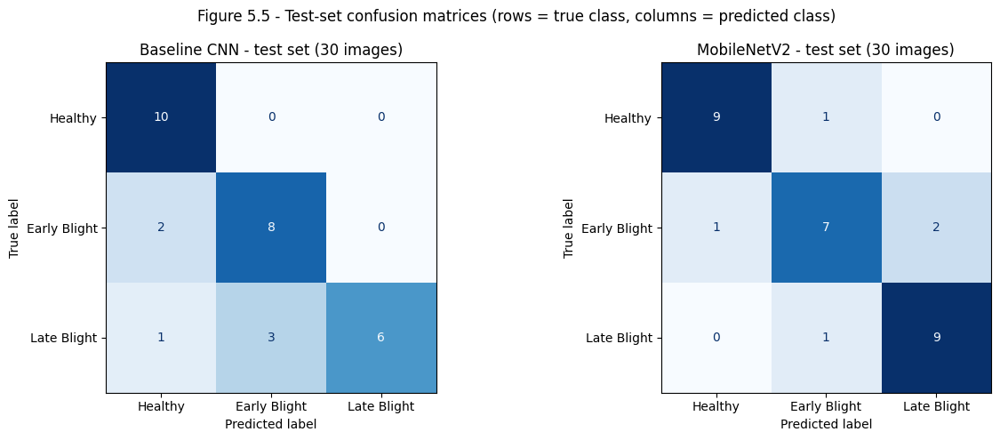

========== Baseline CNN ==========
Healthy: 10/10 correct
Early Blight: 8/10 correct
    2 predicted as Healthy
Late Blight: 6/10 correct
    1 predicted as Healthy
    3 predicted as Early Blight
Late Blight predicted as Healthy (most costly error): 1

========== MobileNetV2 ==========
Healthy: 9/10 correct
    1 predicted as Early Blight
Early Blight: 7/10 correct
    1 predicted as Healthy
    2 predicted as Late Blight
Late Blight: 9/10 correct
    1 predicted as Early Blight
Late Blight predicted as Healthy (most costly error): 0



,Model,Class,Precision,Recall,F1,Correct
0,Baseline CNN,Healthy,0.7692,1.0,0.8696,10/10
1,Baseline CNN,Early Blight,0.7273,0.8,0.7619,8/10
2,Baseline CNN,Late Blight,1.0000,0.6,0.7500,6/10
3,MobileNetV2,Healthy,0.9000,0.9,0.9000,9/10
4,MobileNetV2,Early Blight,0.7778,0.7,0.7368,7/10
5,MobileNetV2,Late Blight,0.8182,0.9,0.8571,9/10


Saved results/comparison_test_per_class.csv and figures/fig5_5_test_confusion_matrices.png


In [ ]:
# Author: Abrar
# Cell 8.2 - Confusion Matrices and Per-Class Results (Figure 5.5, report Table 5.5)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
m3_cms = {}
for ax, (m3_name, r) in zip(axes, m3_results.items()):
    m3_cms[m3_name] = confusion_matrix(r["true"], r["pred"], labels=[0, 1, 2])
    ConfusionMatrixDisplay(m3_cms[m3_name], display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{m3_name} - test set ({len(r['true'])} images)")
plt.suptitle("Figure 5.5 - Test-set confusion matrices (rows = true class, columns = predicted class)")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "fig5_5_test_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

# Where do the mistakes go? (read each row of the confusion matrix)
for m3_name, m3_cm in m3_cms.items():
    print(f"========== {m3_name} ==========")
    for i, true_name in enumerate(CLASS_NAMES):
        print(f"{true_name}: {m3_cm[i, i]}/{m3_cm[i].sum()} correct")
        for j, predicted_name in enumerate(CLASS_NAMES):
            if j != i and m3_cm[i, j] > 0:
                print(f"    {m3_cm[i, j]} predicted as {predicted_name}")
    print(f"Late Blight predicted as Healthy (most costly error): {m3_cms[m3_name][2, 0]}\n")

# Table 5.5: precision, recall and F1 per class for both models
m3_class_rows = []
for m3_name, r in m3_results.items():
    p = precision_score(r["true"], r["pred"], labels=[0, 1, 2], average=None, zero_division=0)
    rc = recall_score(r["true"], r["pred"], labels=[0, 1, 2], average=None, zero_division=0)
    f = f1_score(r["true"], r["pred"], labels=[0, 1, 2], average=None, zero_division=0)
    for i, class_name in enumerate(CLASS_NAMES):
        m3_class_rows.append({"Model": m3_name, "Class": class_name, "Precision": p[i], "Recall": rc[i],
                              "F1": f[i], "Correct": f"{m3_cms[m3_name][i, i]}/{m3_cms[m3_name][i].sum()}"})
m3_class_table = pd.DataFrame(m3_class_rows)
display(m3_class_table.round(4))
m3_class_table.to_csv(RESULTS_PATH / "comparison_test_per_class.csv", index=False)
print("Saved results/comparison_test_per_class.csv and figures/fig5_5_test_confusion_matrices.png")

### 8.3 Interpretation of the test results

**Overall.** MobileNetV2 reached 83.3% test accuracy and 83.1% macro F1, against 80.0% and 79.4% for the baseline CNN. The difference in accuracy is only **one image**, and the 95% confidence intervals overlap almost completely (66.7–96.7% vs 66.7–93.3%). On overall accuracy alone, the test set cannot show that one model is better.

**Where the models differ.** The difference is in *which* leaves are missed:
- **Late Blight recall rose from 60% to 90%** (6/10 → 9/10). The baseline missed 4 Late Blight leaves (3 as Early Blight, 1 as Healthy); MobileNetV2 missed one, predicted as Early Blight.
- **Diseased leaves predicted as Healthy** (the errors that leave a plant untreated) fell from **3 to 1**, and the most costly error (Late Blight → Healthy) fell from 1 to 0.
- **Macro ROC-AUC rose from 0.895 to 0.963**, so MobileNetV2's probabilities separate the classes better, not only its final labels.

**Trade-off.** MobileNetV2 is weaker on **Early Blight** (7/10): two leaves were predicted as Late Blight, which is a less serious error because the plant is still treated, and one as Healthy. It also raised one false alarm on a Healthy leaf. The baseline's 100% Healthy recall comes partly from predicting Healthy too often (precision 76.9%).

**Validation vs test.** Both models scored lower on test than on validation (baseline 90.0% → 80.0%, MobileNetV2 100% → 83.3%). The validation set has only 30 images and was used to choose the best of several runs, so the validation scores are optimistic; the test set gives the fairer estimate.

## 9.0 Interpretability and Error Analysis

This section looks at **why** the models make mistakes, in two ways:

1. **Error analysis (9.1–9.2).** Every misclassified test leaf is shown with its true class, predicted class and confidence, so the failure patterns can be seen rather than only counted. Leaves misclassified by both models point to images that are genuinely hard or ambiguous.
2. **Grad-CAM (9.3–9.4).** Gradient-weighted Class Activation Mapping shows which regions of the leaf the model used for its prediction. It takes the gradient of the predicted class score with respect to the last convolutional feature maps (`conv3` for the baseline, `out_relu` for MobileNetV2), weights each feature map by its average gradient, and overlays the result as a heatmap. A trustworthy model should focus on the **lesions**, not on the background or the leaf edge.

The test predictions from 8.1 are re-used; no model is retrained and the test set is not used to change anything.

,Model,Image,True class,Predicted,Confidence,Prob. of true class
0,Baseline CNN,7d9f4bd8-6a4...,Late Blight,Early Blight,0.694,0.241
1,Baseline CNN,48dd3efc-400...,Early Blight,Healthy,0.518,0.330
2,Baseline CNN,24379205-969...,Early Blight,Healthy,0.412,0.351
3,Baseline CNN,5ad08690-955...,Late Blight,Early Blight,0.770,0.229
4,Baseline CNN,b6b9bd13-78e...,Late Blight,Healthy,0.871,0.028
5,Baseline CNN,f84a91cc-ad1...,Late Blight,Early Blight,0.910,0.085
6,MobileNetV2,48dd3efc-400...,Early Blight,Healthy,0.902,0.069
7,MobileNetV2,dc64e0f0-9f5...,Early Blight,Late Blight,0.983,0.017
8,MobileNetV2,1430346f-f3f...,Late Blight,Early Blight,0.696,0.304
9,MobileNetV2,30e6be40-743...,Early Blight,Late Blight,0.575,0.425


Misclassified - baseline: 6, MobileNetV2: 5, both models: 1 (test indices [1])


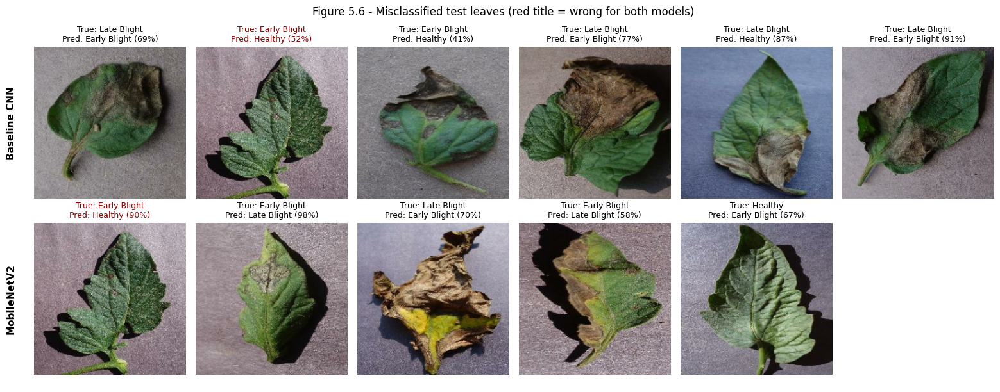

In [ ]:
# Author: Abrar
# Cell 9.1 - Error Analysis: Which Test Leaves Were Misclassified? (Figure 5.6)

# Table of every misclassified test image, for both models
m3_error_rows = []
for m3_name, r in m3_results.items():
    for i in np.where(r["pred"] != r["true"])[0]:
        m3_error_rows.append({
            "Model": m3_name,
            "Image": Path(test_df["image_path"].iloc[i]).name[:12] + "...",
            "True class": CLASS_NAMES[r["true"][i]],
            "Predicted": CLASS_NAMES[r["pred"][i]],
            "Confidence": r["prob"][i].max(),
            "Prob. of true class": r["prob"][i][r["true"][i]],
            "test_index": i,
        })
m3_errors = pd.DataFrame(m3_error_rows)
display(m3_errors.drop(columns="test_index").round(3))
m3_errors.to_csv(RESULTS_PATH / "comparison_misclassified_test_images.csv", index=False)

# Images that both models got wrong (likely hard or ambiguous leaves)
m3_wrong = {name: set(int(i) for i in np.where(r["pred"] != r["true"])[0]) for name, r in m3_results.items()}
m3_both_wrong = sorted(int(i) for i in m3_wrong["Baseline CNN"] & m3_wrong["MobileNetV2"])
print(f"Misclassified - baseline: {len(m3_wrong['Baseline CNN'])}, MobileNetV2: {len(m3_wrong['MobileNetV2'])}, "
      f"both models: {len(m3_both_wrong)} (test indices {m3_both_wrong})")

# Figure 5.6: the misclassified leaves, one row per model
m3_cols = max(len(v) for v in m3_wrong.values())
fig, axes = plt.subplots(2, m3_cols, figsize=(2.6 * m3_cols, 6.2))
for row, (m3_name, r) in enumerate(m3_results.items()):
    m3_idx = sorted(m3_wrong[m3_name])
    for col in range(m3_cols):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(m3_idx):
            i = m3_idx[col]
            image, _ = load_and_preprocess(tf.constant(test_df["image_path"].iloc[i]), 0)
            ax.imshow(image.numpy())
            ax.set_title(f"True: {CLASS_NAMES[r['true'][i]]}\nPred: {CLASS_NAMES[r['pred'][i]]} ({r['prob'][i].max():.0%})",
                         fontsize=9, color="darkred" if i in m3_both_wrong else "black")
    axes[row, 0].text(-0.15, 0.5, m3_name, transform=axes[row, 0].transAxes, rotation=90,
                      ha="center", va="center", fontsize=11, weight="bold")
plt.suptitle("Figure 5.6 - Misclassified test leaves (red title = wrong for both models)")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "fig5_6_misclassified_test_leaves.png", dpi=150, bbox_inches="tight")
plt.show()

### 9.2 Error analysis: likely causes (Figure 5.6)

**1. Confusion between the two blights is the main failure mode.** It accounts for 3 of the baseline's 6 errors and 3 of MobileNetV2's 5 errors. Both diseases kill leaf tissue and leave large brown, necrotic areas. The three Late Blight leaves the baseline called Early Blight all have large dark-brown patches, which the small CNN does not separate from Early Blight lesions. This matches the EDA in Section 3.0: Early Blight and Late Blight were the most similar pair in colour profile (distance 0.261). MobileNetV2 makes the opposite confusion on two Early Blight leaves that have one large lesion with a yellow halo, a pattern that resembles Late Blight.

**2. Early-stage disease with very small lesions is missed.** The only leaf misclassified by **both** models (red title) is an Early Blight leaf with a few tiny dark spots on an otherwise green leaf. After resizing to 224 × 224 pixels these spots cover very few pixels, so both models predicted Healthy. Early-stage infections are exactly the ones a screening tool should catch, so this is an important weakness.

**3. Atypical images.** The baseline's most costly error (Late Blight predicted as Healthy, 87% confidence) is the only misclassified leaf photographed on a **blue background**, which may have influenced the prediction; Grad-CAM in 9.4 checks where the model looked. MobileNetV2's Late Blight error is a heavily withered, curled leaf with little healthy tissue left, unlike most training images.

**4. Confidence.** About half of the errors had low confidence (below 70%: 3 of 6 for the baseline, 3 of 5 for MobileNetV2), so in deployment low-confidence predictions could be sent for human review. However, some errors were highly confident (baseline 91%, MobileNetV2 98%), so a confidence threshold alone would not catch every mistake.

Baseline CNN: same prediction as the full model: True
MobileNetV2: same prediction as the full model: True


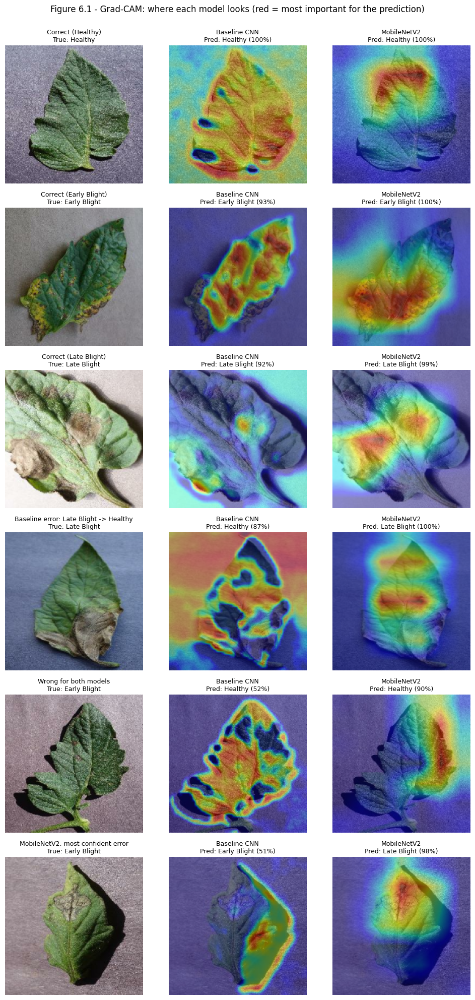

In [ ]:
# Author: Abrar
# Cell 9.3 - Grad-CAM for Both Models (Figure 6.1)

def make_baseline_gradcam_model(model, layer_name="conv3"):
    # Re-connects the trained baseline layers so one call returns [conv3 feature maps, probabilities]
    inputs = tf.keras.Input(shape=(224, 224, 3))
    x, feature_maps = inputs, None
    for layer in model.layers:
        x = layer(x, training=False)          # augmentation is inactive with training=False
        if layer.name == layer_name:
            feature_maps = x
    return tf.keras.Model(inputs, [feature_maps, x])


# Baseline: last conv layer 'conv3'. MobileNetV2: Member 2's activation model from Cell 7.6 ('out_relu')
m3_gradcam_models = {"Baseline CNN": make_baseline_gradcam_model(baseline_model),
                     "MobileNetV2": make_activation_model(improved_model)}


def gradcam(gradcam_model, image, class_index=None):
    # Grad-CAM heatmap (0-1, 224x224) for the predicted class (or class_index)
    x = tf.expand_dims(image, 0)
    with tf.GradientTape() as tape:
        feature_maps, probabilities = gradcam_model(x, training=False)
        if class_index is None:
            class_index = int(tf.argmax(probabilities[0]))
        class_score = probabilities[:, class_index]
    gradients = tape.gradient(class_score, feature_maps)          # d(score) / d(feature maps)
    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))           # one weight per feature map
    cam = tf.nn.relu(tf.reduce_sum(feature_maps[0] * weights, axis=-1))   # keep positive evidence only
    cam = cam / (tf.reduce_max(cam) + 1e-8)                       # scale to 0-1
    cam = tf.image.resize(cam[..., tf.newaxis], (224, 224))[..., 0]
    return cam.numpy(), class_index, probabilities[0].numpy()


# Check: the Grad-CAM models give the same predictions as the real models
for m3_name, m3_gc_model in m3_gradcam_models.items():
    m3_check_image, _ = load_and_preprocess(tf.constant(test_df["image_path"].iloc[0]), 0)
    _, m3_check_probs = m3_gc_model(tf.expand_dims(m3_check_image, 0), training=False)
    print(f"{m3_name}: same prediction as the full model:",
          np.allclose(m3_check_probs.numpy()[0], m3_results[m3_name]["prob"][0], atol=1e-4))

# Leaves to explain: one leaf per class that both models got right, plus the most informative errors
m3_r_base, m3_r_mob = m3_results["Baseline CNN"], m3_results["MobileNetV2"]
m3_both_right = np.where((m3_r_base["pred"] == m3_r_base["true"]) & (m3_r_mob["pred"] == m3_r_mob["true"]))[0]
m3_cases = [(int(m3_both_right[m3_r_base["true"][m3_both_right] == c][0]), f"Correct ({CLASS_NAMES[c]})") for c in range(3)]
m3_late_as_healthy = np.where((m3_r_base["true"] == 2) & (m3_r_base["pred"] == 0))[0]
if len(m3_late_as_healthy):
    m3_cases.append((int(m3_late_as_healthy[0]), "Baseline error: Late Blight -> Healthy"))
for i in m3_both_wrong:
    m3_cases.append((i, "Wrong for both models"))
m3_mob_err = np.where(m3_r_mob["pred"] != m3_r_mob["true"])[0]
m3_cases.append((int(m3_mob_err[np.argmax(m3_r_mob["prob"][m3_mob_err].max(axis=1))]), "MobileNetV2: most confident error"))

# Figure 6.1: original leaf | baseline Grad-CAM | MobileNetV2 Grad-CAM
fig, axes = plt.subplots(len(m3_cases), 3, figsize=(10, 3.3 * len(m3_cases)))
for row, (i, label) in enumerate(m3_cases):
    image, _ = load_and_preprocess(tf.constant(test_df["image_path"].iloc[i]), 0)
    axes[row, 0].imshow(image.numpy())
    axes[row, 0].set_title(f"{label}\nTrue: {CLASS_NAMES[int(test_df['label_id'].iloc[i])]}", fontsize=9)
    for col, (m3_name, m3_gc_model) in enumerate(m3_gradcam_models.items(), start=1):
        cam, predicted, probs = gradcam(m3_gc_model, image)
        axes[row, col].imshow(image.numpy())
        axes[row, col].imshow(cam, cmap="jet", alpha=0.45)
        axes[row, col].set_title(f"{m3_name}\nPred: {CLASS_NAMES[predicted]} ({probs[predicted]:.0%})", fontsize=9)
    for ax in axes[row]:
        ax.axis("off")
plt.suptitle("Figure 6.1 - Grad-CAM: where each model looks (red = most important for the prediction)", y=1.0)
plt.tight_layout()
plt.savefig(FIGURES_PATH / "fig6_1_gradcam_test_leaves.png", dpi=130, bbox_inches="tight")
plt.show()

### 9.4 Interpretability findings (Figure 6.1)

**MobileNetV2 looks at the leaf; the baseline often does not.** For the correctly classified Late Blight leaf, MobileNetV2's heatmap is centred on the two brown lesions, while the baseline's strongest evidence is on the background near the leaf edge: a correct prediction, possibly for the wrong reason. For the Healthy leaf, the baseline's heatmap spreads over the leaf *and* the background, while MobileNetV2 concentrates on the leaf blade.

**The baseline's most costly error is a background shortcut.** For the Late Blight leaf photographed on a blue background (predicted Healthy, 87%), the baseline's heatmap is strongest on the **blue background**, not on the large lesion. This confirms the suspicion from 9.2: the baseline has partly learned background colour, which is a serious generalisation risk for photos taken in a field. MobileNetV2 focuses on the leaf and classifies the same image correctly.

**Errors that remain.** On the early-stage Early Blight leaf missed by both models, neither heatmap is on the tiny dark spots, so the lesions were too small to drive the prediction. MobileNetV2's most confident error (Early Blight predicted as Late Blight, 98%) shows the heatmap **on the large central lesion**: the model looked at the right place but interpreted the lesion as Late Blight, which agrees with the visual similarity of the two blights.

**Limitations of Grad-CAM.** The heatmaps are qualitative and cover only six leaves. MobileNetV2's last feature map is 7 × 7, so its heatmaps are coarse; the baseline's `conv3` map is finer. Grad-CAM shows where the evidence for a class lies, not *why* the model trusts it. We used the **softmax probability** of the predicted class as the score (Selvaraju et al., 2017, use the pre-softmax score). When a prediction is almost 100% confident the softmax saturates and the gradients become very small; the maps are normalised to 0 – 1, so they stay readable, but they can look noisier for such images.

Image: /content/IT8414_Tomato_Project/data/selected/Tomato___Late_blight/7d9f4bd8-6a41-4c5e-816e-175f88e0be41___RS_Late.B 5488.JPG
Baseline CNN  Healthy: 6.5% | Early Blight: 69.4% | Late Blight: 24.1%
MobileNetV2   Healthy: 0.0% | Early Blight: 21.5% | Late Blight: 78.5%


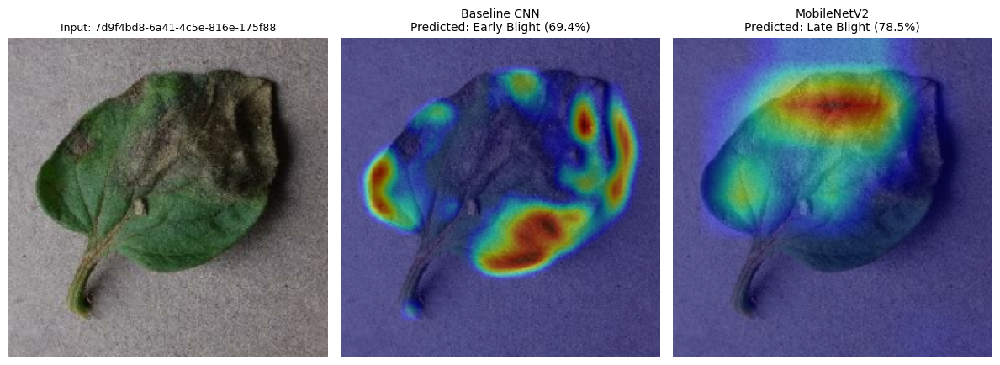

In [ ]:
# Author: Abrar
# Cell 9.5 - Live Demo: Predict and Explain Any Leaf Photo (both models + Grad-CAM)

def predict_and_explain(image_path):
    # Same preprocessing as training: decode RGB (JPG/PNG, any size), resize to 224x224, scale to 0-1
    image, _ = load_and_preprocess(tf.constant(str(image_path)), 0)
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
    axes[0].imshow(image.numpy())
    axes[0].set_title(f"Input: {Path(image_path).name[:30]}", fontsize=9)
    for ax, (m3_name, m3_gc_model) in zip(axes[1:], m3_gradcam_models.items()):
        cam, predicted, probs = gradcam(m3_gc_model, image)
        ax.imshow(image.numpy())
        ax.imshow(cam, cmap="jet", alpha=0.45)
        ax.set_title(f"{m3_name}\nPredicted: {CLASS_NAMES[predicted]} ({probs[predicted]:.1%})", fontsize=10)
        print(f"{m3_name:13s} " + " | ".join(f"{c}: {p:.1%}" for c, p in zip(CLASS_NAMES, probs)))
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


# ---- Choose the image ----
# Option 1 (default): a test image. Option 2: type the path of any leaf photo (JPG or PNG).
# Option 3 (Colab): set UPLOAD_IMAGE = True and pick a photo from your computer.
DEMO_IMAGE = test_df["image_path"].iloc[0]
UPLOAD_IMAGE = False

if UPLOAD_IMAGE and IN_COLAB:
    m3_uploaded = files.upload()
    DEMO_IMAGE = str(Path.cwd() / next(iter(m3_uploaded)))

print("Image:", DEMO_IMAGE)
predict_and_explain(DEMO_IMAGE)

## 10.0 Conclusion

**Summary of findings.** Two models were compared on the same held-out test set of 30 images:

| Model | Accuracy | Macro F1 | Late Blight recall | Diseased → Healthy errors | ROC-AUC | Params | Train time* |
|---|---|---|---|---|---|---|---|
| Baseline CNN | 80.0% | 79.4% | 60% | 3 | 0.895 | 101,699 | 0.3 min |
| MobileNetV2 | 83.3% | 83.1% | **90%** | **1** | **0.963** | 2,261,827 | 1.3 min |

Overall accuracy differs by only one image, and the confidence intervals overlap, so accuracy alone cannot separate the models. The difference is in the costly errors: MobileNetV2 found 9 of 10 Late Blight leaves (baseline 6), never predicted a Late Blight leaf as Healthy, and its Grad-CAM heatmaps focus on the leaf and its lesions, whereas the baseline sometimes relied on the background.

**Deployment recommendation: MobileNetV2.** It performs best on the metric that matters most for a screening tool (missed diseased leaves), and its predictions are based on visible disease symptoms. It is about 22 times larger than the baseline, but MobileNetV2 was designed for mobile devices and the saved model is about 21 MB. It should be deployed as a **decision-support tool**, with low-confidence predictions referred to an expert, not as an automatic diagnosis.

**Limitations.** The test set has only 30 images (one image = 3.3 percentage points). All images come from PlantVillage, photographed in controlled conditions on plain backgrounds, so performance on field photos is unknown. Early-stage disease with very small lesions was missed by both models.

**Ethics, privacy and bias.**
- **Dataset bias.** Every image comes from PlantVillage: single leaves photographed in a lab on plain backgrounds, from a limited set of tomato varieties and growing conditions. Grad-CAM (9.4) showed that the baseline partly learned the background colour, so this bias is real, not hypothetical. The tool must not be described as accurate for field photos, other varieties or other lighting until it has been tested on them.
- **Harm from errors.** A diseased leaf predicted as Healthy can delay treatment and let Late Blight spread to the rest of the field and to neighbouring farms; a false alarm leads to unnecessary fungicide use, which costs money and harms the environment. The tool should therefore show its confidence, refer uncertain cases to an agronomist, and state clearly that the treatment decision stays with the farmer or expert.
- **Privacy.** Photos taken on a phone can carry GPS location and time in their metadata, which can reveal where a farm is and that it has an outbreak (commercially sensitive). Metadata should be removed, images should be processed on the device where possible (MobileNetV2 is small enough), and farmers should give consent before any image is stored or used for retraining. The PlantVillage images themselves contain no personal data and are used under their licence with credit (2.0).
- **Fair access.** A phone-based tool helps only farmers who have a smartphone. An offline, on-device model and an interface in the local language (for example Arabic) would make it usable in rural areas with poor connectivity.

**Future work.**
1. Evaluate on a much larger test set: only 300 of the 3,600 downloaded tomato images were used.
2. Test on real field photos (for example the PlantDoc dataset) to measure generalisation.
3. Reduce background shortcuts with background augmentation or leaf segmentation.
4. Use higher input resolution or crops to detect small early-stage lesions.
5. Calibrate a confidence threshold for human review on validation data.


\* *Training times were measured on different hardware (baseline: T4 GPU; MobileNetV2: CPU, stage 1 + stage 2), so they are not directly comparable. On the same hardware MobileNetV2 would be relatively faster than shown, so the size and time cost of the recommended model is, if anything, overstated here.*